# Сравнение методов первого и второго порядка

## Классификация с нелинейными взаимодействиями

**Цель работы**

Исследовать эффективность градиентных методов
первого и второго порядка при обучении нейронной
сети для бинарной классификации.

Сравнить качество классификации, скорость сходимости,
устойчивость относительно начальной инициализации
и вычислительные затраты четырёх оптимизаторов:
AdamW, RMSProp, BFGS и Generalized Gauss–Newton.

## Постановка задачи

Исходные признаки генерируются независимо
из равномерного распределения:

$$
X\in\mathbb{R}^{420\times2},
\qquad x_{ij}\sim U(-1.5,1.5).
$$

Вероятность принадлежности наблюдения
к положительному классу определяется выражением:

$$
p_i=\sigma\left(
1.5\sin(2x_{i1})+
0.8x_{i1}x_{i2}-
0.6x_{i2}
\right),
$$

где $\sigma$ — сигмоидальная функция:

$$
\sigma(u)=\frac{1}{1+e^{-u}}.
$$

Целевая переменная генерируется согласно
распределению Бернулли:

$$
y_i\sim\operatorname{Bernoulli}(p_i),
\qquad y_i\in\{0,1\}.
$$

Сначала генерируется матрица признаков,
затем бинарная целевая переменная.

Для воспроизводимости используется
numpy.random.default_rng(911).

## Параметры эксперимента

| Параметр | Значение |
|---|---|
| Тип задачи | Бинарная классификация |
| Количество наблюдений | 420 |
| Количество признаков | 2 |
| Распределение признаков | $U(-1.5,1.5)$ |
| Seed генерации данных | 911 |
| Random state разбиения | 1011 |
| Seed инициализации сети | 1, 2, 3 |
| Архитектура сети | 2 → 8 → 1 |
| Активация скрытого слоя | Tanh |
| Активация выходного слоя | Sigmoid |
| Инициализация весов | Xavier Uniform |
| Инициализация смещений | Нулевая |
| Функция потерь | Binary Cross-Entropy |
| Количество оптимизаторов | 4 |
| Внешние итерации | 100 |
| Повторения каждого метода | 3 |
| Количество основных запусков | 12 |
| Вычислительная точность | float64 |
| Режим обучения | Полная обучающая выборка |
| Вычислительное устройство | CPU |

## Исследуемые методы оптимизации

| Метод | Группа | Используемая информация |
|---|---|---|
| AdamW | Первый порядок | Первый и второй моменты градиента |
| RMSProp | Первый порядок | Экспоненциальное среднее квадратов градиента |
| BFGS | Квазиньютоновский метод | Приближение обратной матрицы Гессе |
| Generalized Gauss–Newton | Второй порядок | Якобиан логитов и кривизна функции потерь |

В рамках данного задания BFGS относится
к группе методов второго порядка.

AdamW используется без weight decay,
согласно установленным условиям сравнения.

## Гиперпараметры оптимизаторов

**AdamW**

$$
\eta=0.02,\qquad
\beta_1=0.9,\qquad
\beta_2=0.99,
$$

$$
\varepsilon=10^{-8},
\qquad \lambda=0.
$$

Первый и второй моменты инициализируются
нулевыми векторами.

**RMSProp**

$$
\eta=0.01,\qquad
\beta=0.9,\qquad
\varepsilon=10^{-8}.
$$

Начальное состояние накопленной статистики
квадратов градиента равно нулю.

Используется базовая версия RMSProp
без momentum и центрирования.

**BFGS**

Начальная обратная аппроксимация матрицы Гессе:

$$
H_0=I.
$$

Для выбора величины шага используется
обратный поиск Армихо:

$$
\alpha_0=1,\qquad
c_1=10^{-4},\qquad
\rho=0.5.
$$

Максимальное количество проб — 20.

В качестве дополнительного условия численной
устойчивости обновление обратной аппроксимации
пропускается при

$$
s_t^Ty_t\leq10^{-10}.
$$

**Generalized Gauss–Newton**

Параметр регуляризации матрицы кривизны:

$$
\mu=0.1.
$$

Для выбора величины шага используется
поиск Армихо с параметрами:

$$
\alpha_0=1,\qquad
c_1=10^{-4},\qquad
\rho=0.5.
$$

Максимальное количество проб — 20.

Регуляризация матрицы кривизны не является
регуляризацией весов нейронной сети.

Если условие Армихо не выполняется за 20 проб,
внешний шаг отклоняется, а параметры сети
остаются неизменными.

## Разделение выборки

| Выборка | Доля | Количество наблюдений | Назначение |
|---|---:|---:|---|
| Train | 70% | 294 | Обучение сети |
| Validation | 15% | 63 | Выбор лучшей итерации |
| Test | 15% | 63 | Независимая итоговая оценка |

Сначала выделяется тестовая выборка размером
15% от исходных данных.

Затем из оставшейся части выделяется
валидационная выборка в доле 15/85.

Для обоих разбиений используется
random_state = 1011.

Разбиения выполняются со стратификацией
по бинарной целевой переменной.

## Организация сравнительного эксперимента

Для каждого оптимизатора выполняются
три независимых запуска с начальными
seed нейронной сети 1, 2 и 3.

Внутри каждого повторения все четыре метода
получают одинаковые:

- обучающую выборку;
- валидационную выборку;
- тестовую выборку;
- архитектуру нейронной сети;
- начальные параметры;
- функцию потерь;
- вычислительную точность;
- количество внешних итераций.

В каждом запуске используется полный градиент
обучающей функции потерь.

Мини-батчи не применяются.

Результаты представляются в виде среднего
значения и выборочного стандартного отклонения
по трём повторениям.

## Критерии сравнительной оценки

**Качество оптимизации**

- Train loss после 100 итераций.
- Validation loss после 100 итераций.
- Минимальный достигнутый validation loss.
- Норма полного градиента.
- Норма изменения параметров сети.
- Количество принятых и отклонённых шагов.

**Скорость достижения заданного качества**

До проведения эксперимента фиксируется
единый контрольный уровень:

$$
L_{\mathrm{val}}\leq0.60.
$$

Для каждого метода определяется первая итерация,
на которой выполнено данное условие.

Дополнительно учитываются накопленные
вычислительные операции и время достижения
контрольного уровня.

Если заданный уровень качества не достигнут,
это фиксируется в результатах без изменения
порога после завершения эксперимента.

**Качество классификации**

- Binary Cross-Entropy.
- Accuracy.
- F1-macro.
- ROC-AUC.

Итоговое состояние сети в каждом запуске
выбирается по минимальному validation loss.

Тестовая выборка используется только после
выбора итогового состояния.

**Вычислительные затраты**

- Количество вычислений функции потерь.
- Количество вычислений полного градиента.
- Количество вычислений внутри поиска Армихо.
- Количество построений якобиана.
- Количество сборок матриц кривизны.
- Количество обновлений обратной аппроксимации.
- Количество матричных факторизаций.
- Количество решений линейных систем.
- Время выполнения.
- Пиковая дополнительная память.
- Размер внутреннего состояния оптимизатора.

Основные операции оптимизаторов и дополнительные
диагностические вычисления учитываются отдельно.

## Условия реализации

Все четыре оптимизатора реализуются самостоятельно.

PyTorch используется для построения нейронной сети,
автоматического дифференцирования и операций
линейной алгебры.

Для бинарной классификации применяется
численно устойчивая функция потерь
BCEWithLogitsLoss.

Обучение выполняется без dropout, batch normalization
и дополнительной регуляризации весов.

При отклонении шага, возникновении нечисловых
значений или расходимости соответствующее событие
фиксируется в истории эксперимента.

Автоматические перезапуски и необоснованное
изменение гиперпараметров не выполняются.

## Исследовательские вопросы

1. Какой метод обеспечивает наиболее быстрое
   уменьшение функции потерь по числу итераций?

2. Какой метод достигает заданного уровня качества
   за наименьшее вычислительное время?

3. Компенсирует ли использование информации
   о кривизне дополнительные вычислительные затраты
   методов второго порядка?

4. Насколько результаты оптимизации зависят
   от начальной инициализации нейронной сети?

5. Сопровождается ли уменьшение обучающих потерь
   улучшением качества на независимых данных?

## Математическая структура нейронной сети

Используется полносвязная нейронная сеть
с одним скрытым слоем:

$$
2\rightarrow8\rightarrow1.
$$

Входной вектор:

$$
x_i=(x_{i1},x_{i2})^T\in\mathbb{R}^2.
$$

**Скрытый слой**

$$
a_i=W_1x_i+b_1,
$$

$$
h_i=\tanh(a_i).
$$

Гиперболический тангенс и его производная:

$$
\tanh(u)=\frac{e^u-e^{-u}}{e^u+e^{-u}},
$$

$$
\tanh'(u)=1-\tanh^2(u).
$$

**Выходной слой**

$$
z_i=W_2h_i+b_2,
$$

где $z_i$ — логит нейронной сети.

Вероятность принадлежности к положительному классу:

$$
\hat p_i=\sigma(z_i)=\frac{1}{1+e^{-z_i}}.
$$

Производная сигмоидальной функции:

$$
\sigma'(z_i)=\hat p_i(1-\hat p_i).
$$

Прогнозируемый класс определяется по порогу 0.5:

$$
\hat y_i=
\begin{cases}
1, & \hat p_i\geq0.5,\\
0, & \hat p_i<0.5.
\end{cases}
$$

## Параметры нейронной сети

| Параметр | Размерность | Количество элементов |
|---|---|---:|
| $W_1$ | $8\times2$ | 16 |
| $b_1$ | $8$ | 8 |
| $W_2$ | $1\times8$ | 8 |
| $b_2$ | $1$ | 1 |
| Всего | | 33 |

Все обучаемые параметры объединяются
в единый вектор:

$$
\theta=
\begin{pmatrix}
\operatorname{vec}(W_1)\\
b_1\\
\operatorname{vec}(W_2)\\
b_2
\end{pmatrix}
\in\mathbb{R}^{33}.
$$

Единое векторное представление используется
во всех четырёх оптимизаторах.

**Инициализация Xavier Uniform**

$$
W_{ij}\sim U\left(
-\sqrt{\frac{6}{n_{in}+n_{out}}},
\sqrt{\frac{6}{n_{in}+n_{out}}}
\right).
$$

Для первого слоя:

$$
W_{1,ij}\sim U\left(
-\sqrt{\frac{6}{10}},
\sqrt{\frac{6}{10}}
\right).
$$

Для второго слоя:

$$
W_{2,ij}\sim U\left(
-\sqrt{\frac{6}{9}},
\sqrt{\frac{6}{9}}
\right).
$$

Смещения инициализируются нулями:

$$
b_1=0_8,\qquad b_2=0.
$$

Для каждого повторения формируется один начальный
вектор параметров, который используется всеми
четырьмя оптимизаторами.

## Целевая функция

В качестве функции потерь применяется бинарная
кросс-энтропия:

$$
L(\theta)=
-\frac{1}{n}
\sum_{i=1}^{n}
\left[
y_i\ln\hat p_i+
(1-y_i)\ln(1-\hat p_i)
\right].
$$

Для повышения численной устойчивости используется
эквивалентное выражение через логиты:

$$
L(\theta)=
\frac{1}{n}
\sum_{i=1}^{n}
\left[
\max(z_i,0)-y_iz_i+
\ln(1+e^{-|z_i|})
\right].
$$

В программной реализации применяется
BCEWithLogitsLoss.

Нейронная сеть возвращает логиты, а сигмоидальная
функция применяется отдельно при вычислении
вероятностей и прогнозируемых классов.

Это позволяет избежать численных ошибок при
логарифмировании вероятностей, близких к нулю
или единице.

Оптимизация проводится по полной обучающей выборке:

$$
L_{\mathrm{train}}(\theta)=
\frac{1}{294}
\sum_{i\in I_{\mathrm{train}}}
\ell(z_i,y_i).
$$

Требуется найти параметры, минимизирующие
обучающую функцию потерь:

$$
\min_{\theta\in\mathbb{R}^{33}}
L_{\mathrm{train}}(\theta).
$$

## Градиент функции потерь

Производная индивидуальной бинарной кросс-энтропии
по логиту:

$$
\frac{\partial\ell_i}{\partial z_i}
=\hat p_i-y_i.
$$

По правилу дифференцирования сложной функции:

$$
\nabla_\theta\ell_i=
(\hat p_i-y_i)\nabla_\theta z_i.
$$

Полный градиент обучающей функции потерь:

$$
g_t=
\nabla_\theta L_{\mathrm{train}}(\theta_t)
=
\frac{1}{294}
\sum_{i\in I_{\mathrm{train}}}
(\hat p_i-y_i)\nabla_\theta z_i.
$$

Для оценки сходимости используется евклидова
норма градиента:

$$
\|g_t\|_2=
\sqrt{
\sum_{j=1}^{33}
\left(
\frac{\partial L_{\mathrm{train}}}
{\partial\theta_j}
\right)^2
}.
$$

Полный градиент вычисляется с помощью
автоматического дифференцирования PyTorch.

## Якобиан логитов

Для метода Generalized Gauss–Newton дополнительно
используется матрица Якоби логитов по параметрам
нейронной сети:

$$
J=
\frac{\partial z}{\partial\theta}
\in\mathbb{R}^{294\times33},
$$

где

$$
J_{ij}=\frac{\partial z_i}{\partial\theta_j}.
$$

В матричной форме полный градиент записывается как:

$$
g_t=\frac{1}{n_{\mathrm{train}}}
J^T(\hat p-y).
$$

Вторая производная индивидуальной функции
потерь по логиту:

$$
\frac{\partial^2\ell_i}{\partial z_i^2}
=\hat p_i(1-\hat p_i).
$$

Эта величина используется при построении
обобщённой матрицы Гаусса — Ньютона.

## Метрики качества классификации

**Accuracy**

Доля правильно классифицированных наблюдений:

$$
\operatorname{Accuracy}=
\frac{TP+TN}{TP+TN+FP+FN}.
$$

Здесь:

- TP — правильно определённые положительные классы;
- TN — правильно определённые отрицательные классы;
- FP — ложноположительные прогнозы;
- FN — ложноотрицательные прогнозы.

**F1-macro**

Для каждого класса рассчитываются точность
и полнота:

$$
\operatorname{Precision}_c=
\frac{TP_c}{TP_c+FP_c},
$$

$$
\operatorname{Recall}_c=
\frac{TP_c}{TP_c+FN_c}.
$$

F1-мера для отдельного класса:

$$
F1_c=
\frac{
2\operatorname{Precision}_c\operatorname{Recall}_c
}{
\operatorname{Precision}_c+\operatorname{Recall}_c
}.
$$

При нулевом знаменателе соответствующая
метрика принимается равной нулю.

Макроусреднённая F1-мера:

$$
F1_{\mathrm{macro}}=
\frac{F1_0+F1_1}{2}.
$$

Оба класса имеют одинаковый вес независимо
от количества наблюдений в каждом классе.

**ROC-AUC**

Площадь под ROC-кривой:

$$
\operatorname{ROC\text{-}AUC}
=
\int_0^1 TPR(FPR)\,dFPR,
$$

где

$$
TPR=\frac{TP}{TP+FN},
\qquad
FPR=\frac{FP}{FP+TN}.
$$

ROC-AUC характеризует способность модели
различать положительный и отрицательный классы
при изменении порога классификации.

В отличие от accuracy и F1-macro, ROC-AUC
рассчитывается по прогнозируемым вероятностям,
а не по классам, полученным при пороге 0.5.

## Выбор итогового состояния сети

Для каждого метода и каждой инициализации
лучшая итерация определяется независимо:

$$
t^*=
\arg\min_{t\in\{0,\ldots,100\}}
L_{\mathrm{val}}(\theta_t).
$$

Тестовые метрики вычисляются для параметров
$\theta_{t^*}$ после завершения оптимизации.

Дополнительно сравнивается качество методов
непосредственно после 100 внешних итераций,
независимо от положения лучшей итерации.

## Особенности синтетической задачи

Целевая переменная генерируется случайным образом
согласно распределению Бернулли.

Поэтому даже точное восстановление исходных
вероятностей не гарантирует правильной
классификации всех наблюдений.

Нулевые потери и accuracy, равная 100%,
не являются обязательными признаками успешной
оптимизации.

Необходимо отдельно оценивать уменьшение функции
потерь, сходимость оптимизатора и способность
нейронной сети обобщать зависимость
на независимых данных.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from time import perf_counter
import tracemalloc

# Вычислительная среда
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)

device = torch.device("cpu")

# Параметры генерации данных
n = 420
n_features = 2

seed = 911
split_seed = seed + 100

# Архитектура нейронной сети
input_size = 2
hidden_size = 8
output_size = 1

# Параметры сравнительного эксперимента
iterations = 100
network_seeds = [1, 2, 3]
n_repeats = len(network_seeds)

quality_threshold = 0.60

methods = [
    "AdamW",
    "RMSProp",
    "BFGS",
    "GGN"
]

# Общие настройки оптимизаторов
config = {
    "AdamW": {
        "eta": 0.02,
        "beta1": 0.9,
        "beta2": 0.99,
        "eps": 1e-8,
        "weight_decay": 0.0
    },

    "RMSProp": {
        "eta": 0.01,
        "beta": 0.9,
        "eps": 1e-8,
        "weight_decay": 0.0
    },

    "BFGS": {
        "alpha0": 1.0,
        "c1": 1e-4,
        "rho": 0.5,
        "max_trials": 20,
        "curvature_tol": 1e-10
    },

    "GGN": {
        "mu": 0.1,
        "alpha0": 1.0,
        "c1": 1e-4,
        "rho": 0.5,
        "max_trials": 20
    }
}

# Генерация синтетических данных
rng = np.random.default_rng(seed)

X = rng.uniform(
    -1.5,
    1.5,
    size=(n, n_features)
)

# Истинные логиты
true_logits = (
    1.5 * np.sin(2 * X[:, 0])
    + 0.8 * X[:, 0] * X[:, 1]
    - 0.6 * X[:, 1]
)

# Истинные вероятности положительного класса
p_true = expit(true_logits)

# Генерация классов по распределению Бернулли
y = rng.binomial(
    n=1,
    p=p_true
).astype(np.float64)

# Индексы исходных наблюдений
indices = np.arange(n)

# Первое стратифицированное разбиение:
# 85% — train + validation, 15% — test
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=split_seed,
    shuffle=True,
    stratify=y
)

# Второе стратифицированное разбиение:
# 15/85 оставшейся выборки — validation
n_val = int(round(0.15 * n))

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=n_val,
    random_state=split_seed,
    shuffle=True,
    stratify=y[train_val_idx]
)

# Преобразование данных в тензоры PyTorch
def make_tensors(idx):

    X_tensor = torch.tensor(
        X[idx],
        dtype=torch.float64,
        device=device
    )

    y_tensor = torch.tensor(
        y[idx],
        dtype=torch.float64,
        device=device
    ).reshape(-1, 1)

    return X_tensor, y_tensor


X_train, y_train = make_tensors(train_idx)
X_val, y_val = make_tensors(val_idx)
X_test, y_test = make_tensors(test_idx)

# Проверки исходных данных
assert X.shape == (420, 2)

assert X.dtype == np.float64
assert y.dtype == np.float64

assert np.all((X >= -1.5) & (X <= 1.5))
assert np.all((p_true > 0) & (p_true < 1))
assert set(np.unique(y)) == {0.0, 1.0}

# Проверки размеров выборок
assert len(train_idx) == 294
assert len(val_idx) == 63
assert len(test_idx) == 63

# Проверка отсутствия пересечений
assert len(np.intersect1d(train_idx, val_idx)) == 0
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.intersect1d(val_idx, test_idx)) == 0

assert np.array_equal(
    np.sort(
        np.concatenate([
            train_idx,
            val_idx,
            test_idx
        ])
    ),
    indices
)

# Проверка точности и численной корректности
for tensor in [
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
]:

    assert tensor.dtype == torch.float64
    assert torch.isfinite(tensor).all()

# Проверка воспроизводимости генерации
rng_check = np.random.default_rng(seed)

X_check = rng_check.uniform(
    -1.5,
    1.5,
    size=(n, n_features)
)

p_check = expit(
    1.5 * np.sin(2 * X_check[:, 0])
    + 0.8 * X_check[:, 0] * X_check[:, 1]
    - 0.6 * X_check[:, 1]
)

y_check = rng_check.binomial(
    n=1,
    p=p_check
).astype(np.float64)

assert np.array_equal(X, X_check)
assert np.array_equal(y, y_check)

# Таблица исходных данных
data = pd.DataFrame({
    "x1": X[:, 0],
    "x2": X[:, 1],
    "true_logit": true_logits,
    "p_true": p_true,
    "y": y.astype(int)
})

data["split"] = ""

data.loc[train_idx, "split"] = "Train"
data.loc[val_idx, "split"] = "Validation"
data.loc[test_idx, "split"] = "Test"

print("Первые 10 наблюдений обучающей выборки:")

display(
    data.loc[train_idx].head(10).round(6)
)

# Характеристики выборок и распределение классов
split_records = []

for name, idx in [
    ("Все данные", indices),
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:

    class_0 = int(np.sum(y[idx] == 0))
    class_1 = int(np.sum(y[idx] == 1))

    assert class_0 > 0
    assert class_1 > 0

    split_records.append({
        "Выборка": name,
        "Количество наблюдений": len(idx),
        "Доля выборки": len(idx) / n,
        "Класс 0": class_0,
        "Класс 1": class_1,
        "Доля класса 0": class_0 / len(idx),
        "Доля класса 1": class_1 / len(idx)
    })

split_summary = pd.DataFrame(split_records)

print("\nХарактеристики выборок:")

display(
    split_summary.style
    .hide(axis="index")
    .format({
        "Доля выборки": "{:.2%}",
        "Доля класса 0": "{:.2%}",
        "Доля класса 1": "{:.2%}"
    })
)

# Размерности тензоров
print("\nРазмерности тензоров:")

print("X_train:", tuple(X_train.shape))
print("y_train:", tuple(y_train.shape))

print("X_val:", tuple(X_val.shape))
print("y_val:", tuple(y_val.shape))

print("X_test:", tuple(X_test.shape))
print("y_test:", tuple(y_test.shape))

# Настройки эксперимента
print("\nSeed генерации данных:", seed)
print("Seed разбиения:", split_seed)
print("Seed инициализации сети:", network_seeds)

print("\nКоличество методов:", len(methods))
print("Количество повторений:", n_repeats)
print("Итераций за один запуск:", iterations)
print("Количество основных запусков:", len(methods) * n_repeats)

print("Контрольный уровень validation loss:", quality_threshold)

print("\nВерсия PyTorch:", torch.__version__)
print("Тип данных:", X_train.dtype)
print("Устройство:", device)
print("Количество потоков:", torch.get_num_threads())

print("\nВсе проверки данных и воспроизводимости пройдены.")

Первые 10 наблюдений обучающей выборки:


,x1,x2,true_logit,p_true,y,split
255,-1.441364,-0.594721,0.658626,0.658952,0,Train
165,-0.601664,-1.167909,-0.136963,0.465813,1,Train
266,-1.078328,0.534097,-2.031059,0.115980,0,Train
45,0.988666,0.258115,1.427027,0.806438,0,Train
121,-0.512336,-0.397576,-0.880316,0.293112,0,Train
104,-0.533530,0.468382,-1.794624,0.142507,0,Train
28,1.283023,-1.338938,0.245493,0.561067,0,Train
194,-1.314058,0.787573,-2.037290,0.115343,0,Train
40,-0.991038,-0.408116,-0.806478,0.308641,1,Train
79,-0.465452,0.194266,-1.392136,0.199067,0,Train



Характеристики выборок:


Выборка,Количество наблюдений,Доля выборки,Класс 0,Класс 1,Доля класса 0,Доля класса 1
Все данные,420,100.00%,225,195,53.57%,46.43%
Train,294,70.00%,157,137,53.40%,46.60%
Validation,63,15.00%,34,29,53.97%,46.03%
Test,63,15.00%,34,29,53.97%,46.03%



Размерности тензоров:
X_train: (294, 2)
y_train: (294, 1)
X_val: (63, 2)
y_val: (63, 1)
X_test: (63, 2)
y_test: (63, 1)

Seed генерации данных: 911
Seed разбиения: 1011
Seed инициализации сети: [1, 2, 3]

Количество методов: 4
Количество повторений: 3
Итераций за один запуск: 100
Количество основных запусков: 12
Контрольный уровень validation loss: 0.6

Версия PyTorch: 2.15.0+cpu
Тип данных: torch.float64
Устройство: cpu
Количество потоков: 1

Все проверки данных и воспроизводимости пройдены.


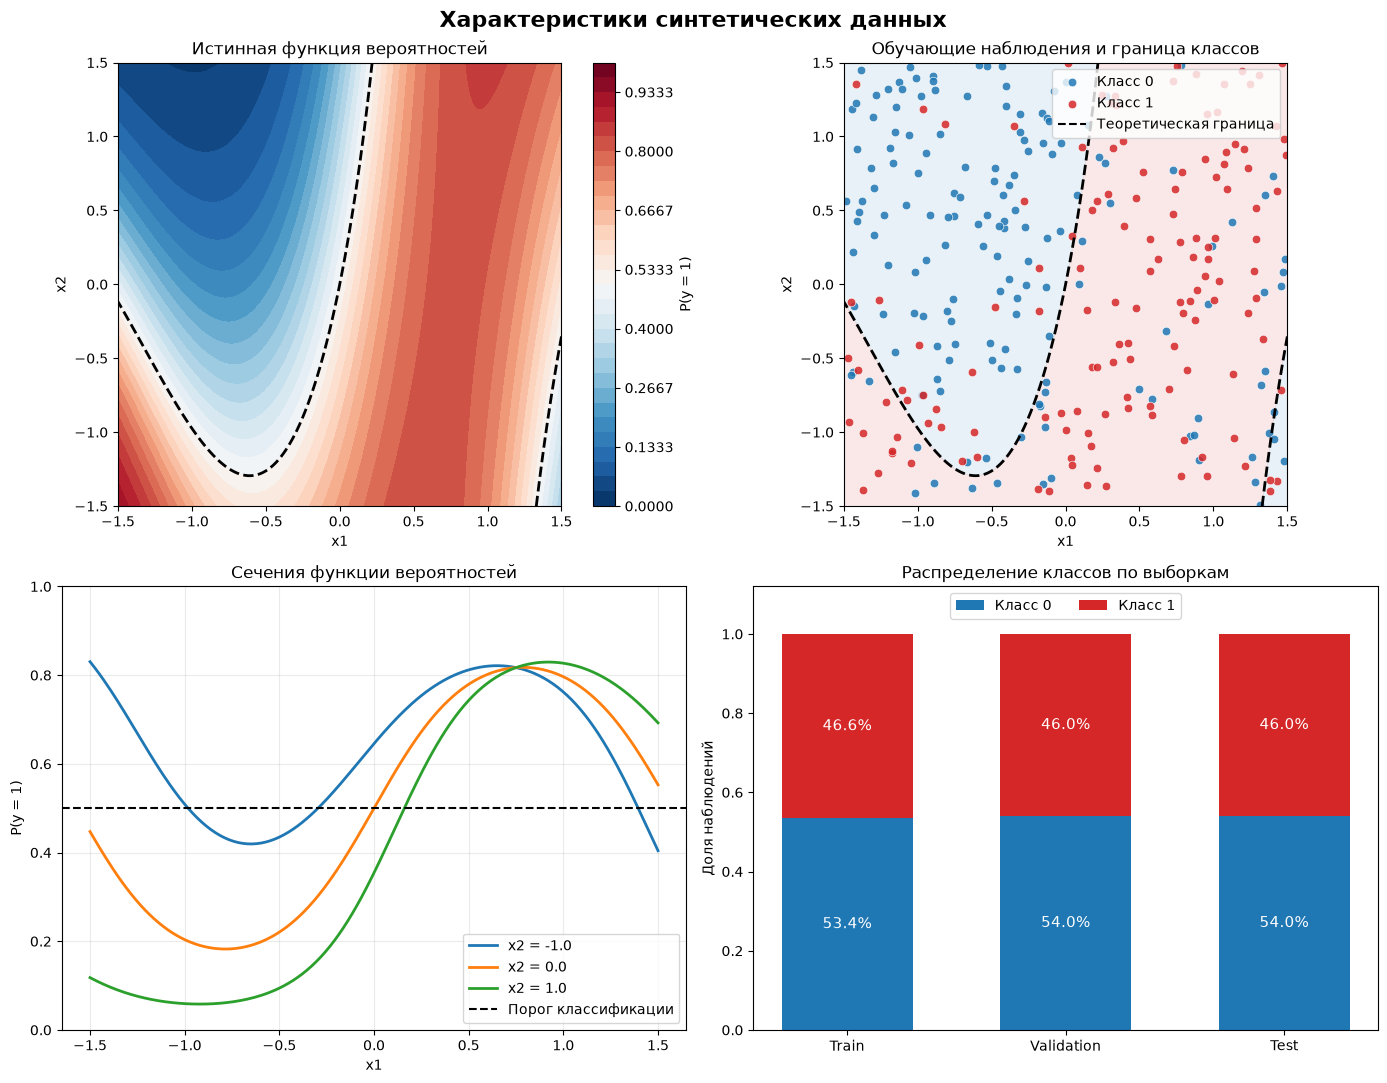

Теоретические характеристики задачи:
Ожидаемая точность оптимального классификатора: 73.6208%
Ожидаемая минимальная cross-entropy: 0.53342202
Cross-entropy при постоянной вероятности 0.5: 0.69314718


In [12]:
# Сетка пространства признаков
grid = np.linspace(-1.5, 1.5, 250)

X1_grid, X2_grid = np.meshgrid(grid, grid)

# Истинная функция вероятностей
logits_grid = (
    1.5 * np.sin(2 * X1_grid)
    + 0.8 * X1_grid * X2_grid
    - 0.6 * X2_grid
)

P_grid = expit(logits_grid)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Истинные вероятности положительного класса
contour = axes[0, 0].contourf(
    X1_grid,
    X2_grid,
    P_grid,
    levels=np.linspace(0, 1, 31),
    cmap="RdBu_r"
)

fig.colorbar(
    contour,
    ax=axes[0, 0],
    label="P(y = 1)"
)

axes[0, 0].contour(
    X1_grid,
    X2_grid,
    P_grid,
    levels=[0.5],
    colors="black",
    linestyles="--",
    linewidths=2
)

axes[0, 0].set_title(
    "Истинная функция вероятностей"
)

# Обучающие наблюдения и граница классификации
axes[0, 1].contourf(
    X1_grid,
    X2_grid,
    P_grid,
    levels=[0, 0.5, 1],
    colors=["#1f77b4", "#d62728"],
    alpha=0.10
)

axes[0, 1].contour(
    X1_grid,
    X2_grid,
    P_grid,
    levels=[0.5],
    colors="black",
    linestyles="--",
    linewidths=2
)

class_colors = {
    0: "#1f77b4",
    1: "#d62728"
}

for class_id in [0, 1]:

    idx = train_idx[y[train_idx] == class_id]

    axes[0, 1].scatter(
        X[idx, 0],
        X[idx, 1],
        color=class_colors[class_id],
        edgecolor="white",
        linewidth=0.5,
        s=38,
        alpha=0.85,
        label=f"Класс {class_id}"
    )

axes[0, 1].plot(
    [],
    [],
    color="black",
    linestyle="--",
    label="Теоретическая граница"
)

axes[0, 1].set_title(
    "Обучающие наблюдения и граница классов"
)

axes[0, 1].legend()

# Сечения функции вероятностей
for x2_fixed in [-1.0, 0.0, 1.0]:

    p_section = expit(
        1.5 * np.sin(2 * grid)
        + 0.8 * grid * x2_fixed
        - 0.6 * x2_fixed
    )

    axes[1, 0].plot(
        grid,
        p_section,
        linewidth=2,
        label=f"x2 = {x2_fixed}"
    )

axes[1, 0].axhline(
    0.5,
    color="black",
    linestyle="--",
    label="Порог классификации"
)

axes[1, 0].set_xlabel("x1")
axes[1, 0].set_ylabel("P(y = 1)")
axes[1, 0].set_ylim(0, 1)

axes[1, 0].set_title(
    "Сечения функции вероятностей"
)

axes[1, 0].grid(alpha=0.25)
axes[1, 0].legend()

# Распределение классов по выборкам
split_names = ["Train", "Validation", "Test"]

class_0_shares = [
    np.mean(y[idx] == 0)
    for idx in [train_idx, val_idx, test_idx]
]

class_1_shares = [
    np.mean(y[idx] == 1)
    for idx in [train_idx, val_idx, test_idx]
]

bars_0 = axes[1, 1].bar(
    split_names,
    class_0_shares,
    color=class_colors[0],
    label="Класс 0",
    width=0.6
)

bars_1 = axes[1, 1].bar(
    split_names,
    class_1_shares,
    bottom=class_0_shares,
    color=class_colors[1],
    label="Класс 1",
    width=0.6
)

axes[1, 1].bar_label(
    bars_0,
    labels=[f"{v:.1%}" for v in class_0_shares],
    label_type="center",
    color="white",
    fontsize=11
)

axes[1, 1].bar_label(
    bars_1,
    labels=[f"{v:.1%}" for v in class_1_shares],
    label_type="center",
    color="white",
    fontsize=11
)

axes[1, 1].set_ylim(0, 1.12)
axes[1, 1].set_ylabel("Доля наблюдений")
axes[1, 1].set_title("Распределение классов по выборкам")

axes[1, 1].legend(
    loc="upper center",
    ncol=2
)

# Настройки карт пространства признаков
for ax in axes[0]:

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")

fig.suptitle(
    "Характеристики синтетических данных",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Теоретические характеристики задачи
p_train_true = p_true[train_idx]

# Ожидаемая точность оптимального классификатора
expected_bayes_accuracy = np.mean(
    np.maximum(
        p_train_true,
        1 - p_train_true
    )
)

# Ожидаемые потери при известных истинных вероятностях
expected_bayes_loss = -np.mean(
    p_train_true * np.log(p_train_true)
    + (1 - p_train_true) * np.log(1 - p_train_true)
)

print("Теоретические характеристики задачи:")

print(
    f"Ожидаемая точность оптимального классификатора: "
    f"{expected_bayes_accuracy:.4%}"
)

print(
    f"Ожидаемая минимальная cross-entropy: "
    f"{expected_bayes_loss:.8f}"
)

print(
    f"Cross-entropy при постоянной вероятности 0.5: "
    f"{np.log(2):.8f}"
)

In [13]:
class ClassificationNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):

        h = torch.tanh(self.fc1(x))

        return self.fc2(h)


def initialize_network(seed):

    torch.manual_seed(seed)

    model = ClassificationNetwork().to(
        device=device,
        dtype=torch.float64
    )

    with torch.no_grad():

        nn.init.xavier_uniform_(model.fc1.weight)
        nn.init.zeros_(model.fc1.bias)

        nn.init.xavier_uniform_(model.fc2.weight)
        nn.init.zeros_(model.fc2.bias)

    return model


# Преобразование параметров сети в единый вектор
def get_parameters(model):

    return torch.cat([
        parameter.detach().reshape(-1)
        for parameter in model.parameters()
    ]).clone()


# Размеры блоков параметров
w1_size = hidden_size * input_size
b1_size = hidden_size

w2_size = output_size * hidden_size
b2_size = output_size

n_parameters = (
    w1_size + b1_size + w2_size + b2_size
)

# Разделение вектора на матрицы и смещения
def unpack_parameters(theta):

    W1 = theta[:w1_size].reshape(
        hidden_size, input_size
    )

    b1 = theta[
        w1_size:w1_size + b1_size
    ]

    offset = w1_size + b1_size

    W2 = theta[
        offset:offset + w2_size
    ].reshape(output_size, hidden_size)

    b2 = theta[offset + w2_size:]

    return W1, b1, W2, b2


# Прямой проход через единый вектор параметров
def forward_logits(theta, X_data):

    W1, b1, W2, b2 = unpack_parameters(theta)

    hidden = torch.tanh(
        X_data @ W1.T + b1
    )

    logits = hidden @ W2.T + b2

    return logits


# Вероятности положительного класса
def predict_proba(theta, X_data):

    return torch.sigmoid(
        forward_logits(theta, X_data)
    )


# Численно устойчивая бинарная кросс-энтропия
loss_function = nn.BCEWithLogitsLoss(
    reduction="mean"
)


# Функция потерь для заданных параметров
def loss_value(theta, X_data, y_data):

    logits = forward_logits(theta, X_data)

    return loss_function(logits, y_data)


# Границы Xavier Uniform
xavier_bound_1 = np.sqrt(
    6 / (input_size + hidden_size)
)

xavier_bound_2 = np.sqrt(
    6 / (hidden_size + output_size)
)

# Сохранение начальных состояний
initial_parameters = {}

initial_records = []

for network_seed in network_seeds:

    model = initialize_network(network_seed)

    theta = get_parameters(model)

    initial_parameters[network_seed] = theta.clone()

    W1, b1, W2, b2 = unpack_parameters(theta)

    # Проверка количества параметров
    assert theta.numel() == 33
    assert theta.dtype == torch.float64

    # Проверка размерностей
    assert W1.shape == (8, 2)
    assert b1.shape == (8,)
    assert W2.shape == (1, 8)
    assert b2.shape == (1,)

    # Проверка нулевых смещений
    assert torch.all(b1 == 0)
    assert torch.all(b2 == 0)

    # Проверка границ Xavier Uniform
    assert torch.all(
        torch.abs(W1) <= xavier_bound_1
    )

    assert torch.all(
        torch.abs(W2) <= xavier_bound_2
    )

    # Проверка воспроизводимости инициализации
    control_model = initialize_network(network_seed)

    assert torch.equal(
        theta,
        get_parameters(control_model)
    )

    with torch.no_grad():

        # Сравнение двух форм прямого прохода
        logits_model = model(X_train)

        logits_vector = forward_logits(
            theta,
            X_train
        )

        assert torch.allclose(
            logits_model,
            logits_vector,
            atol=1e-12,
            rtol=1e-12
        )

        train_probabilities = predict_proba(
            theta,
            X_train
        )

        assert torch.all(
            (train_probabilities >= 0)
            & (train_probabilities <= 1)
        )

        train_loss_initial = loss_value(
            theta,
            X_train,
            y_train
        ).item()

        val_loss_initial = loss_value(
            theta,
            X_val,
            y_val
        ).item()

        train_accuracy_initial = (
            (train_probabilities >= 0.5)
            == y_train
        ).double().mean().item()

    initial_records.append({
        "Seed": network_seed,

        "Количество параметров": theta.numel(),

        "Норма начальных параметров": (
            torch.linalg.vector_norm(theta).item()
        ),

        "Train loss": train_loss_initial,

        "Validation loss": val_loss_initial,

        "Train accuracy": train_accuracy_initial,

        "Минимальная вероятность": (
            train_probabilities.min().item()
        ),

        "Максимальная вероятность": (
            train_probabilities.max().item()
        )
    })


# Проверка различий между инициализациями
for i, seed_i in enumerate(network_seeds):

    for seed_j in network_seeds[i + 1:]:

        assert not torch.equal(
            initial_parameters[seed_i],
            initial_parameters[seed_j]
        )


# Таблица начальных состояний
initial_df = pd.DataFrame(initial_records)

print("Архитектура нейронной сети:")
print(model)

print("\nКоличество обучаемых параметров:", n_parameters)

print("\nГраницы Xavier Uniform:")

print(
    f"W1: [{-xavier_bound_1:.8f}, "
    f"{xavier_bound_1:.8f}]"
)

print(
    f"W2: [{-xavier_bound_2:.8f}, "
    f"{xavier_bound_2:.8f}]"
)

print("\nХарактеристики начальных состояний:")

display(
    initial_df.style
    .hide(axis="index")
    .format({
        "Норма начальных параметров": "{:.8f}",
        "Train loss": "{:.8f}",
        "Validation loss": "{:.8f}",
        "Train accuracy": "{:.2%}",
        "Минимальная вероятность": "{:.8f}",
        "Максимальная вероятность": "{:.8f}"
    })
)

# Сравнение начальных векторов параметров
initial_theta_df = pd.DataFrame({
    f"Seed {s}": initial_parameters[s].numpy()
    for s in network_seeds
})

initial_theta_df.index = [
    f"theta_{j + 1}"
    for j in range(n_parameters)
]

print("\nНачальные векторы параметров:")

display(
    initial_theta_df.style.format("{:.8f}")
)

print("\nВсе проверки архитектуры пройдены.")
print("Три воспроизводимых начальных состояния сохранены.")

Архитектура нейронной сети:
ClassificationNetwork(
  (fc1): Linear(in_features=2, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=1, bias=True)
)

Количество обучаемых параметров: 33

Границы Xavier Uniform:
W1: [-0.77459667, 0.77459667]
W2: [-0.81649658, 0.81649658]

Характеристики начальных состояний:


Seed,Количество параметров,Норма начальных параметров,Train loss,Validation loss,Train accuracy,Минимальная вероятность,Максимальная вероятность
1,33,1.99526087,0.75062084,0.71683471,43.20%,0.30328055,0.69068000
2,33,1.91854415,0.69515597,0.68384807,55.44%,0.36218905,0.62887962
3,33,1.75880531,0.66887067,0.69375979,60.20%,0.26742813,0.73764499



Начальные векторы параметров:


,Seed 1,Seed 2,Seed 3
theta_1,0.65455374,-0.26798600,-0.62310556
theta_2,0.71933229,0.34825341,-0.57040502
theta_3,-0.50191028,-0.22285373,0.55839047
theta_4,0.70316962,-0.20216432,-0.48719021
theta_5,-0.28911126,0.53999704,-0.06524482
theta_6,-0.07064679,-0.17422312,-0.02380353
theta_7,-0.31672936,-0.55647036,0.63768163
theta_8,-0.48411135,-0.15396365,0.08178259
theta_9,-0.39774352,-0.74805972,-0.17099524
theta_10,-0.23346916,0.36728512,-0.16348854



Все проверки архитектуры пройдены.
Три воспроизводимых начальных состояния сохранены.


In [14]:
# Вычисление функции потерь
def evaluate_loss(theta, X_data, y_data):

    with torch.no_grad():

        return loss_value(
            theta,
            X_data,
            y_data
        ).item()


# Одновременное вычисление потерь и полного градиента
def evaluate_loss_gradient(theta, X_data, y_data):

    theta_variable = (
        theta.detach().clone().requires_grad_(True)
    )

    value = loss_value(
        theta_variable,
        X_data,
        y_data
    )

    gradient, = torch.autograd.grad(
        value,
        theta_variable
    )

    return value.item(), gradient.detach()


# Аналитический якобиан логитов
def logit_jacobian(theta, X_data):

    with torch.no_grad():

        W1, b1, W2, b2 = unpack_parameters(theta)

        # Прямой проход
        a = X_data @ W1.T + b1

        h = torch.tanh(a)

        logits = h @ W2.T + b2

        # Производная скрытой активации
        activation_derivative = 1 - h ** 2

        # Производная логитов по скрытым предактивациям
        delta = activation_derivative * W2.reshape(1, -1)

        # Производные по W1
        J_W1 = (
            delta[:, :, None] * X_data[:, None, :]
        ).reshape(len(X_data), -1)

        # Производные по b1
        J_b1 = delta

        # Производные по W2
        J_W2 = h

        # Производные по b2
        J_b2 = torch.ones(
            (len(X_data), 1),
            dtype=theta.dtype,
            device=theta.device
        )

        # Объединение блоков якобиана
        J = torch.cat(
            [J_W1, J_b1, J_W2, J_b2],
            dim=1
        )

    return logits, J


# Численный градиент методом центральных разностей
def numerical_gradient(theta, X_data, y_data, step=1e-5):

    gradient = torch.zeros_like(theta)

    for j in range(theta.numel()):

        direction = torch.zeros_like(theta)
        direction[j] = step

        loss_plus = evaluate_loss(
            theta + direction,
            X_data,
            y_data
        )

        loss_minus = evaluate_loss(
            theta - direction,
            X_data,
            y_data
        )

        gradient[j] = (
            loss_plus - loss_minus
        ) / (2 * step)

    return gradient


# Проверка всех трёх начальных состояний
gradient_check_records = []

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    # Градиент через автоматическое дифференцирование
    value, gradient_auto = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    # Градиент методом центральных разностей
    gradient_numeric = numerical_gradient(
        theta,
        X_train,
        y_train
    )

    # Аналитический якобиан логитов
    logits, J = logit_jacobian(
        theta,
        X_train
    )

    probabilities = torch.sigmoid(logits)

    # Градиент через матричную формулу
    gradient_jacobian = (
        J.T @ (probabilities - y_train)
    ).reshape(-1) / len(X_train)

    # Независимая проверка аналитического якобиана
    # на первых восьми обучающих наблюдениях
    J_auto = torch.autograd.functional.jacobian(
        lambda parameters: forward_logits(
            parameters,
            X_train[:8]
        ).reshape(-1),
        theta
    )

    J_analytic_subset = J[:8]

    # Расчёт погрешностей
    numeric_error = torch.max(
        torch.abs(
            gradient_auto - gradient_numeric
        )
    ).item()

    jacobian_gradient_error = torch.max(
        torch.abs(
            gradient_auto - gradient_jacobian
        )
    ).item()

    jacobian_error = torch.max(
        torch.abs(
            J_auto - J_analytic_subset
        )
    ).item()

    relative_error = (
        torch.linalg.vector_norm(
            gradient_auto - gradient_numeric
        )
        / max(
            torch.linalg.vector_norm(
                gradient_auto
            ).item(),
            1e-15
        )
    ).item()

    # Проверка размерностей
    assert J.shape == (294, 33)

    assert gradient_auto.shape == (33,)

    assert J.dtype == torch.float64
    assert gradient_auto.dtype == torch.float64

    # Проверка численной корректности
    assert torch.isfinite(J).all()
    assert torch.isfinite(gradient_auto).all()

    assert torch.allclose(
        gradient_auto,
        gradient_numeric,
        atol=1e-8,
        rtol=1e-6
    )

    assert torch.allclose(
        gradient_auto,
        gradient_jacobian,
        atol=1e-12,
        rtol=1e-10
    )

    assert torch.allclose(
        J_auto,
        J_analytic_subset,
        atol=1e-12,
        rtol=1e-10
    )

    gradient_check_records.append({
        "Seed": network_seed,

        "Train loss": value,

        "Норма градиента": (
            torch.linalg.vector_norm(
                gradient_auto
            ).item()
        ),

        "Погрешность центральных разностей": (
            numeric_error
        ),

        "Относительная погрешность": (
            relative_error
        ),

        "Погрешность градиента через J": (
            jacobian_gradient_error
        ),

        "Погрешность якобиана": (
            jacobian_error
        )
    })


gradient_check_df = pd.DataFrame(
    gradient_check_records
)

print("Проверка градиентов и якобиана:")

display(
    gradient_check_df.style
    .hide(axis="index")
    .format({
        "Train loss": "{:.10f}",
        "Норма градиента": "{:.10e}",
        "Погрешность центральных разностей": "{:.6e}",
        "Относительная погрешность": "{:.6e}",
        "Погрешность градиента через J": "{:.6e}",
        "Погрешность якобиана": "{:.6e}"
    })
)

print("\nРазмерность полного градиента:", gradient_auto.shape)
print("Размерность якобиана логитов:", J.shape)
print("Количество элементов якобиана:", J.numel())
print("Тип данных:", J.dtype)

print("\nВсе проверки градиентов и якобиана пройдены.")

Проверка градиентов и якобиана:


Seed,Train loss,Норма градиента,Погрешность центральных разностей,Относительная погрешность,Погрешность градиента через J,Погрешность якобиана
1,0.7506208357,3.0367485542e-01,9.909726e-12,9.370913e-11,8.326673e-17,0.000000e+00
2,0.6951559688,2.8170764797e-01,1.358567e-11,1.133194e-10,8.326673e-17,0.000000e+00
3,0.6688706746,2.0162622031e-01,7.226865e-12,1.115096e-10,2.081668e-17,0.000000e+00



Размерность полного градиента: torch.Size([33])
Размерность якобиана логитов: torch.Size([294, 33])
Количество элементов якобиана: 9702
Тип данных: torch.float64

Все проверки градиентов и якобиана пройдены.


## Математическая структура методов оптимизации

Обозначим полный градиент обучающей функции потерь:

$$
g_t=\nabla_\theta L_{\mathrm{train}}(\theta_t).
$$

Все методы работают с единым вектором параметров:

$$
\theta_t\in\mathbb{R}^{33}.
$$

Градиент вычисляется по всей обучающей выборке,
содержащей 294 наблюдения.

## AdamW

AdamW является адаптивным методом первого порядка,
использующим экспоненциальные скользящие средние
градиента и его квадрата.

Начальные состояния:

$$
m_0=0,\qquad v_0=0.
$$

На внешней итерации $t$, начиная с $t=0$,
вычисляются первый и второй моменты:

$$
m_{t+1}=\beta_1m_t+(1-\beta_1)g_t,
$$

$$
v_{t+1}=\beta_2v_t+(1-\beta_2)g_t^2.
$$

Возведение в квадрат выполняется покомпонентно.

**Коррекция смещения моментов**

$$
\hat m_{t+1}=
\frac{m_{t+1}}{1-\beta_1^{t+1}},
$$

$$
\hat v_{t+1}=
\frac{v_{t+1}}{1-\beta_2^{t+1}}.
$$

**Обновление параметров**

$$
\theta_{t+1}=
(1-\eta\lambda)\theta_t-
\eta\frac{\hat m_{t+1}}
{\sqrt{\hat v_{t+1}}+\varepsilon}.
$$

Параметры согласно заданию:

$$
\eta=0.02,\qquad
\beta_1=0.9,\qquad
\beta_2=0.99,
$$

$$
\varepsilon=10^{-8},
\qquad \lambda=0.
$$

Поскольку weight decay отключён, правило обновления
совпадает с базовым Adam:

$$
\theta_{t+1}=
\theta_t-
\eta\frac{\hat m_{t+1}}
{\sqrt{\hat v_{t+1}}+\varepsilon}.
$$

AdamW адаптирует величину обновления для каждого
параметра на основе накопленных статистик градиента.

## RMSProp

RMSProp является адаптивным методом первого порядка,
использующим экспоненциальное скользящее среднее
квадратов градиента.

Начальное состояние:

$$
v_0=0.
$$

**Обновление накопленной статистики**

$$
v_{t+1}=
\beta v_t+(1-\beta)g_t^2.
$$

**Обновление параметров**

$$
\theta_{t+1}=
\theta_t-
\eta\frac{g_t}{\sqrt{v_{t+1}}+\varepsilon}.
$$

Параметры согласно заданию:

$$
\eta=0.01,\qquad
\beta=0.9,\qquad
\varepsilon=10^{-8}.
$$

В данной реализации используется базовая версия
RMSProp без momentum, центрирования и коррекции
смещения накопленной статистики.

В отличие от AdamW, RMSProp не накапливает
первый момент градиента.

## BFGS

BFGS — квазиньютоновский метод, использующий
приближение обратной матрицы Гессе.

Начальная обратная аппроксимация:

$$
H_0=I_{33}.
$$

**Направление поиска**

$$
d_t=-H_tg_t.
$$

Величина шага $\alpha_t$ определяется
по условию Армихо.

После принятия шага:

$$
\theta_{t+1}=\theta_t+\alpha_td_t.
$$

**Формирование пары кривизны**

$$
s_t=\theta_{t+1}-\theta_t,
$$

$$
y_t=g_{t+1}-g_t.
$$

Условие положительной кривизны:

$$
s_t^Ty_t>0.
$$

Для численной устойчивости в данной реализации
используется дополнительный порог:

$$
s_t^Ty_t>10^{-10}.
$$

Для допустимой пары вычисляется:

$$
\rho_t=\frac{1}{y_t^Ts_t}.
$$

**Обновление обратной аппроксимации**

$$
H_{t+1}=
(I-\rho_ts_ty_t^T)
H_t
(I-\rho_ty_ts_t^T)
+\rho_ts_ts_t^T.
$$

При положительно определённой матрице $H_t$
и выполнении условия положительной кривизны
обновлённая матрица сохраняет положительную
определённость в точной арифметике.

Обновление удовлетворяет условию секущей:

$$
H_{t+1}y_t=s_t.
$$

Если условие сохранения пары не выполняется,
обратная аппроксимация остаётся неизменной:

$$
H_{t+1}=H_t.
$$

BFGS хранит полную матрицу обратной аппроксимации:

$$
H_t\in\mathbb{R}^{33\times33}.
$$

Явное вычисление матрицы Гессе не требуется.

## Generalized Gauss–Newton

Generalized Gauss–Newton (GGN) использует
приближение матрицы Гессе, построенное
на основе якобиана выходов нейронной сети
и кривизны функции потерь по этим выходам.

Для бинарной классификации выходом,
относительно которого вычисляется кривизна,
является логит $z_i$.

**Якобиан логитов**

$$
J_t=
\frac{\partial z(\theta_t)}
{\partial\theta}
\in\mathbb{R}^{294\times33}.
$$

Для скрытого нейрона $j$:

$$
h_{ij}=\tanh(a_{ij}).
$$

Аналитические производные логитов:

$$
\frac{\partial z_i}{\partial W_{1,jk}}
=
W_{2,j}(1-h_{ij}^2)x_{ik},
$$

$$
\frac{\partial z_i}{\partial b_{1,j}}
=
W_{2,j}(1-h_{ij}^2),
$$

$$
\frac{\partial z_i}{\partial W_{2,j}}
=h_{ij},
$$

$$
\frac{\partial z_i}{\partial b_2}=1.
$$

**Кривизна бинарной кросс-энтропии**

Вторая производная индивидуальной функции
потерь по логиту:

$$
\frac{\partial^2\ell_i}{\partial z_i^2}
=
\hat p_i(1-\hat p_i).
$$

Определим диагональную матрицу:

$$
D_t=
\operatorname{diag}
\left(
\hat p_1(1-\hat p_1),
\ldots,
\hat p_n(1-\hat p_n)
\right).
$$

**Матрица обобщённого Гаусса — Ньютона**

$$
G_t=\frac{1}{n}J_t^TD_tJ_t,
$$

где $n=294$.

Матрица $G_t$ имеет размерность:

$$
G_t\in\mathbb{R}^{33\times33}.
$$

Полная матрица Гессе бинарной кросс-энтропии
может быть представлена в виде:

$$
\nabla_\theta^2L=
\frac{1}{n}J^TDJ+
\frac{1}{n}\sum_{i=1}^{n}
(\hat p_i-y_i)\nabla_\theta^2z_i.
$$

Метод GGN использует первое слагаемое
и не вычисляет вторые производные логитов
по параметрам нейронной сети.

Поскольку

$$
\hat p_i(1-\hat p_i)\geq0,
$$

матрица $G_t$ является положительно
полуопределённой.

**Регуляризация матрицы кривизны**

Согласно заданию используется постоянный
параметр:

$$
\mu=0.1.
$$

Регуляризованная матрица:

$$
A_t=G_t+\mu I.
$$

При $\mu>0$ матрица $A_t$ является положительно
определённой в точной арифметике.

**Вычисление направления**

Направление определяется решением системы:

$$
(G_t+\mu I)d_t=-g_t.
$$

Для решения системы используется
разложение Холецкого:

$$
A_t=C_tC_t^T.
$$

Затем последовательно решаются системы:

$$
C_tu_t=-g_t,
$$

$$
C_t^Td_t=u_t.
$$

Явное обращение матрицы не выполняется.

**Обновление параметров**

$$
\theta_{t+1}=\theta_t+\alpha_td_t,
$$

где $\alpha_t$ определяется поиском Армихо.

Параметр $\mu$ остаётся постоянным
на протяжении всего эксперимента.

Диагональная матрица $D_t$ явно не создаётся.
Вычисление $D_tJ_t$ выполняется умножением
строк якобиана на соответствующие значения
$\hat p_i(1-\hat p_i)$.

## Поиск шага Армихо

Для методов BFGS и GGN применяется
одинаковый алгоритм выбора величины шага.

Условие направления спуска:

$$
g_t^Td_t<0.
$$

Условие принятия пробного шага:

$$
L_{\mathrm{train}}(\theta_t+\alpha d_t)
\leq
L_{\mathrm{train}}(\theta_t)
+c_1\alpha g_t^Td_t.
$$

Начальные настройки:

$$
\alpha_0=1,\qquad
c_1=10^{-4},\qquad
\rho=0.5.
$$

При невыполнении условия Армихо:

$$
\alpha\leftarrow\rho\alpha.
$$

На каждой внешней итерации допускается
не более 20 проб.

Если допустимый шаг не найден, параметры
остаются неизменными:

$$
\theta_{t+1}=\theta_t.
$$

Отклонённая итерация сохраняется в истории.

Для AdamW и RMSProp поиск Армихо не применяется.
Используются заданные постоянные значения
скорости обучения.

## Сравнение математической структуры методов

| Характеристика | AdamW | RMSProp | BFGS | GGN |
|---|---|---|---|---|
| Группа | Первый порядок | Первый порядок | Квазиньютоновский | Второй порядок |
| Полный градиент | Да | Да | Да | Да |
| Первый момент | Да | Нет | Нет | Нет |
| Среднее квадратов градиента | Да | Да | Нет | Нет |
| Коррекция смещения | Да | Нет | Нет | Нет |
| Обратная аппроксимация Гессе | Нет | Нет | Да | Нет |
| Якобиан логитов | Нет | Нет | Нет | Да |
| Матрица кривизны GGN | Нет | Нет | Нет | Да |
| Решение линейной системы | Нет | Нет | Нет | Да |
| Поиск Армихо | Нет | Нет | Да | Да |
| Weight decay | 0 | 0 | Нет | Нет |

## Теоретические вычислительные затраты

Пусть $q=33$ — количество обучаемых параметров,
$n=294$ — количество обучающих наблюдений.

| Метод | Дополнительные операции на итерацию | Дополнительная рабочая память |
|---|---|---|
| AdamW | $O(q)$ | $O(q)$ |
| RMSProp | $O(q)$ | $O(q)$ |
| BFGS | $O(q^2)$ | $O(q^2)$ |
| GGN | $O(nq^2+q^3)$ | $O(nq+q^2)$ |

Оценки приведены без учёта общих затрат
на вычисление функции потерь, полного градиента
и дополнительных проб поиска Армихо.

Обратное обновление BFGS реализуется
в эквивалентной форме через матрично-векторные
произведения и внешние произведения векторов,
что позволяет сохранить сложность $O(q^2)$.

**Размер постоянного состояния оптимизаторов**

При использовании float64 один числовой
элемент занимает 8 байт.

| Метод | Основное хранимое состояние | Числовой объём, байт |
|---|---|---:|
| AdamW | Два вектора моментов | 528 |
| RMSProp | Один вектор статистики | 264 |
| BFGS | Обратная аппроксимация $H_t$ | 8712 |
| GGN | Нет накопленной матрицы между итерациями | 0 |

GGN не хранит накопленное состояние кривизны
между итерациями, но требует значительной
временной памяти при построении якобиана
и решении линейной системы.

Размер якобиана логитов:

$$
294\cdot33\cdot8=77616\text{ байт}.
$$

Размер одной матрицы кривизны:

$$
33^2\cdot8=8712\text{ байт}.
$$

Приведённые значения характеризуют объём
числовых данных отдельных структур.

Они не являются оценкой полной пиковой памяти
процесса и не включают служебные структуры,
временные массивы и сохранённые истории.

In [15]:
# Инициализация состояний методов первого порядка
def initialize_first_order_state(method, theta):

    if method == "AdamW":

        return {
            "m": torch.zeros_like(theta),
            "v": torch.zeros_like(theta),
            "step": 0
        }

    if method == "RMSProp":

        return {
            "v": torch.zeros_like(theta),
            "step": 0
        }

    raise ValueError(f"Неизвестный метод: {method}")


# Самостоятельная реализация AdamW
def adamw_step(theta, gradient, state, settings):

    eta = settings["eta"]
    beta1 = settings["beta1"]
    beta2 = settings["beta2"]
    eps = settings["eps"]
    weight_decay = settings["weight_decay"]

    t = state["step"] + 1

    # Обновление первого момента
    m = (
        beta1 * state["m"]
        + (1 - beta1) * gradient
    )

    # Обновление второго момента
    v = (
        beta2 * state["v"]
        + (1 - beta2) * gradient ** 2
    )

    # Коррекция смещения
    m_hat = m / (1 - beta1 ** t)

    v_hat = v / (1 - beta2 ** t)

    # Покомпонентный коэффициент шага
    effective_lr = eta / (
        torch.sqrt(v_hat) + eps
    )

    # Адаптивное обновление
    adaptive_update = effective_lr * m_hat

    # Отделённый weight decay
    decay_update = eta * weight_decay * theta

    theta_new = (
        theta
        - adaptive_update
        - decay_update
    )

    new_state = {
        "m": m,
        "v": v,
        "step": t
    }

    diagnostics = {
        "m_norm": torch.linalg.vector_norm(m).item(),
        "v_norm": torch.linalg.vector_norm(v).item(),
        "effective_lr_mean": effective_lr.mean().item(),
        "effective_lr_min": effective_lr.min().item(),
        "effective_lr_max": effective_lr.max().item(),
        "decay_norm": (
            torch.linalg.vector_norm(decay_update).item()
        )
    }

    return theta_new, new_state, diagnostics


# Самостоятельная реализация RMSProp
def rmsprop_step(theta, gradient, state, settings):

    eta = settings["eta"]
    beta = settings["beta"]
    eps = settings["eps"]

    t = state["step"] + 1

    # Накопление статистики квадратов градиента
    v = (
        beta * state["v"]
        + (1 - beta) * gradient ** 2
    )

    # Покомпонентный коэффициент шага
    effective_lr = eta / (
        torch.sqrt(v) + eps
    )

    # Обновление параметров
    theta_new = (
        theta - effective_lr * gradient
    )

    new_state = {
        "v": v,
        "step": t
    }

    diagnostics = {
        "v_norm": torch.linalg.vector_norm(v).item(),
        "effective_lr_mean": effective_lr.mean().item(),
        "effective_lr_min": effective_lr.min().item(),
        "effective_lr_max": effective_lr.max().item()
    }

    return theta_new, new_state, diagnostics


# Единый интерфейс методов первого порядка
def first_order_step(
    method,
    theta,
    gradient,
    state,
    settings
):

    if method == "AdamW":

        return adamw_step(
            theta,
            gradient,
            state,
            settings
        )

    if method == "RMSProp":

        return rmsprop_step(
            theta,
            gradient,
            state,
            settings
        )

    raise ValueError(f"Неизвестный метод: {method}")


# Контрольная квадратичная задача
A_control = torch.diag(
    torch.tensor([1.0, 4.0, 8.0])
)

theta_star_control = torch.tensor(
    [1.0, -2.0, 0.5]
)

theta_start_control = torch.tensor(
    [-1.0, 1.0, 2.0]
)


def control_gradient(theta):

    return A_control @ (
        theta - theta_star_control
    )


# Проверка обновлений относительно PyTorch
control_records = []

control_iterations = 10

for method in ["AdamW", "RMSProp"]:

    settings = config[method]

    theta = theta_start_control.clone()

    state = initialize_first_order_state(
        method,
        theta
    )

    reference_theta = nn.Parameter(
        theta_start_control.clone()
    )

    # Библиотечные оптимизаторы используются
    # исключительно для контрольной проверки
    if method == "AdamW":

        reference_optimizer = torch.optim.AdamW(
            [reference_theta],
            lr=settings["eta"],
            betas=(
                settings["beta1"],
                settings["beta2"]
            ),
            eps=settings["eps"],
            weight_decay=settings["weight_decay"],
            amsgrad=False,
            foreach=False
        )

    else:

        reference_optimizer = torch.optim.RMSprop(
            [reference_theta],
            lr=settings["eta"],
            alpha=settings["beta"],
            eps=settings["eps"],
            weight_decay=0.0,
            momentum=0.0,
            centered=False,
            foreach=False
        )

    parameter_errors = []
    state_errors = []

    for t in range(1, control_iterations + 1):

        # Собственная реализация
        gradient = control_gradient(theta)

        theta, state, diagnostics = first_order_step(
            method,
            theta,
            gradient,
            state,
            settings
        )

        # Библиотечная реализация
        reference_optimizer.zero_grad(
            set_to_none=True
        )

        reference_theta.grad = control_gradient(
            reference_theta.detach()
        )

        reference_optimizer.step()

        # Сравнение параметров
        parameter_error = torch.max(
            torch.abs(
                theta - reference_theta.detach()
            )
        ).item()

        parameter_errors.append(parameter_error)

        assert torch.allclose(
            theta,
            reference_theta.detach(),
            atol=1e-12,
            rtol=1e-10
        )

        # Сравнение внутренних состояний
        reference_state = reference_optimizer.state[
            reference_theta
        ]

        if method == "AdamW":

            state_pairs = [
                (state["m"], reference_state["exp_avg"]),
                (state["v"], reference_state["exp_avg_sq"])
            ]

            # Weight decay должен быть отключён
            assert diagnostics["decay_norm"] == 0.0

        else:

            state_pairs = [
                (state["v"], reference_state["square_avg"])
            ]

        for own_state, ref_state in state_pairs:

            state_error = torch.max(
                torch.abs(own_state - ref_state)
            ).item()

            state_errors.append(state_error)

            assert torch.allclose(
                own_state,
                ref_state,
                atol=1e-12,
                rtol=1e-10
            )

        assert state["step"] == t
        assert torch.isfinite(theta).all()
        assert torch.all(state["v"] >= 0)
        assert theta.dtype == torch.float64

    control_records.append({
        "Метод": method,
        "Контрольные итерации": control_iterations,
        "Максимальная погрешность параметров": (
            max(parameter_errors)
        ),
        "Максимальная погрешность состояний": (
            max(state_errors)
        ),
        "Результат": "Пройдено"
    })


first_order_control_df = pd.DataFrame(
    control_records
)

print("Проверка методов первого порядка:")

display(
    first_order_control_df.style
    .hide(axis="index")
    .format({
        "Максимальная погрешность параметров": "{:.8e}",
        "Максимальная погрешность состояний": "{:.8e}"
    })
)

# Размеры постоянных числовых состояний
state_memory_records = []

for method in ["AdamW", "RMSProp"]:

    state = initialize_first_order_state(
        method,
        initial_parameters[1]
    )

    state_bytes = sum(
        value.numel() * value.element_size()
        for value in state.values()
        if isinstance(value, torch.Tensor)
    )

    state_memory_records.append({
        "Метод": method,
        "Количество векторов состояния": (
            2 if method == "AdamW" else 1
        ),
        "Память числового состояния, байт": state_bytes
    })

print("\nРазмер постоянного числового состояния:")

display(
    pd.DataFrame(state_memory_records)
    .style.hide(axis="index")
)

print("\nВсе контрольные проверки пройдены.")
print("AdamW и RMSProp реализованы.")

Проверка методов первого порядка:


Метод,Контрольные итерации,Максимальная погрешность параметров,Максимальная погрешность состояний,Результат
AdamW,10,1.11022302e-16,8.88178420e-16,Пройдено
RMSProp,10,0.00000000e+00,1.42108547e-14,Пройдено



Размер постоянного числового состояния:


Метод,Количество векторов состояния,"Память числового состояния, байт"
AdamW,2,528
RMSProp,1,264



Все контрольные проверки пройдены.
AdamW и RMSProp реализованы.


In [16]:
# Инициализация состояния BFGS
def initialize_bfgs_state(theta):

    return {
        "H": torch.eye(
            theta.numel(),
            dtype=theta.dtype,
            device=theta.device
        )
    }


# Вычисление направления BFGS
def bfgs_direction(gradient, state):

    H = state["H"]

    direction = -(H @ gradient)

    return direction


# Обновление обратной аппроксимации Гессе
def bfgs_update(state, s, y_diff, settings):

    H = state["H"]

    curvature_tol = settings["curvature_tol"]

    curvature = torch.dot(s, y_diff).item()

    diagnostics = {
        "curvature": curvature,
        "curvature_update": False,
        "secant_error": np.nan,
        "symmetry_error": np.nan,
        "curvature_status": "Skipped"
    }

    # Проверка допустимости пары кривизны
    if (
        not np.isfinite(curvature)
        or curvature <= curvature_tol
    ):

        diagnostics["curvature_status"] = (
            "Invalid curvature"
        )

        return state, diagnostics

    # Матрично-векторное произведение
    Hy = H @ y_diff

    yHy = torch.dot(y_diff, Hy)

    # Эквивалентное обратное BFGS-обновление
    # Вычислительная сложность O(q²)
    H_new = (
        H
        + (
            (curvature + yHy)
            / curvature ** 2
        ) * torch.outer(s, s)

        - (
            torch.outer(Hy, s)
            + torch.outer(s, Hy)
        ) / curvature
    )

    # Устранение численной асимметрии
    H_new = 0.5 * (H_new + H_new.T)

    # Проверка численной корректности
    if not torch.isfinite(H_new).all():

        diagnostics["curvature_status"] = (
            "Non-finite matrix"
        )

        return state, diagnostics

    # Проверка условия секущей
    secant_error = torch.linalg.vector_norm(
        H_new @ y_diff - s
    ).item()

    symmetry_error = torch.max(
        torch.abs(H_new - H_new.T)
    ).item()

    new_state = {
        "H": H_new
    }

    diagnostics.update({
        "curvature_update": True,
        "secant_error": secant_error,
        "symmetry_error": symmetry_error,
        "curvature_status": "Updated"
    })

    return new_state, diagnostics


# Контрольная проверка BFGS
settings = config["BFGS"]

state = initialize_bfgs_state(
    theta_start_control
)

gradient = control_gradient(
    theta_start_control
)

direction = bfgs_direction(
    gradient,
    state
)

# При H0 = I направление равно антиградиенту
assert torch.equal(
    direction,
    -gradient
)

assert torch.dot(
    gradient,
    direction
).item() < 0

# Контрольные перемещения на квадратичной функции
control_steps = [

    torch.tensor([0.5, -0.2, 0.1]),

    torch.tensor([-0.1, 0.4, 0.3]),

    torch.tensor([0.2, 0.1, -0.5]),

    torch.tensor([0.3, -0.4, 0.2]),

    torch.tensor([-0.2, 0.3, 0.4])
]

I_control = torch.eye(
    theta_start_control.numel(),
    dtype=torch.float64
)

bfgs_control_records = []

for t, s in enumerate(control_steps, start=1):

    # Точное изменение градиента
    # для квадратичной функции
    y_diff = A_control @ s

    H_previous = state["H"].clone()

    curvature = torch.dot(s, y_diff).item()

    rho_t = 1 / curvature

    # Эталонная матричная формула BFGS
    V = (
        I_control
        - rho_t * torch.outer(s, y_diff)
    )

    H_reference = (
        V @ H_previous @ V.T
        + rho_t * torch.outer(s, s)
    )

    # Собственная реализация
    state, diagnostics = bfgs_update(
        state,
        s,
        y_diff,
        settings
    )

    H_new = state["H"]

    # Сравнение двух форм обновления
    matrix_error = torch.max(
        torch.abs(H_new - H_reference)
    ).item()

    # Проверка положительной определённости
    eigenvalues = torch.linalg.eigvalsh(
        H_new
    )

    min_eigenvalue = eigenvalues.min().item()

    assert diagnostics["curvature_update"]

    assert torch.allclose(
        H_new,
        H_reference,
        atol=1e-12,
        rtol=1e-10
    )

    assert min_eigenvalue > 0

    assert diagnostics["secant_error"] < 1e-12

    assert diagnostics["symmetry_error"] < 1e-12

    # Проверка направления спуска
    direction = bfgs_direction(
        gradient,
        state
    )

    directional_derivative = torch.dot(
        gradient,
        direction
    ).item()

    assert directional_derivative < 0

    bfgs_control_records.append({
        "Итерация": t,

        "Кривизна": curvature,

        "Погрешность матрицы": matrix_error,

        "Невязка условия секущей": (
            diagnostics["secant_error"]
        ),

        "Погрешность симметрии": (
            diagnostics["symmetry_error"]
        ),

        "Минимальное собственное значение": (
            min_eigenvalue
        ),

        "g^T d": directional_derivative
    })


# Проверка пропуска недопустимых пар
H_before = state["H"].clone()

s_test = torch.tensor(
    [1.0, 0.0, 0.0],
    dtype=torch.float64
)

invalid_pairs = [
    ("Отрицательная кривизна", -s_test),

    ("Нулевая кривизна", torch.zeros_like(s_test)),

    ("Недостаточная положительная кривизна",
     1e-12 * s_test)
]

invalid_records = []

for name, y_test_control in invalid_pairs:

    unchanged_state, diagnostics = bfgs_update(
        state,
        s_test,
        y_test_control,
        settings
    )

    assert not diagnostics["curvature_update"]

    assert torch.equal(
        unchanged_state["H"],
        H_before
    )

    invalid_records.append({
        "Контрольный случай": name,

        "Кривизна": diagnostics["curvature"],

        "Матрица изменена": (
            diagnostics["curvature_update"]
        )
    })


# Результаты контрольной проверки
bfgs_control_df = pd.DataFrame(
    bfgs_control_records
)

print("Проверка обратного обновления BFGS:")

display(
    bfgs_control_df.style
    .hide(axis="index")
    .format({
        "Кривизна": "{:.8e}",
        "Погрешность матрицы": "{:.8e}",
        "Невязка условия секущей": "{:.8e}",
        "Погрешность симметрии": "{:.8e}",
        "Минимальное собственное значение": "{:.8e}",
        "g^T d": "{:.8e}"
    })
)

print("\nПроверка недопустимых пар кривизны:")

display(
    pd.DataFrame(invalid_records)
    .style.hide(axis="index")
    .format({"Кривизна": "{:.8e}"})
)


# Размер состояния для основной нейронной сети
network_bfgs_state = initialize_bfgs_state(
    initial_parameters[1]
)

H_network = network_bfgs_state["H"]

bfgs_state_bytes = (
    H_network.numel()
    * H_network.element_size()
)

assert H_network.shape == (33, 33)

assert H_network.dtype == torch.float64

print("\nРазмерность обратной аппроксимации:",
      tuple(H_network.shape))

print("Количество элементов:", H_network.numel())

print("Размер числового состояния, байт:",
      bfgs_state_bytes)

print("\nВсе контрольные проверки BFGS пройдены.")

Проверка обратного обновления BFGS:


Итерация,Кривизна,Погрешность матрицы,Невязка условия секущей,Погрешность симметрии,Минимальное собственное значение,g^T d
1,4.90000000e-01,8.88178420e-16,7.49400542e-16,0.00000000e+00,2.71856040e-01,-3.23740108e+02
2,1.37000000e+00,4.44089210e-16,6.33532793e-16,0.00000000e+00,1.45483722e-01,-5.86376989e+01
3,2.08000000e+00,4.44089210e-16,8.32667268e-17,0.00000000e+00,1.27154421e-01,-7.59636268e+01
4,1.05000000e+00,2.22044605e-16,2.41967498e-16,0.00000000e+00,1.33005821e-01,-6.94741951e+01
5,1.68000000e+00,5.55111512e-17,1.59443643e-16,0.00000000e+00,1.25058006e-01,-5.80522993e+01



Проверка недопустимых пар кривизны:


Контрольный случай,Кривизна,Матрица изменена
Отрицательная кривизна,-1.00000000e+00,False
Нулевая кривизна,0.00000000e+00,False
Недостаточная положительная кривизна,1.00000000e-12,False



Размерность обратной аппроксимации: (33, 33)
Количество элементов: 1089
Размер числового состояния, байт: 8712

Все контрольные проверки BFGS пройдены.


In [17]:
# Построение матрицы кривизны GGN
def build_ggn_matrix(theta, X_data):

    logits, J = logit_jacobian(
        theta,
        X_data
    )

    probabilities = torch.sigmoid(logits)

    # Диагональные элементы кривизны BCE
    weights = probabilities * (1 - probabilities)

    # G = J^T D J / n
    # Диагональная матрица D явно не создаётся
    G = (
        J.T @ (weights * J)
    ) / len(X_data)

    # Устранение численной асимметрии
    G = 0.5 * (G + G.T)

    return G, J, weights


# Вычисление направления GGN
def ggn_direction(theta, gradient, X_data, settings):

    mu = settings["mu"]

    diagnostics = {
        "jacobian_calls": 0,
        "curvature_builds": 0,
        "factorizations": 0,
        "linear_system_solves": 0,
        "triangular_solves": 0,
        "system_residual": np.nan,
        "relative_system_residual": np.nan,
        "ggn_status": "Not computed"
    }

    # Построение матрицы кривизны
    G, J, weights = build_ggn_matrix(
        theta,
        X_data
    )

    diagnostics["jacobian_calls"] += 1
    diagnostics["curvature_builds"] += 1

    I = torch.eye(
        theta.numel(),
        dtype=theta.dtype,
        device=theta.device
    )

    # Регуляризованная матрица
    A = G + mu * I

    if (
        not torch.isfinite(A).all()
        or not torch.isfinite(gradient).all()
    ):

        diagnostics["ggn_status"] = "Non-finite values"

        return None, diagnostics

    # Разложение Холецкого: A = C C^T
    C, info = torch.linalg.cholesky_ex(A)

    diagnostics["factorizations"] += 1

    if info.item() != 0:

        diagnostics["ggn_status"] = (
            "Cholesky factorization failed"
        )

        return None, diagnostics

    # Решение нижнетреугольной системы
    u = torch.linalg.solve_triangular(
        C,
        -gradient.reshape(-1, 1),
        upper=False
    )

    diagnostics["triangular_solves"] += 1

    # Решение верхнетреугольной системы
    direction = torch.linalg.solve_triangular(
        C.T,
        u,
        upper=True
    ).reshape(-1)

    diagnostics["triangular_solves"] += 1
    diagnostics["linear_system_solves"] += 1

    if not torch.isfinite(direction).all():

        diagnostics["ggn_status"] = (
            "Non-finite direction"
        )

        return None, diagnostics

    # Невязка исходной линейной системы
    residual = A @ direction + gradient

    residual_norm = torch.linalg.vector_norm(
        residual
    ).item()

    relative_residual = (
        residual_norm
        / max(
            torch.linalg.vector_norm(gradient).item(),
            1e-15
        )
    )

    diagnostics.update({
        "system_residual": residual_norm,

        "relative_system_residual": relative_residual,

        "ggn_status": "Computed"
    })

    return direction, diagnostics


# Контрольные проверки GGN
ggn_control_records = []

settings = config["GGN"]

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    # Полный градиент
    value, gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    # Матрица GGN
    G, J, weights = build_ggn_matrix(
        theta,
        X_train
    )

    # Эталонная формула с явной диагональной матрицей
    D_reference = torch.diag(
        weights.reshape(-1)
    )

    G_reference = (
        J.T @ D_reference @ J
    ) / len(X_train)

    matrix_error = torch.max(
        torch.abs(G - G_reference)
    ).item()

    assert torch.allclose(
        G,
        G_reference,
        atol=1e-12,
        rtol=1e-10
    )

    # Проверка размерностей
    assert G.shape == (33, 33)
    assert J.shape == (294, 33)

    assert G.dtype == torch.float64
    assert torch.isfinite(G).all()

    # Проверка симметрии
    symmetry_error = torch.max(
        torch.abs(G - G.T)
    ).item()

    assert symmetry_error < 1e-12

    # Проверка положительной полуопределённости
    G_eigenvalues = torch.linalg.eigvalsh(G)

    min_G_eigenvalue = G_eigenvalues.min().item()

    # Допуск учитывает погрешности float64
    assert min_G_eigenvalue >= -1e-12

    # Регуляризованная матрица
    A = G + settings["mu"] * torch.eye(
        n_parameters,
        dtype=torch.float64,
        device=device
    )

    A_eigenvalues = torch.linalg.eigvalsh(A)

    min_A_eigenvalue = A_eigenvalues.min().item()

    assert min_A_eigenvalue > 0

    # Направление собственной реализации
    direction, diagnostics = ggn_direction(
        theta,
        gradient,
        X_train,
        settings
    )

    assert direction is not None

    # Эталонное решение линейной системы
    direction_reference = torch.linalg.solve(
        A,
        -gradient
    )

    direction_error = torch.max(
        torch.abs(
            direction - direction_reference
        )
    ).item()

    assert torch.allclose(
        direction,
        direction_reference,
        atol=1e-12,
        rtol=1e-10
    )

    assert diagnostics["system_residual"] < 1e-10

    # Проверка направления спуска
    directional_derivative = torch.dot(
        gradient,
        direction
    ).item()

    assert directional_derivative < 0

    # Вычисление точного Гессе
    # Только для контрольного эксперимента
    H_exact = torch.autograd.functional.hessian(
        lambda parameters: loss_value(
            parameters,
            X_train,
            y_train
        ),
        theta
    )

    H_eigenvalues = torch.linalg.eigvalsh(
        H_exact
    )

    # Различие между Гессе и GGN
    hessian_difference = torch.linalg.matrix_norm(
        H_exact - G,
        ord="fro"
    ).item()

    ggn_control_records.append({
        "Seed": network_seed,

        "Погрешность матрицы G": matrix_error,

        "Погрешность симметрии": symmetry_error,

        "Минимальное собственное значение G": (
            min_G_eigenvalue
        ),

        "Минимальное собственное значение G + μI": (
            min_A_eigenvalue
        ),

        "Погрешность направления": direction_error,

        "Невязка линейной системы": (
            diagnostics["system_residual"]
        ),

        "g^T d": directional_derivative,

        "Минимальное собственное значение Гессе": (
            H_eigenvalues.min().item()
        ),

        "Норма разности Гессе и GGN": (
            hessian_difference
        )
    })


ggn_control_df = pd.DataFrame(
    ggn_control_records
)

print("Контрольные проверки GGN:")

display(
    ggn_control_df.style
    .hide(axis="index")
    .format({
        column: "{:.8e}"
        for column in ggn_control_df.columns
        if column != "Seed"
    })
)

# Размеры основных числовых структур
ggn_memory_df = pd.DataFrame({
    "Структура": [
        "Якобиан логитов J",
        "Вектор диагональных элементов D",
        "Матрица кривизны G",
        "Регуляризованная матрица G + μI",
        "Матрица разложения Холецкого"
    ],

    "Размерность": [
        (294, 33),
        (294, 1),
        (33, 33),
        (33, 33),
        (33, 33)
    ],

    "Количество элементов": [
        294 * 33,
        294,
        33 ** 2,
        33 ** 2,
        33 ** 2
    ]
})

ggn_memory_df["Размер, байт"] = (
    ggn_memory_df["Количество элементов"] * 8
)

print("\nРазмеры основных числовых структур GGN:")

display(
    ggn_memory_df.style.hide(axis="index")
)

print("\nВычислительные операции одного успешного шага GGN:")
print("Построение якобиана:", 1)
print("Сборка матрицы кривизны:", 1)
print("Разложение Холецкого:", 1)
print("Решение линейной системы:", 1)
print("Решение треугольных систем:", 2)

print("\nВсе контрольные проверки GGN пройдены.")

Контрольные проверки GGN:


Seed,Погрешность матрицы G,Погрешность симметрии,Минимальное собственное значение G,Минимальное собственное значение G + μI,Погрешность направления,Невязка линейной системы,g^T d,Минимальное собственное значение Гессе,Норма разности Гессе и GGN
1,2.77555756e-17,0.00000000e+00,1.92206684e-15,1.00000000e-01,2.22044605e-16,7.08082802e-17,-2.33671890e-01,-2.38934437e-01,8.26477304e-01
2,3.46944695e-17,0.00000000e+00,1.45028242e-17,1.00000000e-01,1.66533454e-16,4.81778750e-17,-1.55014906e-01,-1.98556159e-01,6.67563555e-01
3,2.08166817e-17,0.00000000e+00,-1.58337794e-18,1.00000000e-01,1.94289029e-16,3.26299826e-17,-1.11088302e-01,-1.71339585e-01,5.90025430e-01



Размеры основных числовых структур GGN:


Структура,Размерность,Количество элементов,"Размер, байт"
Якобиан логитов J,"(294, 33)",9702,77616
Вектор диагональных элементов D,"(294, 1)",294,2352
Матрица кривизны G,"(33, 33)",1089,8712
Регуляризованная матрица G + μI,"(33, 33)",1089,8712
Матрица разложения Холецкого,"(33, 33)",1089,8712



Вычислительные операции одного успешного шага GGN:
Построение якобиана: 1
Сборка матрицы кривизны: 1
Разложение Холецкого: 1
Решение линейной системы: 1
Решение треугольных систем: 2

Все контрольные проверки GGN пройдены.


In [18]:
# Счётчики вычислительных операций
def initialize_counters():

    return {
        "train_loss_calls": 0,
        "gradient_calls": 0,
        "validation_loss_calls": 0,

        "diagnostic_train_loss_calls": 0,
        "diagnostic_gradient_calls": 0,

        "line_search_calls": 0,

        "jacobian_calls": 0,
        "curvature_builds": 0,

        "bfgs_update_attempts": 0,
        "bfgs_updates": 0,

        "factorizations": 0,
        "linear_system_solves": 0,
        "triangular_solves": 0,

        "hessian_calls": 0
    }


# Копирование состояния оптимизатора
def copy_optimizer_state(state):

    return {
        key: (
            value.detach().clone()
            if isinstance(value, torch.Tensor)
            else value
        )
        for key, value in state.items()
    }


# Вычисление обучающих потерь с учётом стоимости
def counted_train_loss(theta, counters):

    value = evaluate_loss(
        theta,
        X_train,
        y_train
    )

    counters["train_loss_calls"] += 1

    return value


# Вычисление полного градиента с учётом стоимости
def counted_train_gradient(
    theta,
    counters,
    diagnostic=False
):

    value, gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    if diagnostic:

        counters["diagnostic_train_loss_calls"] += 1
        counters["diagnostic_gradient_calls"] += 1

    else:

        counters["train_loss_calls"] += 1
        counters["gradient_calls"] += 1

    return value, gradient


# Вычисление валидационных потерь
def counted_validation_loss(theta, counters):

    value = evaluate_loss(
        theta,
        X_val,
        y_val
    )

    counters["validation_loss_calls"] += 1

    return value


# Формирование записи пробной попытки
def make_trial_record(
    iteration,
    trial,
    theta,
    gradient,
    direction,
    alpha,
    train_loss,
    validation_loss,
    directional_derivative,
    armijo_bound,
    armijo_satisfied,
    accepted,
    status,
    state,
    counters,
    trial_start,
    start_time
):

    record = {
        "iteration": iteration,
        "trial": trial,

        "theta": theta.detach().clone(),
        "gradient": gradient.detach().clone(),
        "direction": direction.detach().clone(),

        "alpha": alpha,

        "train_loss": train_loss,
        "validation_loss": validation_loss,

        "gradient_norm": (
            torch.linalg.vector_norm(gradient).item()
        ),

        "directional_derivative": directional_derivative,

        "armijo_bound": armijo_bound,
        "armijo_satisfied": armijo_satisfied,

        "accepted": accepted,
        "status": status,

        # Состояние до принятия пробного шага
        "optimizer_state": copy_optimizer_state(state),

        **counters
    }

    record["trial_time_ms"] = (
        perf_counter() - trial_start
    ) * 1000

    record["elapsed_time_ms"] = (
        perf_counter() - start_time
    ) * 1000

    return record


# Общий поиск Армихо для BFGS и GGN
def armijo_line_search(
    theta,
    current_loss,
    gradient,
    direction,
    state,
    counters,
    settings,
    iteration,
    start_time
):

    alpha = settings["alpha0"]
    c1 = settings["c1"]
    rho = settings["rho"]
    max_trials = settings["max_trials"]

    trial_records = []

    directional_derivative = torch.dot(
        gradient,
        direction
    ).item()

    # Проверка направления спуска
    if (
        not torch.isfinite(direction).all()
        or not np.isfinite(directional_derivative)
        or directional_derivative >= 0
    ):

        return {
            "theta": theta.clone(),
            "gradient": gradient.clone(),
            "loss": current_loss,
            "validation_loss": None,
            "alpha": 0.0,
            "accepted": False,
            "status": "Invalid descent direction",
            "trials": trial_records
        }

    # Последовательный поиск допустимого шага
    for trial in range(1, max_trials + 1):

        trial_start = perf_counter()

        theta_trial = theta + alpha * direction

        # Потери в пробной точке
        trial_loss = counted_train_loss(
            theta_trial,
            counters
        )

        counters["line_search_calls"] += 1

        armijo_bound = (
            current_loss
            + c1 * alpha * directional_derivative
        )

        finite_trial = (
            torch.isfinite(theta_trial).all().item()
            and np.isfinite(trial_loss)
        )

        armijo_satisfied = bool(
            finite_trial
            and trial_loss <= armijo_bound
        )

        # Для принятого по Армихо шага градиент
        # необходим дальнейшей работе оптимизатора.
        # Для остальных проб — только диагностике.
        new_loss, trial_gradient = counted_train_gradient(
            theta_trial,
            counters,
            diagnostic=not armijo_satisfied
        )

        trial_val_loss = counted_validation_loss(
            theta_trial,
            counters
        )

        finite_gradient = bool(
            torch.isfinite(trial_gradient).all()
        )

        accepted = bool(
            armijo_satisfied
            and finite_gradient
            and np.isfinite(new_loss)
        )

        # Статус пробной попытки
        if not finite_trial:

            status = "Non-finite trial"

        elif not armijo_satisfied:

            status = "Armijo condition failed"

        elif not finite_gradient or not np.isfinite(new_loss):

            status = "Non-finite gradient or loss"

        else:

            status = "Accepted"

        # Сохранение попытки
        record = make_trial_record(
            iteration=iteration,
            trial=trial,
            theta=theta_trial,
            gradient=trial_gradient,
            direction=direction,
            alpha=alpha,
            train_loss=trial_loss,
            validation_loss=trial_val_loss,
            directional_derivative=directional_derivative,
            armijo_bound=armijo_bound,
            armijo_satisfied=armijo_satisfied,
            accepted=accepted,
            status=status,
            state=state,
            counters=counters,
            trial_start=trial_start,
            start_time=start_time
        )

        trial_records.append(record)

        # Успешное завершение поиска
        if accepted:

            return {
                "theta": theta_trial.detach().clone(),
                "gradient": trial_gradient.detach().clone(),
                "loss": new_loss,
                "validation_loss": trial_val_loss,
                "alpha": alpha,
                "accepted": True,
                "status": "Accepted",
                "trials": trial_records
            }

        # Уменьшение пробного шага
        alpha *= rho

    # Допустимый шаг не найден
    return {
        "theta": theta.clone(),
        "gradient": gradient.clone(),
        "loss": current_loss,
        "validation_loss": None,
        "alpha": 0.0,
        "accepted": False,
        "status": "Maximum trials exceeded",
        "trials": trial_records
    }


# Контрольные проверки поиска Армихо
armijo_control_records = []

for network_seed in network_seeds:

    theta = initial_parameters[network_seed].clone()

    counters = initialize_counters()

    state = initialize_bfgs_state(theta)

    start_time = perf_counter()

    current_loss, gradient = counted_train_gradient(
        theta,
        counters
    )

    direction = bfgs_direction(
        gradient,
        state
    )

    result = armijo_line_search(
        theta=theta,
        current_loss=current_loss,
        gradient=gradient,
        direction=direction,
        state=state,
        counters=counters,
        settings=config["BFGS"],
        iteration=1,
        start_time=start_time
    )

    assert result["accepted"]

    assert result["loss"] < current_loss

    assert len(result["trials"]) <= 20

    # Проверка последовательности пробных шагов
    expected_alphas = [
        config["BFGS"]["alpha0"]
        * config["BFGS"]["rho"] ** k
        for k in range(len(result["trials"]))
    ]

    actual_alphas = [
        record["alpha"]
        for record in result["trials"]
    ]

    assert np.allclose(
        actual_alphas,
        expected_alphas
    )

    # Проверка условия принятия шага
    for record in result["trials"]:

        if record["accepted"]:

            assert (
                record["train_loss"]
                <= record["armijo_bound"]
            )

    # Проверка вычислительных счётчиков
    assert counters["line_search_calls"] == (
        len(result["trials"])
    )

    assert counters["gradient_calls"] == 2

    assert counters["diagnostic_gradient_calls"] == (
        len(result["trials"]) - 1
    )

    assert counters["validation_loss_calls"] == (
        len(result["trials"])
    )

    armijo_control_records.append({
        "Seed": network_seed,
        "Начальные потери": current_loss,
        "Потери после шага": result["loss"],
        "Принятый шаг": result["alpha"],
        "Количество проб": len(result["trials"]),
        "Вычисления train loss": (
            counters["train_loss_calls"]
        ),
        "Основные градиенты": (
            counters["gradient_calls"]
        ),
        "Диагностические градиенты": (
            counters["diagnostic_gradient_calls"]
        )
    })


# Проверка недопустимого направления
invalid_counters = initialize_counters()

invalid_result = armijo_line_search(
    theta=theta,
    current_loss=current_loss,
    gradient=gradient,
    direction=gradient,
    state=state,
    counters=invalid_counters,
    settings=config["BFGS"],
    iteration=1,
    start_time=perf_counter()
)

assert not invalid_result["accepted"]

assert len(invalid_result["trials"]) == 0

assert torch.equal(
    invalid_result["theta"],
    theta
)

assert invalid_counters["line_search_calls"] == 0


# Результаты проверок
armijo_control_df = pd.DataFrame(
    armijo_control_records
)

print("Контрольные проверки поиска Армихо:")

display(
    armijo_control_df.style
    .hide(axis="index")
    .format({
        "Начальные потери": "{:.10f}",
        "Потери после шага": "{:.10f}",
        "Принятый шаг": "{:.6f}"
    })
)

print("\nНедопустимое направление:")
print(invalid_result["status"])

print("\nВсе контрольные проверки пройдены.")
print("Общий поиск Армихо реализован.")

Контрольные проверки поиска Армихо:


Seed,Начальные потери,Потери после шага,Принятый шаг,Количество проб,Вычисления train loss,Основные градиенты,Диагностические градиенты
1,0.7506208357,0.6744101288,1.000000,1,3,2,0
2,0.6951559688,0.6324429017,1.000000,1,3,2,0
3,0.6688706746,0.6344364063,1.000000,1,3,2,0



Недопустимое направление:
Invalid descent direction

Все контрольные проверки пройдены.
Общий поиск Армихо реализован.


In [19]:
# Инициализация состояния выбранного оптимизатора
def initialize_optimizer_state(method, theta):

    if method in ["AdamW", "RMSProp"]:

        return initialize_first_order_state(
            method,
            theta
        )

    if method == "BFGS":

        return initialize_bfgs_state(theta)

    if method == "GGN":

        return {}

    raise ValueError(f"Неизвестный метод: {method}")


# Проверка численной корректности состояния
def is_finite_state(state):

    return all(
        torch.isfinite(value).all().item()
        for value in state.values()
        if isinstance(value, torch.Tensor)
    )


# Размер постоянного числового состояния
def optimizer_state_bytes(state):

    return sum(
        value.numel() * value.element_size()
        for value in state.values()
        if isinstance(value, torch.Tensor)
    )


# Формирование записи внешней итерации
def make_iteration_record(
    method,
    network_seed,
    iteration,
    theta,
    gradient,
    state,
    train_loss,
    validation_loss,
    accepted,
    status,
    alpha,
    step_norm,
    trial_count,
    counters,
    diagnostics,
    iteration_start,
    start_time
):

    record = {
        "method": method,
        "seed": network_seed,
        "iteration": iteration,

        "train_loss": train_loss,
        "validation_loss": validation_loss,

        "gradient_norm": (
            torch.linalg.vector_norm(gradient).item()
        ),

        "parameter_norm": (
            torch.linalg.vector_norm(theta).item()
        ),

        "step_norm": step_norm,
        "alpha": alpha,

        "accepted": accepted,
        "status": status,
        "trial_count": trial_count,

        "theta": theta.detach().clone(),
        "gradient": gradient.detach().clone(),

        "optimizer_state": (
            copy_optimizer_state(state)
        ),

        "state_bytes": optimizer_state_bytes(state),

        **counters,

        **diagnostics
    }

    # Общее количество фактических вычислений
    record["total_loss_calls"] = (
        counters["train_loss_calls"]
        + counters["diagnostic_train_loss_calls"]
        + counters["validation_loss_calls"]
    )

    record["total_gradient_calls"] = (
        counters["gradient_calls"]
        + counters["diagnostic_gradient_calls"]
    )

    record["iteration_time_ms"] = (
        perf_counter() - iteration_start
    ) * 1000

    record["elapsed_time_ms"] = (
        perf_counter() - start_time
    ) * 1000

    return record


# Единая функция оптимизации
def optimize(
    method,
    network_seed,
    n_iterations=100
):

    settings = config[method]

    start_time = perf_counter()

    # Копирование общей начальной точки
    theta = initial_parameters[
        network_seed
    ].clone()

    theta_initial = theta.clone()

    # Независимое состояние оптимизатора
    state = initialize_optimizer_state(
        method,
        theta
    )

    counters = initialize_counters()

    iteration_history = []
    trial_history = []

    # Начальная функция потерь и полный градиент
    current_loss, gradient = counted_train_gradient(
        theta,
        counters
    )

    current_val_loss = counted_validation_loss(
        theta,
        counters
    )

    assert np.isfinite(current_loss)
    assert np.isfinite(current_val_loss)
    assert torch.isfinite(gradient).all()

    # Сохранение состояния до первого шага
    initial_record = make_iteration_record(
        method=method,
        network_seed=network_seed,
        iteration=0,
        theta=theta,
        gradient=gradient,
        state=state,
        train_loss=current_loss,
        validation_loss=current_val_loss,
        accepted=None,
        status="Initial state",
        alpha=0.0,
        step_norm=0.0,
        trial_count=0,
        counters=counters,
        diagnostics={},
        iteration_start=start_time,
        start_time=start_time
    )

    iteration_history.append(initial_record)

    # Основной цикл оптимизации
    for iteration in range(1, n_iterations + 1):

        iteration_start = perf_counter()

        theta_previous = theta.clone()
        gradient_previous = gradient.clone()

        diagnostics = {}

        accepted = False
        status = "Not computed"

        alpha = 0.0
        trial_count = 0

        current_trials = []

        # =========================================
        # Методы первого порядка
        # =========================================

        if method in ["AdamW", "RMSProp"]:

            trial_start = perf_counter()

            theta_candidate, candidate_state, diagnostics = (
                first_order_step(
                    method,
                    theta,
                    gradient,
                    state,
                    settings
                )
            )

            candidate_loss, candidate_gradient = (
                counted_train_gradient(
                    theta_candidate,
                    counters
                )
            )

            candidate_val_loss = counted_validation_loss(
                theta_candidate,
                counters
            )

            # Проверка численной корректности
            accepted = bool(
                torch.isfinite(theta_candidate).all()
                and torch.isfinite(candidate_gradient).all()
                and np.isfinite(candidate_loss)
                and is_finite_state(candidate_state)
            )

            trial_count = 1

            # Направление с учётом адаптивного обновления
            direction = (
                theta_candidate - theta
            ) / settings["eta"]

            status = (
                "Accepted"
                if accepted
                else "Non-finite candidate"
            )

            # Сохранение пробного обновления
            trial_record = make_trial_record(
                iteration=iteration,
                trial=1,
                theta=theta_candidate,
                gradient=candidate_gradient,
                direction=direction,
                alpha=settings["eta"],
                train_loss=candidate_loss,
                validation_loss=candidate_val_loss,
                directional_derivative=(
                    torch.dot(gradient, direction).item()
                ),
                armijo_bound=np.nan,
                armijo_satisfied=None,
                accepted=accepted,
                status=status,
                state=state,
                counters=counters,
                trial_start=trial_start,
                start_time=start_time
            )

            trial_record["candidate_optimizer_state"] = (
                copy_optimizer_state(candidate_state)
            )

            current_trials.append(trial_record)

            # Принятие конечного обновления
            if accepted:

                theta = theta_candidate.detach().clone()

                gradient = candidate_gradient.detach().clone()

                state = candidate_state

                current_loss = candidate_loss

                current_val_loss = candidate_val_loss

                alpha = settings["eta"]

        # =========================================
        # Методы второго порядка
        # =========================================

        elif method in ["BFGS", "GGN"]:

            # Вычисление направления BFGS
            if method == "BFGS":

                direction = bfgs_direction(
                    gradient,
                    state
                )

            # Вычисление направления GGN
            else:

                direction, ggn_diagnostics = (
                    ggn_direction(
                        theta,
                        gradient,
                        X_train,
                        settings
                    )
                )

                # Учёт операций с кривизной
                for key in [
                    "jacobian_calls",
                    "curvature_builds",
                    "factorizations",
                    "linear_system_solves",
                    "triangular_solves"
                ]:

                    counters[key] += (
                        ggn_diagnostics[key]
                    )

                # Сохранение дополнительных характеристик
                diagnostics.update({
                    key: value
                    for key, value in ggn_diagnostics.items()
                    if key not in counters
                })

            # Если направление вычислено
            if direction is not None:

                result = armijo_line_search(
                    theta=theta,
                    current_loss=current_loss,
                    gradient=gradient,
                    direction=direction,
                    state=state,
                    counters=counters,
                    settings=settings,
                    iteration=iteration,
                    start_time=start_time
                )

                accepted = result["accepted"]
                status = result["status"]

                alpha = result["alpha"]

                current_trials = result["trials"]

                trial_count = len(current_trials)

                if accepted:

                    theta = result["theta"]

                    gradient = result["gradient"]

                    current_loss = result["loss"]

                    current_val_loss = (
                        result["validation_loss"]
                    )

                    # Обновление состояния BFGS
                    if method == "BFGS":

                        s = theta - theta_previous

                        y_diff = (
                            gradient - gradient_previous
                        )

                        counters["bfgs_update_attempts"] += 1

                        state, bfgs_diagnostics = (
                            bfgs_update(
                                state,
                                s,
                                y_diff,
                                settings
                            )
                        )

                        diagnostics.update(
                            bfgs_diagnostics
                        )

                        if bfgs_diagnostics["curvature_update"]:

                            counters["bfgs_updates"] += 1

            else:

                status = diagnostics.get(
                    "ggn_status",
                    "Direction computation failed"
                )

        else:

            raise ValueError(
                f"Неизвестный метод: {method}"
            )

        # =========================================
        # Общая обработка результата итерации
        # =========================================

        step_norm = torch.linalg.vector_norm(
            theta - theta_previous
        ).item()

        # Отклонённый шаг не изменяет параметры
        if not accepted:

            assert torch.equal(
                theta,
                theta_previous
            )

            assert torch.equal(
                gradient,
                gradient_previous
            )

            assert step_norm == 0.0

        # Сохранение внутренних проб
        for trial_record in current_trials:

            trial_record["method"] = method

            trial_record["seed"] = network_seed

            # Состояние после обработки попытки
            if trial_record["accepted"]:

                trial_record["optimizer_state_after"] = (
                    copy_optimizer_state(state)
                )

            else:

                trial_record["optimizer_state_after"] = (
                    copy_optimizer_state(
                        trial_record["optimizer_state"]
                    )
                )

            trial_history.append(trial_record)

        # Сохранение результата внешней итерации
        iteration_record = make_iteration_record(
            method=method,
            network_seed=network_seed,
            iteration=iteration,
            theta=theta,
            gradient=gradient,
            state=state,
            train_loss=current_loss,
            validation_loss=current_val_loss,
            accepted=accepted,
            status=status,
            alpha=alpha,
            step_norm=step_norm,
            trial_count=trial_count,
            counters=counters,
            diagnostics=diagnostics,
            iteration_start=iteration_start,
            start_time=start_time
        )

        iteration_history.append(iteration_record)

    # =============================================
    # Итоговые результаты запуска
    # =============================================

    elapsed_time_ms = (
        perf_counter() - start_time
    ) * 1000

    # Сохранённые состояния с конечным validation loss
    valid_records = [
        record
        for record in iteration_history
        if np.isfinite(record["validation_loss"])
    ]

    # Лучшая итерация выбирается только по validation
    best_record = min(
        valid_records,
        key=lambda record: record["validation_loss"]
    )

    # Первое достижение фиксированного уровня качества
    threshold_records = [
        record
        for record in valid_records
        if record["validation_loss"] <= quality_threshold
    ]

    threshold_record = (
        threshold_records[0]
        if threshold_records
        else None
    )

    # Проверка количества выполненных итераций
    assert len(iteration_history) == (
        n_iterations + 1
    )

    # Проверка сохранности начальной точки
    assert torch.equal(
        theta_initial,
        initial_parameters[network_seed]
    )

    return {
        "method": method,
        "seed": network_seed,

        "settings": settings.copy(),

        "initial_theta": theta_initial,

        "final_theta": theta.detach().clone(),

        "best_theta": best_record["theta"].clone(),

        "final_state": copy_optimizer_state(state),

        "iteration_history": iteration_history,

        "trial_history": trial_history,

        "best_record": best_record,

        "threshold_record": threshold_record,

        "counters": counters.copy(),

        "elapsed_time_ms": elapsed_time_ms,

        "accepted_steps": sum(
            record["accepted"] is True
            for record in iteration_history[1:]
        ),

        "rejected_steps": sum(
            record["accepted"] is False
            for record in iteration_history[1:]
        )
    }


# =============================================
# Проверка общего механизма оптимизации
# =============================================

# Короткие контрольные запуски:
# 5 итераций для каждого метода с seed = 1.
# Они не включаются в основной эксперимент.

smoke_test_records = []

smoke_test_results = {}

for method in methods:

    result = optimize(
        method=method,
        network_seed=1,
        n_iterations=5
    )

    smoke_test_results[method] = result

    history = result["iteration_history"]

    # Начальное состояние + 5 внешних шагов
    assert len(history) == 6

    assert result["accepted_steps"] + (
        result["rejected_steps"]
    ) == 5

    assert torch.equal(
        result["initial_theta"],
        initial_parameters[1]
    )

    assert torch.equal(
        history[0]["theta"],
        initial_parameters[1]
    )

    # Проверка сохранения параметров
    for record in history:

        assert record["theta"].shape == (33,)

        assert record["theta"].dtype == torch.float64

        assert np.isfinite(record["train_loss"])

        assert np.isfinite(record["gradient_norm"])

    # Проверка монотонности накопленных счётчиков
    for counter_name in initialize_counters():

        counter_values = [
            record[counter_name]
            for record in history
        ]

        assert np.all(
            np.diff(counter_values) >= 0
        )

    # Проверка условия Армихо
    if method in ["BFGS", "GGN"]:

        for record in result["trial_history"]:

            if record["accepted"]:

                assert record["armijo_satisfied"]

                assert (
                    record["train_loss"]
                    <= record["armijo_bound"]
                )

        train_losses = [
            record["train_loss"]
            for record in history
        ]

        assert np.all(
            np.diff(train_losses) <= 1e-12
        )

    # Методы первого порядка не используют кривизну
    if method in ["AdamW", "RMSProp"]:

        assert result["counters"]["jacobian_calls"] == 0

        assert result["counters"]["curvature_builds"] == 0

        assert result["counters"]["factorizations"] == 0

        assert result["counters"]["line_search_calls"] == 0

    # BFGS не вычисляет точный Гессе
    if method == "BFGS":

        assert result["counters"]["hessian_calls"] == 0

        assert result["counters"]["factorizations"] == 0

        assert (
            result["counters"]["bfgs_update_attempts"]
            == result["accepted_steps"]
        )

    # Проверка операций GGN
    if method == "GGN":

        assert result["counters"]["jacobian_calls"] == 5

        assert result["counters"]["curvature_builds"] == 5

        assert result["counters"]["factorizations"] == 5

        assert result["counters"]["linear_system_solves"] == 5

        assert result["counters"]["triangular_solves"] == 10

    smoke_test_records.append({
        "Метод": method,

        "Итерации": 5,

        "Начальный train loss": (
            history[0]["train_loss"]
        ),

        "Конечный train loss": (
            history[-1]["train_loss"]
        ),

        "Начальный validation loss": (
            history[0]["validation_loss"]
        ),

        "Конечный validation loss": (
            history[-1]["validation_loss"]
        ),

        "Конечная норма градиента": (
            history[-1]["gradient_norm"]
        ),

        "Принятые шаги": result["accepted_steps"],

        "Отклонённые шаги": result["rejected_steps"],

        "Количество проб": len(
            result["trial_history"]
        ),

        "Основные градиенты": (
            result["counters"]["gradient_calls"]
        ),

        "Память состояния, байт": (
            history[-1]["state_bytes"]
        )
    })


# Проверка идентичности начальных параметров
for method in methods:

    assert torch.equal(
        smoke_test_results[method]["initial_theta"],
        smoke_test_results["AdamW"]["initial_theta"]
    )


# Результаты контрольных запусков
smoke_test_df = pd.DataFrame(
    smoke_test_records
)

print("Контрольные запуски всех четырёх методов:")

display(
    smoke_test_df.style
    .hide(axis="index")
    .format({
        "Начальный train loss": "{:.8f}",
        "Конечный train loss": "{:.8f}",
        "Начальный validation loss": "{:.8f}",
        "Конечный validation loss": "{:.8f}",
        "Конечная норма градиента": "{:.8e}"
    })
)

print("\nВсе проверки общего механизма пройдены.")
print("Начальные параметры четырёх методов совпадают.")
print("Истории итераций и проб успешно сохраняются.")
print("Единая функция оптимизации готова.")

Контрольные запуски всех четырёх методов:


Метод,Итерации,Начальный train loss,Конечный train loss,Начальный validation loss,Конечный validation loss,Конечная норма градиента,Принятые шаги,Отклонённые шаги,Количество проб,Основные градиенты,"Память состояния, байт"
AdamW,5,0.75062084,0.65468382,0.71683471,0.64905561,1.74276008e-01,5,0,5,6,528
RMSProp,5,0.75062084,0.65451627,0.71683471,0.64944320,1.77678471e-01,5,0,5,6,264
BFGS,5,0.75062084,0.59087332,0.71683471,0.63655229,3.03414991e-02,5,0,5,6,8712
GGN,5,0.75062084,0.56741857,0.71683471,0.61132077,3.18260552e-02,5,0,5,6,0



Все проверки общего механизма пройдены.
Начальные параметры четырёх методов совпадают.
Истории итераций и проб успешно сохраняются.
Единая функция оптимизации готова.


In [20]:
import gc
import json
import tempfile

from pathlib import Path
from torch.profiler import profile, ProfilerActivity


# Поиск Армихо без диагностических вычислений
def core_armijo(
    theta,
    current_loss,
    gradient,
    direction,
    counters,
    settings
):

    alpha = settings["alpha0"]

    directional_derivative = torch.dot(
        gradient,
        direction
    ).item()

    if (
        not torch.isfinite(direction).all()
        or not np.isfinite(directional_derivative)
        or directional_derivative >= 0
    ):

        return theta, current_loss, gradient, False

    for _ in range(settings["max_trials"]):

        theta_trial = theta + alpha * direction

        trial_loss = counted_train_loss(
            theta_trial,
            counters
        )

        counters["line_search_calls"] += 1

        armijo_bound = (
            current_loss
            + settings["c1"] * alpha * directional_derivative
        )

        finite_trial = bool(
            torch.isfinite(theta_trial).all()
            and np.isfinite(trial_loss)
        )

        if finite_trial and trial_loss <= armijo_bound:

            new_loss, new_gradient = counted_train_gradient(
                theta_trial,
                counters
            )

            if (
                np.isfinite(new_loss)
                and torch.isfinite(new_gradient).all()
            ):

                return (
                    theta_trial,
                    new_loss,
                    new_gradient,
                    True
                )

        alpha *= settings["rho"]

    return theta, current_loss, gradient, False


# Оптимизация без сохранения подробного журнала
# Используется исключительно для измерения стоимости
def run_core(
    method,
    network_seed,
    n_iterations=100,
    save_path=False
):

    settings = config[method]

    start_time = perf_counter()

    theta = initial_parameters[network_seed].clone()

    state = initialize_optimizer_state(
        method,
        theta
    )

    counters = initialize_counters()

    current_loss, gradient = counted_train_gradient(
        theta,
        counters
    )

    core_time = perf_counter() - start_time

    time_history = [core_time * 1000]

    parameter_history = []

    if save_path:

        parameter_history.append(theta.clone())

    accepted_history = []

    for iteration in range(1, n_iterations + 1):

        step_start = perf_counter()

        accepted = False

        theta_previous = theta
        gradient_previous = gradient

        # Методы первого порядка
        if method in ["AdamW", "RMSProp"]:

            candidate, candidate_state, _ = first_order_step(
                method,
                theta,
                gradient,
                state,
                settings
            )

            candidate_loss, candidate_gradient = (
                counted_train_gradient(
                    candidate,
                    counters
                )
            )

            accepted = bool(
                torch.isfinite(candidate).all()
                and torch.isfinite(candidate_gradient).all()
                and np.isfinite(candidate_loss)
                and is_finite_state(candidate_state)
            )

            if accepted:

                theta = candidate
                state = candidate_state

                current_loss = candidate_loss
                gradient = candidate_gradient

        # Методы второго порядка
        elif method in ["BFGS", "GGN"]:

            if method == "BFGS":

                direction = bfgs_direction(
                    gradient,
                    state
                )

            else:

                direction, diagnostics = ggn_direction(
                    theta,
                    gradient,
                    X_train,
                    settings
                )

                for key in [
                    "jacobian_calls",
                    "curvature_builds",
                    "factorizations",
                    "linear_system_solves",
                    "triangular_solves"
                ]:

                    counters[key] += diagnostics[key]

            if direction is not None:

                theta, current_loss, gradient, accepted = (
                    core_armijo(
                        theta,
                        current_loss,
                        gradient,
                        direction,
                        counters,
                        settings
                    )
                )

                if accepted and method == "BFGS":

                    s = theta - theta_previous

                    y_diff = gradient - gradient_previous

                    counters["bfgs_update_attempts"] += 1

                    state, diagnostics = bfgs_update(
                        state,
                        s,
                        y_diff,
                        settings
                    )

                    if diagnostics["curvature_update"]:

                        counters["bfgs_updates"] += 1

        else:

            raise ValueError(
                f"Неизвестный метод: {method}"
            )

        # Время основных вычислений
        core_time += perf_counter() - step_start

        time_history.append(core_time * 1000)

        accepted_history.append(accepted)

        # Сохранение траектории вне измеряемого времени
        if save_path:

            parameter_history.append(theta.clone())

    return {
        "method": method,
        "seed": network_seed,

        "final_theta": theta.clone(),
        "final_state": copy_optimizer_state(state),

        "final_train_loss": current_loss,
        "final_gradient": gradient.clone(),

        "core_time_ms": core_time * 1000,

        "time_history_ms": time_history,

        "parameter_history": parameter_history,

        "accepted_history": accepted_history,

        "counters": counters.copy()
    }


# Измерение пиковой дополнительной памяти PyTorch
def measure_torch_peak_memory(
    method,
    network_seed,
    n_iterations=100
):

    gc.collect()

    # Профилирование выполняется отдельно
    # от измерения вычислительного времени
    with profile(
        activities=[ProfilerActivity.CPU],
        profile_memory=True,
        record_shapes=False,
        with_stack=False
    ) as profiler:

        result = run_core(
            method,
            network_seed,
            n_iterations,
            save_path=False
        )

    # Временный файл профилирования
    with tempfile.TemporaryDirectory() as tmp_dir:

        trace_path = Path(tmp_dir) / "memory_trace.json"

        profiler.export_chrome_trace(
            str(trace_path)
        )

        with open(
            trace_path,
            "r",
            encoding="utf-8",
            errors="replace"
        ) as file:

            trace = json.load(file)

    # События выделения и освобождения CPU-памяти
    memory_events = [
        event
        for event in trace["traceEvents"]
        if (
            event.get("name") == "[memory]"
            and event.get("args", {}).get("Device Type") == 0
            and "Bytes" in event.get("args", {})
            and "Addr" in event.get("args", {})
        )
    ]

    if not memory_events:

        raise RuntimeError(
            "Профилировщик не зарегистрировал события памяти CPU."
        )

    memory_events.sort(
        key=lambda event: event["ts"]
    )

    active_allocations = {}

    current_bytes = 0
    peak_bytes = 0

    allocation_count = 0
    deallocation_count = 0

    for event in memory_events:

        args = event["args"]

        size = int(args["Bytes"])

        address = args["Addr"]

        # Выделение памяти
        if size > 0:

            previous_size = active_allocations.get(
                address,
                0
            )

            current_bytes -= previous_size

            active_allocations[address] = size

            current_bytes += size

            allocation_count += 1

            peak_bytes = max(
                peak_bytes,
                current_bytes
            )

        # Освобождение памяти
        elif size < 0:

            # Учитываются только выделения,
            # зарегистрированные в текущем запуске
            released_size = active_allocations.pop(
                address,
                0
            )

            current_bytes -= released_size

            deallocation_count += 1

    assert peak_bytes > 0

    return {
        "torch_peak_bytes": peak_bytes,

        "torch_peak_kib": peak_bytes / 1024,

        "allocation_count": allocation_count,

        "deallocation_count": deallocation_count,

        "memory_event_count": len(memory_events),

        "final_theta": result["final_theta"]
    }


# Измерение дополнительной памяти Python
def measure_python_peak_memory(
    method,
    network_seed,
    n_iterations=100
):

    gc.collect()

    if tracemalloc.is_tracing():

        raise RuntimeError(
            "tracemalloc уже запущен."
        )

    tracemalloc.start()

    try:

        baseline, _ = tracemalloc.get_traced_memory()

        tracemalloc.reset_peak()

        result = run_core(
            method,
            network_seed,
            n_iterations,
            save_path=False
        )

        current, peak = tracemalloc.get_traced_memory()

    finally:

        tracemalloc.stop()

    peak_bytes = max(
        0,
        peak - baseline
    )

    return {
        "python_peak_bytes": peak_bytes,

        "python_peak_kib": peak_bytes / 1024,

        "final_theta": result["final_theta"]
    }


# =============================================
# Контрольные проверки измерительного механизма
# =============================================

cost_control_records = []

for method in methods:

    # Ранее выполненный контрольный запуск
    reference = smoke_test_results[method]

    # Повторение той же траектории без журналирования
    core_result = run_core(
        method=method,
        network_seed=1,
        n_iterations=5,
        save_path=True
    )

    # Сравнение параметров на каждой итерации
    path_errors = []

    for theta_core, record in zip(
        core_result["parameter_history"],
        reference["iteration_history"]
    ):

        error = torch.max(
            torch.abs(
                theta_core - record["theta"]
            )
        ).item()

        path_errors.append(error)

        assert torch.allclose(
            theta_core,
            record["theta"],
            atol=1e-12,
            rtol=1e-10
        )

    # Проверка принятия и отклонения шагов
    assert core_result["accepted_history"] == [
        record["accepted"]
        for record in reference["iteration_history"][1:]
    ]

    # Совпадение основных вычислительных затрат
    core_counter_names = [
        "train_loss_calls",
        "gradient_calls",
        "line_search_calls",
        "jacobian_calls",
        "curvature_builds",
        "bfgs_update_attempts",
        "bfgs_updates",
        "factorizations",
        "linear_system_solves",
        "triangular_solves",
        "hessian_calls"
    ]

    for counter_name in core_counter_names:

        assert (
            core_result["counters"][counter_name]
            == reference["counters"][counter_name]
        )

    # Валидация и диагностические градиенты отсутствуют
    assert (
        core_result["counters"]["validation_loss_calls"] == 0
    )

    assert (
        core_result["counters"]["diagnostic_gradient_calls"] == 0
    )

    # Проверка конечных состояний оптимизаторов
    for key, value in core_result["final_state"].items():

        reference_value = reference["final_state"][key]

        if isinstance(value, torch.Tensor):

            assert torch.allclose(
                value,
                reference_value,
                atol=1e-12,
                rtol=1e-10
            )

        else:

            assert value == reference_value

    # Независимое измерение памяти PyTorch
    torch_memory = measure_torch_peak_memory(
        method,
        network_seed=1,
        n_iterations=5
    )

    # Независимое измерение памяти Python
    python_memory = measure_python_peak_memory(
        method,
        network_seed=1,
        n_iterations=5
    )

    # Профилирование не должно изменять траекторию
    for memory_result in [
        torch_memory,
        python_memory
    ]:

        assert torch.allclose(
            memory_result["final_theta"],
            reference["final_theta"],
            atol=1e-12,
            rtol=1e-10
        )

    # Проверка накопленного времени
    assert np.all(
        np.diff(
            core_result["time_history_ms"]
        ) >= 0
    )

    cost_control_records.append({
        "Метод": method,

        "Итерации": 5,

        "Погрешность траектории": max(path_errors),

        "Полное время, мс": (
            reference["elapsed_time_ms"]
        ),

        "Время оптимизации, мс": (
            core_result["core_time_ms"]
        ),

        "Пик памяти PyTorch, байт": (
            torch_memory["torch_peak_bytes"]
        ),

        "Пик памяти PyTorch, КиБ": (
            torch_memory["torch_peak_kib"]
        ),

        "Пик памяти Python, КиБ": (
            python_memory["python_peak_kib"]
        ),

        "Память состояния, байт": (
            optimizer_state_bytes(
                core_result["final_state"]
            )
        ),

        "События памяти PyTorch": (
            torch_memory["memory_event_count"]
        )
    })


cost_control_df = pd.DataFrame(
    cost_control_records
)

print("Контрольные измерения вычислительных затрат:")

display(
    cost_control_df.style
    .hide(axis="index")
    .format({
        "Погрешность траектории": "{:.8e}",
        "Полное время, мс": "{:.4f}",
        "Время оптимизации, мс": "{:.4f}",
        "Пик памяти PyTorch, КиБ": "{:.4f}",
        "Пик памяти Python, КиБ": "{:.4f}"
    })
)

print("\nВсе проверки измерительного механизма пройдены.")
print("Траектории оптимизации совпадают.")
print("Основные вычислительные счётчики совпадают.")
print("Профилирование не изменяет результаты оптимизации.")
print("Механизм измерения вычислительных затрат готов.")

Контрольные измерения вычислительных затрат:


Метод,Итерации,Погрешность траектории,"Полное время, мс","Время оптимизации, мс","Пик памяти PyTorch, байт","Пик памяти PyTorch, КиБ","Пик памяти Python, КиБ","Память состояния, байт",События памяти PyTorch
AdamW,5,0.00000000e+00,4.3372,2.6658,58648,57.2734,4.7578,528,902
RMSProp,5,0.00000000e+00,3.7783,1.7275,58120,56.7578,5.3594,264,699
BFGS,5,0.00000000e+00,7.4735,2.9483,67096,65.5234,5.3047,8712,999
GGN,5,0.00000000e+00,7.5822,3.6151,196008,191.4141,5.3691,0,1216



Все проверки измерительного механизма пройдены.
Траектории оптимизации совпадают.
Основные вычислительные счётчики совпадают.
Профилирование не изменяет результаты оптимизации.
Механизм измерения вычислительных затрат готов.


In [21]:
# Основной сравнительный эксперимент

experiment_results = {}

experiment_records = []

core_counter_names = [
    "train_loss_calls",
    "gradient_calls",
    "line_search_calls",
    "jacobian_calls",
    "curvature_builds",
    "bfgs_update_attempts",
    "bfgs_updates",
    "factorizations",
    "linear_system_solves",
    "triangular_solves",
    "hessian_calls"
]

experiment_start = perf_counter()

total_runs = len(methods) * len(network_seeds)

completed_runs = 0

for seed_index, network_seed in enumerate(network_seeds):

    print(f"\n{'=' * 75}")
    print(f"Инициализация сети: seed = {network_seed}")
    print(f"{'=' * 75}")

    # Циклическое изменение порядка запуска методов
    # для уменьшения влияния последовательности измерений
    shift = seed_index % len(methods)

    execution_order = (
        methods[shift:] + methods[:shift]
    )

    for method in execution_order:

        print(f"\nМетод: {method}")

        # =============================================
        # 1. Основной запуск с полным журналированием
        # =============================================

        gc.collect()

        result = optimize(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations
        )

        history = result["iteration_history"]

        trials = result["trial_history"]

        counters = result["counters"]

        # =============================================
        # 2. Измерение вычислительного времени
        # =============================================

        gc.collect()

        core_result = run_core(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations,
            save_path=True
        )

        # =============================================
        # 3. Измерение пиковой памяти
        # =============================================

        torch_memory = measure_torch_peak_memory(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations
        )

        python_memory = measure_python_peak_memory(
            method=method,
            network_seed=network_seed,
            n_iterations=iterations
        )

        # =============================================
        # 4. Проверка корректности эксперимента
        # =============================================

        assert len(history) == iterations + 1

        assert (
            result["accepted_steps"]
            + result["rejected_steps"]
            == iterations
        )

        assert len(
            core_result["parameter_history"]
        ) == iterations + 1

        # Проверка общей начальной точки
        assert torch.equal(
            result["initial_theta"],
            initial_parameters[network_seed]
        )

        # Проверка совпадения полных траекторий
        path_errors = []

        for theta_core, record in zip(
            core_result["parameter_history"],
            history
        ):

            error = torch.max(
                torch.abs(
                    theta_core - record["theta"]
                )
            ).item()

            path_errors.append(error)

            assert torch.allclose(
                theta_core,
                record["theta"],
                atol=1e-12,
                rtol=1e-10
            )

        # Совпадение статусов внешних итераций
        assert core_result["accepted_history"] == [
            record["accepted"]
            for record in history[1:]
        ]

        # Совпадение вычислительных счётчиков
        for counter_name in core_counter_names:

            assert (
                counters[counter_name]
                == core_result["counters"][counter_name]
            )

        # Проверка накопленных счётчиков
        for counter_name in initialize_counters():

            values = [
                record[counter_name]
                for record in history
            ]

            assert np.all(np.diff(values) >= 0)

        # Совпадение параметров после профилирования
        for memory_result in [
            torch_memory,
            python_memory
        ]:

            assert torch.allclose(
                result["final_theta"],
                memory_result["final_theta"],
                atol=1e-12,
                rtol=1e-10
            )

        # Совпадение конечных состояний оптимизатора
        for key, value in core_result["final_state"].items():

            reference_value = result["final_state"][key]

            if isinstance(value, torch.Tensor):

                assert torch.allclose(
                    value,
                    reference_value,
                    atol=1e-12,
                    rtol=1e-10
                )

            else:

                assert value == reference_value

        # Проверка отклонённых внешних шагов
        for previous, current in zip(
            history[:-1],
            history[1:]
        ):

            if not current["accepted"]:

                assert torch.equal(
                    previous["theta"],
                    current["theta"]
                )

        # Проверка условия Армихо
        if method in ["BFGS", "GGN"]:

            for trial in trials:

                if trial["accepted"]:

                    assert trial["armijo_satisfied"]

                    assert (
                        trial["train_loss"]
                        <= trial["armijo_bound"]
                    )

            train_losses = [
                record["train_loss"]
                for record in history
            ]

            assert np.all(
                np.diff(train_losses) <= 1e-12
            )

        # =============================================
        # 5. Сохранение времени каждой итерации
        # =============================================

        core_time_history = core_result["time_history_ms"]

        for record, time_ms in zip(
            history,
            core_time_history
        ):

            record["core_elapsed_time_ms"] = time_ms

        # =============================================
        # 6. Анализ сохранённых состояний
        # =============================================

        initial_record = history[0]

        final_record = history[-1]

        best_record = result["best_record"]

        threshold_record = result["threshold_record"]

        threshold_reached = (
            threshold_record is not None
        )

        # Относительное уменьшение train loss
        train_loss_reduction = (
            initial_record["train_loss"]
            - final_record["train_loss"]
        ) / initial_record["train_loss"]

        # Относительное уменьшение validation loss
        val_loss_reduction = (
            initial_record["validation_loss"]
            - final_record["validation_loss"]
        ) / initial_record["validation_loss"]

        # Количество увеличений train loss
        train_loss_increases = int(
            np.sum(
                np.diff([
                    record["train_loss"]
                    for record in history
                ]) > 1e-12
            )
        )

        # Количество увеличений validation loss
        val_loss_increases = int(
            np.sum(
                np.diff([
                    record["validation_loss"]
                    for record in history
                ]) > 1e-12
            )
        )

        # Отклонённые внутренние попытки
        rejected_trials = sum(
            not trial["accepted"]
            for trial in trials
        )

        # Нечисловые события
        nonfinite_trials = sum(
            "non-finite" in str(trial["status"]).lower()
            for trial in trials
        )

        nonfinite_steps = sum(
            "non-finite" in str(record["status"]).lower()
            for record in history[1:]
        )

        # =============================================
        # 7. Сохранение результатов запуска
        # =============================================

        result["core_time_ms"] = (
            core_result["core_time_ms"]
        )

        result["core_time_history_ms"] = (
            core_time_history
        )

        result["torch_memory"] = torch_memory

        result["python_memory"] = python_memory

        result["max_path_error"] = max(path_errors)

        experiment_results[
            (method, network_seed)
        ] = result

        summary = {
            "method": method,
            "seed": network_seed,

            "iterations": iterations,

            "initial_train_loss": (
                initial_record["train_loss"]
            ),

            "initial_validation_loss": (
                initial_record["validation_loss"]
            ),

            "final_train_loss": (
                final_record["train_loss"]
            ),

            "final_validation_loss": (
                final_record["validation_loss"]
            ),

            "best_validation_loss": (
                best_record["validation_loss"]
            ),

            "best_iteration": (
                best_record["iteration"]
            ),

            "train_loss_at_best": (
                best_record["train_loss"]
            ),

            "gradient_norm_at_best": (
                best_record["gradient_norm"]
            ),

            "final_gradient_norm": (
                final_record["gradient_norm"]
            ),

            "min_gradient_norm": min(
                record["gradient_norm"]
                for record in history
            ),

            "train_loss_reduction": (
                train_loss_reduction
            ),

            "validation_loss_reduction": (
                val_loss_reduction
            ),

            "train_loss_increases": (
                train_loss_increases
            ),

            "validation_loss_increases": (
                val_loss_increases
            ),

            "accepted_steps": (
                result["accepted_steps"]
            ),

            "rejected_steps": (
                result["rejected_steps"]
            ),

            "total_trials": len(trials),

            "rejected_trials": rejected_trials,

            "nonfinite_trials": nonfinite_trials,

            "nonfinite_steps": nonfinite_steps,

            "threshold_reached": threshold_reached,

            "threshold_iteration": (
                threshold_record["iteration"]
                if threshold_reached
                else np.nan
            ),

            "threshold_validation_loss": (
                threshold_record["validation_loss"]
                if threshold_reached
                else np.nan
            ),

            "threshold_core_time_ms": (
                threshold_record["core_elapsed_time_ms"]
                if threshold_reached
                else np.nan
            ),

            "threshold_total_time_ms": (
                threshold_record["elapsed_time_ms"]
                if threshold_reached
                else np.nan
            ),

            "core_time_ms": result["core_time_ms"],

            "total_time_ms": result["elapsed_time_ms"],

            "torch_peak_bytes": (
                torch_memory["torch_peak_bytes"]
            ),

            "torch_peak_kib": (
                torch_memory["torch_peak_kib"]
            ),

            "python_peak_bytes": (
                python_memory["python_peak_bytes"]
            ),

            "python_peak_kib": (
                python_memory["python_peak_kib"]
            ),

            "state_bytes": (
                final_record["state_bytes"]
            ),

            "total_loss_calls": (
                final_record["total_loss_calls"]
            ),

            "total_gradient_calls": (
                final_record["total_gradient_calls"]
            ),

            "max_path_error": max(path_errors),

            **counters
        }

        # Накопленные операции до достижения порога
        for counter_name in initialize_counters():

            summary[f"threshold_{counter_name}"] = (
                threshold_record[counter_name]
                if threshold_reached
                else np.nan
            )

        summary["threshold_total_loss_calls"] = (
            threshold_record["total_loss_calls"]
            if threshold_reached
            else np.nan
        )

        summary["threshold_total_gradient_calls"] = (
            threshold_record["total_gradient_calls"]
            if threshold_reached
            else np.nan
        )

        experiment_records.append(summary)

        completed_runs += 1

        # =============================================
        # 8. Краткие результаты текущего запуска
        # =============================================

        print(
            f"Train loss: "
            f"{initial_record['train_loss']:.8f} "
            f"→ {final_record['train_loss']:.8f}"
        )

        print(
            f"Validation loss: "
            f"{final_record['validation_loss']:.8f}"
        )

        print(
            f"Лучший validation loss: "
            f"{best_record['validation_loss']:.8f} "
            f"(итерация {best_record['iteration']})"
        )

        print(
            f"Принято шагов: "
            f"{result['accepted_steps']}/{iterations}"
        )

        if threshold_reached:

            print(
                f"Порог {quality_threshold:.2f} "
                f"достигнут на итерации "
                f"{threshold_record['iteration']}"
            )

        else:

            print(
                f"Порог {quality_threshold:.2f} "
                f"не достигнут"
            )

        print(
            f"Время оптимизации: "
            f"{result['core_time_ms']:.4f} мс"
        )

        print(
            f"Пиковая память PyTorch: "
            f"{torch_memory['torch_peak_kib']:.4f} КиБ"
        )

        print(
            f"Завершено запусков: "
            f"{completed_runs}/{total_runs}"
        )


# =============================================
# Общая таблица результатов
# =============================================

experiment_df = pd.DataFrame(
    experiment_records
)

# Восстановление единого порядка методов в таблицах
experiment_df["method"] = pd.Categorical(
    experiment_df["method"],
    categories=methods,
    ordered=True
)

experiment_df = (
    experiment_df
    .sort_values(["method", "seed"])
    .reset_index(drop=True)
)

# =============================================
# Итоговые проверки основного эксперимента
# =============================================

assert len(experiment_results) == 12

assert len(experiment_df) == 12

assert not experiment_df.duplicated(
    subset=["method", "seed"]
).any()

assert experiment_df["iterations"].sum() == 1200

assert (
    experiment_df["accepted_steps"].sum()
    + experiment_df["rejected_steps"].sum()
    == 1200
)

# Проверка одинаковых начальных параметров
# внутри каждого парного повторения
for network_seed in network_seeds:

    reference_theta = experiment_results[
        ("AdamW", network_seed)
    ]["initial_theta"]

    for method in methods:

        assert torch.equal(
            experiment_results[
                (method, network_seed)
            ]["initial_theta"],
            reference_theta
        )

# =============================================
# Вывод результатов всех 12 запусков
# =============================================

quality_columns = {
    "method": "Метод",
    "seed": "Seed",
    "initial_train_loss": "Начальный train loss",
    "final_train_loss": "Конечный train loss",
    "final_validation_loss": "Конечный validation loss",
    "best_validation_loss": "Лучший validation loss",
    "best_iteration": "Лучшая итерация",
    "final_gradient_norm": "Конечная норма градиента",
    "threshold_iteration": "Достижение порога"
}

print(f"\n{'=' * 75}")
print("РЕЗУЛЬТАТЫ ОСНОВНОГО ЭКСПЕРИМЕНТА")
print(f"{'=' * 75}")

display(
    experiment_df[list(quality_columns)]
    .rename(columns=quality_columns)
    .style
    .hide(axis="index")
    .format({
        "Начальный train loss": "{:.8f}",
        "Конечный train loss": "{:.8f}",
        "Конечный validation loss": "{:.8f}",
        "Лучший validation loss": "{:.8f}",
        "Конечная норма градиента": "{:.8e}",
        "Достижение порога": "{:.0f}"
    }, na_rep="Не достигнут")
)

# Таблица вычислительных затрат
cost_columns = {
    "method": "Метод",
    "seed": "Seed",
    "train_loss_calls": "Основные вычисления loss",
    "gradient_calls": "Основные градиенты",
    "line_search_calls": "Пробы Армихо",
    "bfgs_updates": "Обновления BFGS",
    "curvature_builds": "Сборки GGN",
    "factorizations": "Факторизации",
    "core_time_ms": "Время оптимизации, мс",
    "total_time_ms": "Полное время, мс",
    "torch_peak_kib": "Пик памяти PyTorch, КиБ",
    "python_peak_kib": "Пик памяти Python, КиБ"
}

print("\nВычислительные затраты:")

display(
    experiment_df[list(cost_columns)]
    .rename(columns=cost_columns)
    .style
    .hide(axis="index")
    .format({
        "Время оптимизации, мс": "{:.4f}",
        "Полное время, мс": "{:.4f}",
        "Пик памяти PyTorch, КиБ": "{:.4f}",
        "Пик памяти Python, КиБ": "{:.4f}"
    })
)

experiment_elapsed = (
    perf_counter() - experiment_start
)

print("\nОбщие характеристики эксперимента:")

print("Количество основных запусков:",
      len(experiment_results))

print("Количество внешних итераций:",
      experiment_df["iterations"].sum())

print("Количество принятых шагов:",
      experiment_df["accepted_steps"].sum())

print("Количество отклонённых шагов:",
      experiment_df["rejected_steps"].sum())

print("Количество внутренних попыток:",
      experiment_df["total_trials"].sum())

print("Количество отклонённых попыток:",
      experiment_df["rejected_trials"].sum())

print("Нечисловые внутренние попытки:",
      experiment_df["nonfinite_trials"].sum())

print("Нечисловые внешние шаги:",
      experiment_df["nonfinite_steps"].sum())

print(
    "Максимальная погрешность траекторий:",
    f"{experiment_df['max_path_error'].max():.8e}"
)

print(
    f"Общее время эксперимента с профилированием: "
    f"{experiment_elapsed:.2f} с"
)

print("\nВсе проверки основного эксперимента пройдены.")
print("Результаты 12 запусков сохранены.")
print("Тестовая выборка для оценки моделей ещё не использовалась.")


Инициализация сети: seed = 1

Метод: AdamW
Train loss: 0.75062084 → 0.52947731
Validation loss: 0.58597180
Лучший validation loss: 0.58592179 (итерация 97)
Принято шагов: 100/100
Порог 0.60 достигнут на итерации 45
Время оптимизации: 36.9371 мс
Пиковая память PyTorch: 57.2734 КиБ
Завершено запусков: 1/12

Метод: RMSProp
Train loss: 0.75062084 → 0.52145485
Validation loss: 0.59189588
Лучший validation loss: 0.58968121 (итерация 70)
Принято шагов: 100/100
Порог 0.60 достигнут на итерации 50
Время оптимизации: 36.4825 мс
Пиковая память PyTorch: 56.7578 КиБ
Завершено запусков: 2/12

Метод: BFGS
Train loss: 0.75062084 → 0.41689065
Validation loss: 0.72161976
Лучший validation loss: 0.59633184 (итерация 19)
Принято шагов: 100/100
Порог 0.60 достигнут на итерации 10
Время оптимизации: 55.0877 мс
Пиковая память PyTorch: 65.5234 КиБ
Завершено запусков: 3/12

Метод: GGN
Train loss: 0.75062084 → 0.43567563
Validation loss: 0.66995429
Лучший validation loss: 0.57248300 (итерация 15)
Принято шагов

Метод,Seed,Начальный train loss,Конечный train loss,Конечный validation loss,Лучший validation loss,Лучшая итерация,Конечная норма градиента,Достижение порога
AdamW,1,0.75062084,0.52947731,0.58597180,0.58592179,97,9.07604273e-03,45
AdamW,2,0.69515597,0.52516460,0.59237016,0.58816972,85,6.12683446e-03,65
AdamW,3,0.66887067,0.47078088,0.57726626,0.57726626,100,2.16030516e-02,56
RMSProp,1,0.75062084,0.52145485,0.59189588,0.58968121,70,2.26147855e-02,50
RMSProp,2,0.69515597,0.50242167,0.58456008,0.58238748,99,3.42957882e-02,58
RMSProp,3,0.66887067,0.49545285,0.57303689,0.57303689,100,3.28863537e-02,51
BFGS,1,0.75062084,0.41689065,0.72161976,0.59633184,19,9.56435556e-03,10
BFGS,2,0.69515597,0.42738762,0.67224124,0.57690398,20,1.61207142e-02,18
BFGS,3,0.66887067,0.42287178,0.66807699,0.60267860,10,4.01503316e-03,Не достигнут
GGN,1,0.75062084,0.43567563,0.66995429,0.57248300,15,2.54381694e-03,7



Вычислительные затраты:


Метод,Seed,Основные вычисления loss,Основные градиенты,Пробы Армихо,Обновления BFGS,Сборки GGN,Факторизации,"Время оптимизации, мс","Полное время, мс","Пик памяти PyTorch, КиБ","Пик памяти Python, КиБ"
AdamW,1,101,101,0,0,0,0,36.9371,52.0543,57.2734,26.9922
AdamW,2,101,101,0,0,0,0,36.7184,48.3720,57.2734,26.9922
AdamW,3,101,101,0,0,0,0,35.5956,49.3216,57.2734,26.9922
RMSProp,1,101,101,0,0,0,0,36.4825,46.7894,56.7578,26.6719
RMSProp,2,101,101,0,0,0,0,33.3345,43.3070,56.7578,26.6719
RMSProp,3,101,101,0,0,0,0,32.9048,48.5477,56.7578,26.6719
BFGS,1,203,101,102,100,0,0,55.0877,59.9022,65.5234,26.6719
BFGS,2,201,101,100,100,0,0,45.7096,60.5733,65.5234,26.6719
BFGS,3,201,101,100,100,0,0,49.2107,65.4838,65.5234,26.6719
GGN,1,201,101,100,0,100,100,75.5495,81.4323,191.4141,26.7676



Общие характеристики эксперимента:
Количество основных запусков: 12
Количество внешних итераций: 1200
Количество принятых шагов: 1200
Количество отклонённых шагов: 0
Количество внутренних попыток: 1202
Количество отклонённых попыток: 2
Нечисловые внутренние попытки: 0
Нечисловые внешние шаги: 0
Максимальная погрешность траекторий: 0.00000000e+00
Общее время эксперимента с профилированием: 12.82 с

Все проверки основного эксперимента пройдены.
Результаты 12 запусков сохранены.
Тестовая выборка для оценки моделей ещё не использовалась.


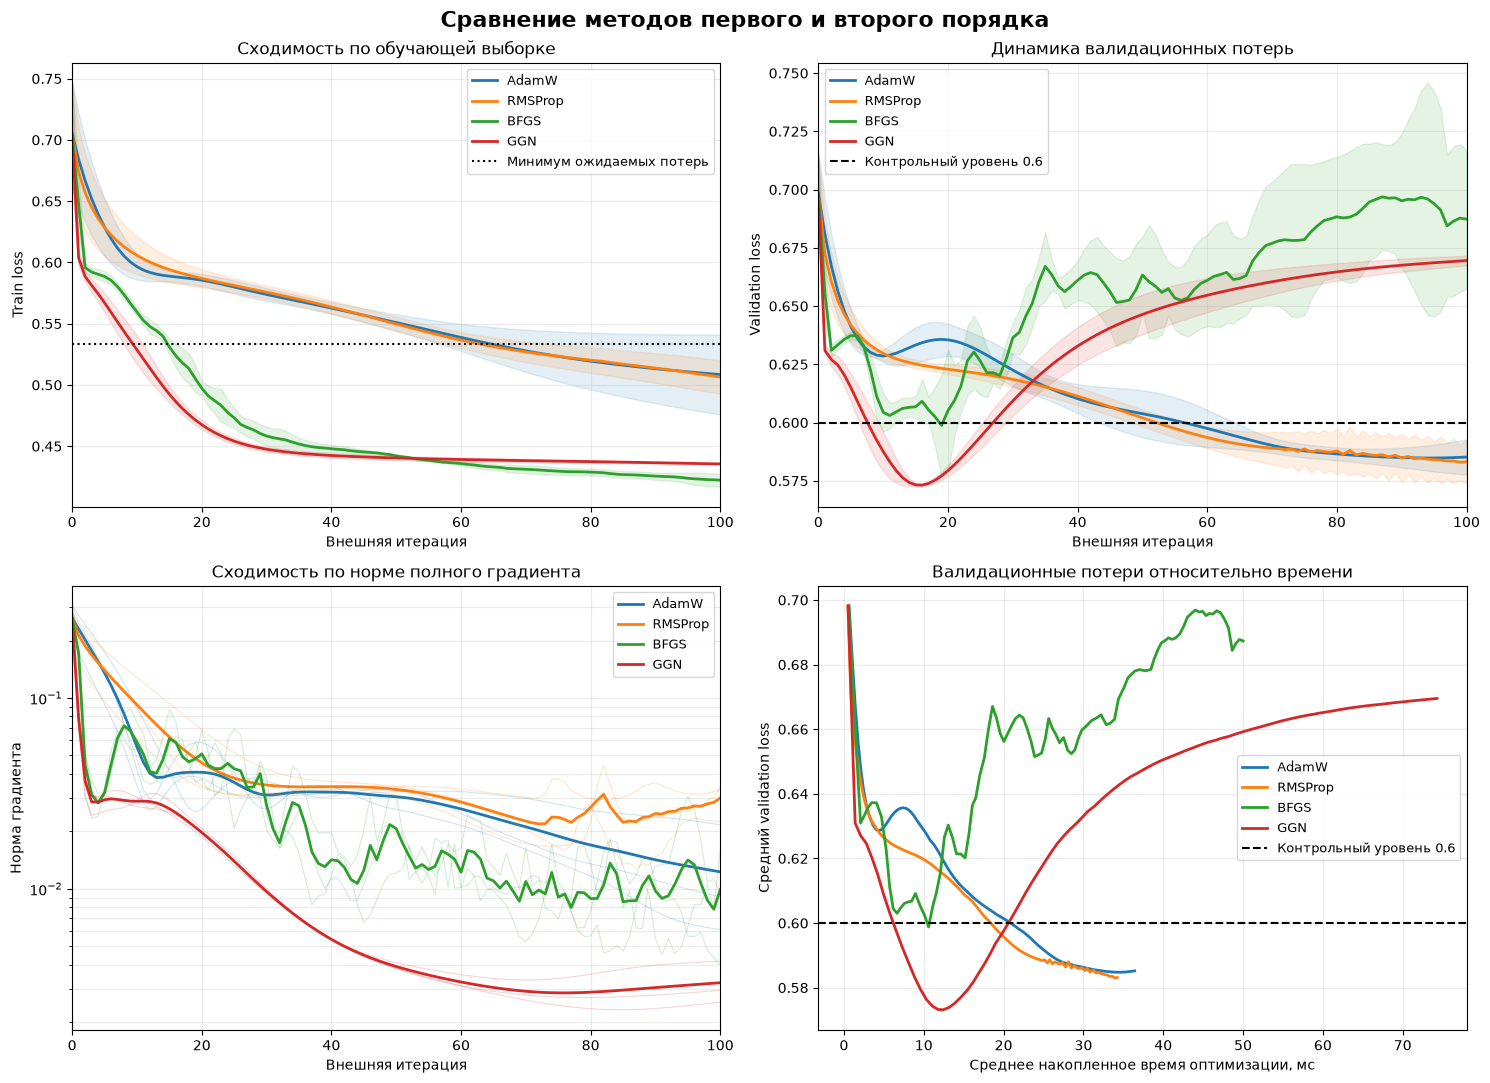

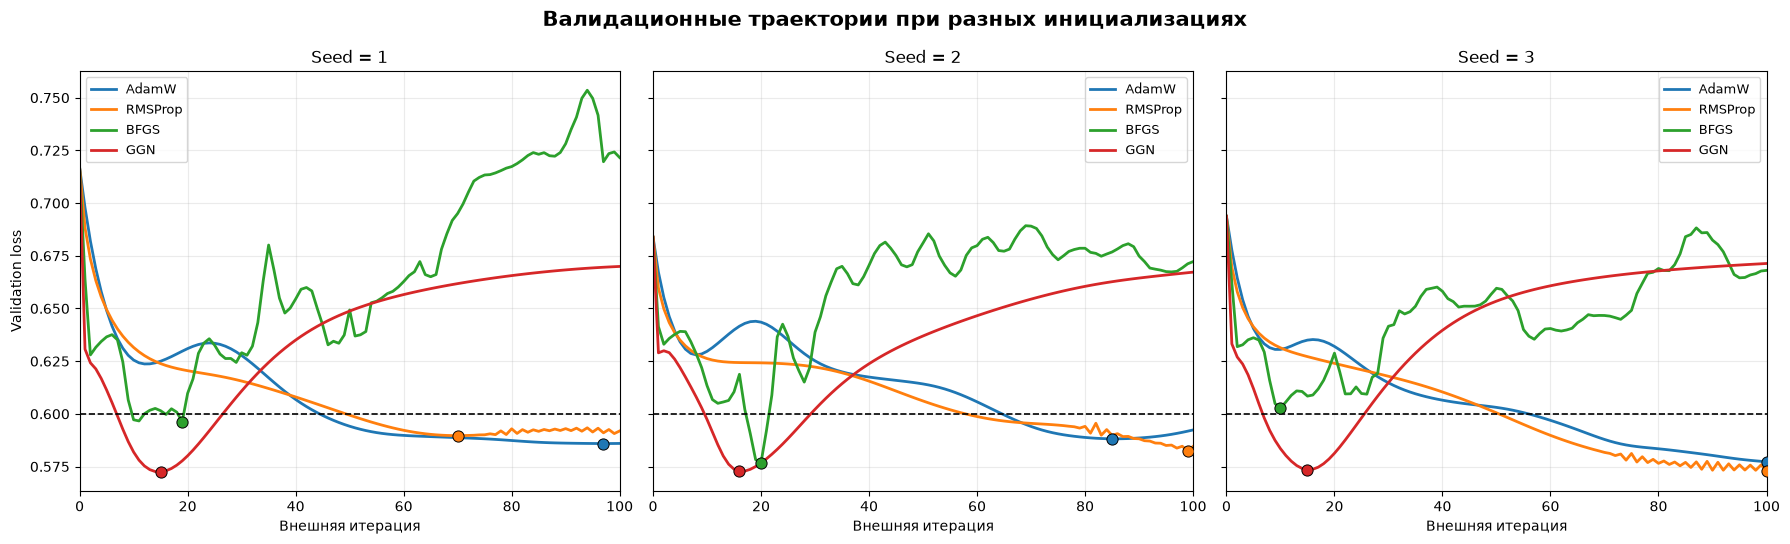

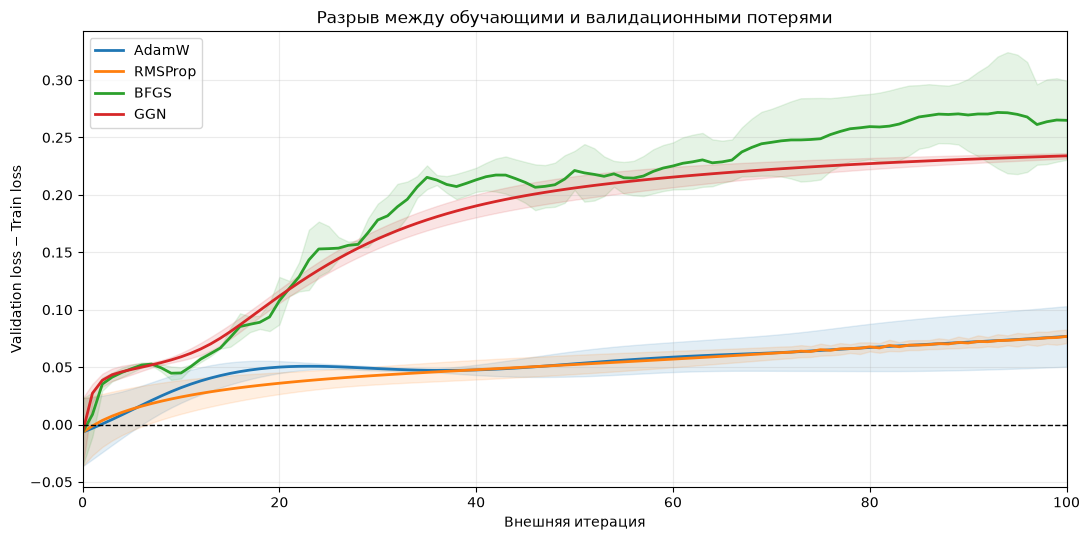

Сравнение качества оптимизации:
Среднее ± выборочное стандартное отклонение


,AdamW,RMSProp,BFGS,GGN
Начальный train loss,0.704882 ± 0.041734,0.704882 ± 0.041734,0.704882 ± 0.041734,0.704882 ± 0.041734
Начальный validation loss,0.698148 ± 0.016925,0.698148 ± 0.016925,0.698148 ± 0.016925,0.698148 ± 0.016925
Train loss после 100 шагов,0.508474 ± 0.032715,0.506443 ± 0.013459,0.422383 ± 0.005266,0.435543 ± 0.000314
Validation loss после 100 шагов,0.585203 ± 0.007581,0.583164 ± 0.009507,0.687313 ± 0.029784,0.669518 ± 0.002088
Минимальный validation loss,0.583786 ± 0.005757,0.581702 ± 0.008343,0.591971 ± 0.013429,0.572927 ± 0.000533
Лучшая итерация,94.00 ± 7.94,89.67 ± 17.04,16.33 ± 5.51,15.33 ± 0.58
Train loss на лучшей итерации,0.509962 ± 0.033936,0.510928 ± 0.020279,0.516725 ± 0.037050,0.490037 ± 0.003078
Конечная норма градиента,1.2269e-02 ± 8.2172e-03,2.9932e-02 ± 6.3762e-03,9.9000e-03 ± 6.0598e-03,3.2176e-03 ± 8.5099e-04
Минимальная норма градиента,1.2269e-02 ± 8.2172e-03,1.9600e-02 ± 8.6005e-03,4.9084e-03 ± 1.1452e-03,2.7810e-03 ± 5.0813e-04
Относительное уменьшение train loss,27.84% ± 2.94 п.п.,28.06% ± 2.32 п.п.,39.92% ± 4.03 п.п.,38.07% ± 3.57 п.п.



Стабильность оптимизации:


Метод,Запуски,Принятые шаги,Отклонённые шаги,Всего проб,Отклонённые пробы,Нечисловые пробы,Увеличения train loss,Увеличения validation loss
AdamW,3,300,0,300,0,0,2,47
RMSProp,3,300,0,300,0,0,0,40
BFGS,3,300,0,302,2,0,0,175
GGN,3,300,0,300,0,0,0,255



Лидеры по отдельным критериям:


Критерий,Метод,Среднее значение
Минимальный конечный train loss,BFGS,0.42238335
Минимальный конечный validation loss,RMSProp,0.58316428
Минимальный средний лучший validation loss,GGN,0.57292714
Минимальная конечная норма градиента,GGN,0.00321760
Минимальный средний разрыв потерь,RMSProp,0.07672116
Минимальное время 100 итераций,RMSProp,34.24060026



Количество сохранённых состояний: 1212
Количество повторений каждого метода: 3
Тестовые метрики ещё не вычислялись.


In [22]:
# Формирование общей таблицы внешних итераций
history_columns = [
    "method",
    "seed",
    "iteration",
    "train_loss",
    "validation_loss",
    "gradient_norm",
    "parameter_norm",
    "step_norm",
    "alpha",
    "accepted",
    "trial_count",
    "core_elapsed_time_ms",
    "elapsed_time_ms",
    "train_loss_calls",
    "gradient_calls",
    "total_loss_calls",
    "total_gradient_calls",
    "curvature_builds",
    "bfgs_updates",
    "factorizations"
]

history_df = pd.DataFrame([
    {
        column: record[column]
        for column in history_columns
    }
    for result in experiment_results.values()
    for record in result["iteration_history"]
])

history_df["method"] = pd.Categorical(
    history_df["method"],
    categories=methods,
    ordered=True
)

history_df = (
    history_df
    .sort_values(["method", "seed", "iteration"])
    .reset_index(drop=True)
)

# Разница между валидационными и обучающими потерями
history_df["generalization_gap"] = (
    history_df["validation_loss"]
    - history_df["train_loss"]
)

# Проверка полноты сохранённых траекторий
assert len(history_df) == 1212

assert not history_df.duplicated(
    subset=["method", "seed", "iteration"]
).any()

assert (
    history_df.groupby(
        ["method", "iteration"],
        observed=True
    ).size() == 3
).all()


# =============================================
# Средние траектории и стандартные отклонения
# =============================================

trajectory_metrics = [
    "train_loss",
    "validation_loss",
    "gradient_norm",
    "step_norm",
    "generalization_gap",
    "core_elapsed_time_ms"
]

trajectory_stats = (
    history_df
    .groupby(
        ["method", "iteration"],
        observed=True
    )[trajectory_metrics]
    .agg(["mean", "std"])
)

trajectory_stats.columns = [
    f"{metric}_{stat}"
    for metric, stat in trajectory_stats.columns
]

trajectory_stats = trajectory_stats.reset_index()

# Используется выборочное стандартное отклонение:
# ddof = 1 (стандартное поведение pandas)

assert len(trajectory_stats) == 404


# Цвета оптимизаторов
method_colors = {
    "AdamW": "#1f77b4",
    "RMSProp": "#ff7f0e",
    "BFGS": "#2ca02c",
    "GGN": "#d62728"
}


# =============================================
# Графики сходимости
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11)
)

for method in methods:

    subset = trajectory_stats[
        trajectory_stats["method"] == method
    ]

    color = method_colors[method]

    x = subset["iteration"].to_numpy()

    train_mean = subset["train_loss_mean"].to_numpy()
    train_std = subset["train_loss_std"].to_numpy()

    val_mean = subset["validation_loss_mean"].to_numpy()
    val_std = subset["validation_loss_std"].to_numpy()

    gradient_mean = subset[
        "gradient_norm_mean"
    ].to_numpy()

    time_mean = subset[
        "core_elapsed_time_ms_mean"
    ].to_numpy()

    # 1. Обучающие потери
    axes[0, 0].plot(
        x,
        train_mean,
        color=color,
        linewidth=2,
        label=method
    )

    axes[0, 0].fill_between(
        x,
        train_mean - train_std,
        train_mean + train_std,
        color=color,
        alpha=0.12
    )

    # 2. Валидационные потери
    axes[0, 1].plot(
        x,
        val_mean,
        color=color,
        linewidth=2,
        label=method
    )

    axes[0, 1].fill_between(
        x,
        val_mean - val_std,
        val_mean + val_std,
        color=color,
        alpha=0.12
    )

    # 3. Индивидуальные нормы градиента
    for network_seed in network_seeds:

        individual = history_df[
            (history_df["method"] == method)
            & (history_df["seed"] == network_seed)
        ]

        axes[1, 0].plot(
            individual["iteration"],
            individual["gradient_norm"],
            color=color,
            linewidth=0.8,
            alpha=0.20
        )

    # Средняя норма градиента
    axes[1, 0].plot(
        x,
        gradient_mean,
        color=color,
        linewidth=2,
        label=method
    )

    # 4. Валидационные потери относительно времени
    axes[1, 1].plot(
        time_mean,
        val_mean,
        color=color,
        linewidth=2,
        label=method
    )


# Теоретический ориентир обучающих потерь
axes[0, 0].axhline(
    expected_bayes_loss,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Минимум ожидаемых потерь"
)

axes[0, 0].set_title(
    "Сходимость по обучающей выборке"
)

axes[0, 0].set_xlabel("Внешняя итерация")
axes[0, 0].set_ylabel("Train loss")

# Фиксированный контрольный уровень
for ax in [axes[0, 1], axes[1, 1]]:

    ax.axhline(
        quality_threshold,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Контрольный уровень {quality_threshold}"
    )

axes[0, 1].set_title(
    "Динамика валидационных потерь"
)

axes[0, 1].set_xlabel("Внешняя итерация")
axes[0, 1].set_ylabel("Validation loss")

# Логарифмический масштаб нормы градиента
axes[1, 0].set_yscale("log")

axes[1, 0].set_title(
    "Сходимость по норме полного градиента"
)

axes[1, 0].set_xlabel("Внешняя итерация")
axes[1, 0].set_ylabel("Норма градиента")

axes[1, 1].set_title(
    "Валидационные потери относительно времени"
)

axes[1, 1].set_xlabel(
    "Среднее накопленное время оптимизации, мс"
)

axes[1, 1].set_ylabel(
    "Средний validation loss"
)

for ax in axes.flat:

    ax.grid(
        True,
        alpha=0.25,
        which="both"
    )

    ax.legend(fontsize=9)

for ax in [
    axes[0, 0],
    axes[0, 1],
    axes[1, 0]
]:

    ax.set_xlim(0, iterations)

fig.suptitle(
    "Сравнение методов первого и второго порядка",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Индивидуальные валидационные траектории
# =============================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5),
    sharey=True
)

for ax, network_seed in zip(
    axes,
    network_seeds
):

    for method in methods:

        subset = history_df[
            (history_df["method"] == method)
            & (history_df["seed"] == network_seed)
        ]

        color = method_colors[method]

        ax.plot(
            subset["iteration"],
            subset["validation_loss"],
            color=color,
            linewidth=2,
            label=method
        )

        # Лучшая итерация для данного запуска
        best_record = experiment_results[
            (method, network_seed)
        ]["best_record"]

        ax.scatter(
            best_record["iteration"],
            best_record["validation_loss"],
            color=color,
            edgecolor="black",
            linewidth=0.7,
            s=65,
            zorder=5
        )

    ax.axhline(
        quality_threshold,
        color="black",
        linestyle="--",
        linewidth=1.2
    )

    ax.set_title(f"Seed = {network_seed}")

    ax.set_xlabel("Внешняя итерация")

    ax.set_xlim(0, iterations)

    ax.grid(alpha=0.25)

    ax.legend(fontsize=9)

axes[0].set_ylabel("Validation loss")

fig.suptitle(
    "Валидационные траектории при разных инициализациях",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Разница между validation loss и train loss
# =============================================

fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

for method in methods:

    subset = trajectory_stats[
        trajectory_stats["method"] == method
    ]

    x = subset["iteration"].to_numpy()

    gap_mean = subset[
        "generalization_gap_mean"
    ].to_numpy()

    gap_std = subset[
        "generalization_gap_std"
    ].to_numpy()

    color = method_colors[method]

    ax.plot(
        x,
        gap_mean,
        linewidth=2,
        color=color,
        label=method
    )

    ax.fill_between(
        x,
        gap_mean - gap_std,
        gap_mean + gap_std,
        color=color,
        alpha=0.12
    )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Разрыв между обучающими и валидационными потерями"
)

ax.set_xlabel("Внешняя итерация")

ax.set_ylabel("Validation loss − Train loss")

ax.set_xlim(0, iterations)

ax.grid(alpha=0.25)

ax.legend()

plt.tight_layout()
plt.show()


# =============================================
# Итоговые статистики качества оптимизации
# =============================================

experiment_df["final_generalization_gap"] = (
    experiment_df["final_validation_loss"]
    - experiment_df["final_train_loss"]
)

quality_metrics = {
    "initial_train_loss": "Начальный train loss",

    "initial_validation_loss": "Начальный validation loss",

    "final_train_loss": "Train loss после 100 шагов",

    "final_validation_loss": "Validation loss после 100 шагов",

    "best_validation_loss": "Минимальный validation loss",

    "best_iteration": "Лучшая итерация",

    "train_loss_at_best": "Train loss на лучшей итерации",

    "final_gradient_norm": "Конечная норма градиента",

    "min_gradient_norm": "Минимальная норма градиента",

    "train_loss_reduction": "Относительное уменьшение train loss",

    "validation_loss_reduction": "Относительное уменьшение validation loss",

    "final_generalization_gap": "Конечный разрыв потерь"
}

quality_stats = (
    experiment_df
    .groupby("method", observed=True)[list(quality_metrics)]
    .agg(["mean", "std"])
)

# Форматирование таблицы: среднее ± стандартное отклонение
quality_summary = pd.DataFrame(
    index=list(quality_metrics.values()),
    columns=methods,
    dtype=object
)

for metric, label in quality_metrics.items():

    for method in methods:

        mean_value = quality_stats.loc[
            method, (metric, "mean")
        ]

        std_value = quality_stats.loc[
            method, (metric, "std")
        ]

        if metric == "best_iteration":

            formatted = (
                f"{mean_value:.2f} ± {std_value:.2f}"
            )

        elif metric.endswith("_reduction"):

            formatted = (
                f"{mean_value:.2%} ± "
                f"{std_value * 100:.2f} п.п."
            )

        elif "gradient_norm" in metric:

            formatted = (
                f"{mean_value:.4e} ± {std_value:.4e}"
            )

        else:

            formatted = (
                f"{mean_value:.6f} ± {std_value:.6f}"
            )

        quality_summary.loc[label, method] = formatted

print("Сравнение качества оптимизации:")
print("Среднее ± выборочное стандартное отклонение")

display(quality_summary)


# =============================================
# Анализ стабильности и принятых шагов
# =============================================

stability_summary = (
    experiment_df
    .groupby("method", observed=True)
    .agg(
        runs=("seed", "count"),
        accepted_steps=("accepted_steps", "sum"),
        rejected_steps=("rejected_steps", "sum"),
        total_trials=("total_trials", "sum"),
        rejected_trials=("rejected_trials", "sum"),
        nonfinite_trials=("nonfinite_trials", "sum"),
        train_loss_increases=("train_loss_increases", "sum"),
        validation_loss_increases=(
            "validation_loss_increases", "sum"
        )
    )
    .reset_index()
)

stability_summary = stability_summary.rename(
    columns={
        "method": "Метод",
        "runs": "Запуски",
        "accepted_steps": "Принятые шаги",
        "rejected_steps": "Отклонённые шаги",
        "total_trials": "Всего проб",
        "rejected_trials": "Отклонённые пробы",
        "nonfinite_trials": "Нечисловые пробы",
        "train_loss_increases": "Увеличения train loss",
        "validation_loss_increases": "Увеличения validation loss"
    }
)

print("\nСтабильность оптимизации:")

display(
    stability_summary.style.hide(axis="index")
)


# =============================================
# Определение лидеров по различным критериям
# =============================================

quality_means = (
    experiment_df
    .groupby("method", observed=True)[[
        "final_train_loss",
        "final_validation_loss",
        "best_validation_loss",
        "final_gradient_norm",
        "final_generalization_gap",
        "core_time_ms"
    ]]
    .mean()
)

ranking_metrics = {
    "final_train_loss": "Минимальный конечный train loss",

    "final_validation_loss": "Минимальный конечный validation loss",

    "best_validation_loss": "Минимальный средний лучший validation loss",

    "final_gradient_norm": "Минимальная конечная норма градиента",

    "final_generalization_gap": "Минимальный средний разрыв потерь",

    "core_time_ms": "Минимальное время 100 итераций"
}

ranking_records = []

for metric, label in ranking_metrics.items():

    best_method = quality_means[metric].idxmin()

    ranking_records.append({
        "Критерий": label,
        "Метод": best_method,
        "Среднее значение": (
            quality_means.loc[best_method, metric]
        )
    })

ranking_df = pd.DataFrame(ranking_records)

print("\nЛидеры по отдельным критериям:")

display(
    ranking_df.style
    .hide(axis="index")
    .format({
        "Среднее значение": "{:.8f}"
    })
)

print("\nКоличество сохранённых состояний:", len(history_df))
print("Количество повторений каждого метода:", n_repeats)
print("Тестовые метрики ещё не вычислялись.")

Вычислительные затраты за 100 внешних итераций:
Среднее ± выборочное стандартное отклонение


,AdamW,RMSProp,BFGS,GGN
Основные вычисления train loss,101.0000 ± 0.0000,101.0000 ± 0.0000,201.6667 ± 1.1547,201.0000 ± 0.0000
Основные вычисления градиента,101.0000 ± 0.0000,101.0000 ± 0.0000,101.0000 ± 0.0000,101.0000 ± 0.0000
Диагностические вычисления train loss,0.0000 ± 0.0000,0.0000 ± 0.0000,0.6667 ± 1.1547,0.0000 ± 0.0000
Диагностические градиенты,0.0000 ± 0.0000,0.0000 ± 0.0000,0.6667 ± 1.1547,0.0000 ± 0.0000
Вычисления validation loss,101.0000 ± 0.0000,101.0000 ± 0.0000,101.6667 ± 1.1547,101.0000 ± 0.0000
Все вычисления функции потерь,202.0000 ± 0.0000,202.0000 ± 0.0000,304.0000 ± 3.4641,302.0000 ± 0.0000
Все вычисления градиента,101.0000 ± 0.0000,101.0000 ± 0.0000,101.6667 ± 1.1547,101.0000 ± 0.0000
Пробы Армихо,0.0000 ± 0.0000,0.0000 ± 0.0000,100.6667 ± 1.1547,100.0000 ± 0.0000
Построения якобиана,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,100.0000 ± 0.0000
Попытки обновления BFGS,0.0000 ± 0.0000,0.0000 ± 0.0000,100.0000 ± 0.0000,0.0000 ± 0.0000



Достижение контрольного уровня validation loss ≤ 0.60:


Метод,Seed,Порог достигнут,Итерация,Validation loss,Основные вычисления loss,Основные градиенты,Все вычисления loss,Все градиенты,Пробы Армихо,Якобианы,Обновления BFGS,Сборки GGN,Факторизации,Решения систем,"Время оптимизации, мс","Полное время, мс"
AdamW,1,True,45.000000,0.59925470,46.000000,46.000000,92.000000,46.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,16.1985,23.2528
AdamW,2,True,65.000000,0.59952481,66.000000,66.000000,132.000000,66.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,24.4160,31.2692
AdamW,3,True,56.000000,0.59994474,57.000000,57.000000,114.000000,57.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.2981,28.1079
RMSProp,1,True,50.000000,0.59939244,51.000000,51.000000,102.000000,51.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.6790,24.0308
RMSProp,2,True,58.000000,0.59990584,59.000000,59.000000,118.000000,59.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.1573,24.9917
RMSProp,3,True,51.000000,0.59939817,52.000000,52.000000,104.000000,52.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.6420,26.0420
BFGS,1,True,10.000000,0.59720174,21.000000,11.000000,32.000000,11.000000,10.000000,0.000000,10.000000,0.000000,0.000000,0.000000,7.1207,6.3371
BFGS,2,True,18.000000,0.59070342,37.000000,19.000000,56.000000,19.000000,18.000000,0.000000,18.000000,0.000000,0.000000,0.000000,8.7574,11.3530
BFGS,3,False,—,—,—,—,—,—,—,—,—,—,—,—,—,—
GGN,1,True,7.000000,0.59906375,15.000000,8.000000,23.000000,8.000000,7.000000,7.000000,0.000000,7.000000,7.000000,7.000000,5.3022,6.6842



Сводные характеристики достижения порога:
Среднее ± стандартное отклонение по успешным запускам


,AdamW,RMSProp,BFGS,GGN
Успешные запуски,3/3,3/3,2/3,3/3
Доля успешных запусков,100.00%,100.00%,66.67%,100.00%
Количество итераций,55.3333 ± 10.0167,53.0000 ± 4.3589,14.0000 ± 5.6569,8.0000 ± 1.7321
Основные вычисления loss,56.3333 ± 10.0167,54.0000 ± 4.3589,29.0000 ± 11.3137,17.0000 ± 3.4641
Основные градиенты,56.3333 ± 10.0167,54.0000 ± 4.3589,15.0000 ± 5.6569,9.0000 ± 1.7321
Все вычисления loss,112.6667 ± 20.0333,108.0000 ± 8.7178,44.0000 ± 16.9706,26.0000 ± 5.1962
Все градиенты,56.3333 ± 10.0167,54.0000 ± 4.3589,15.0000 ± 5.6569,9.0000 ± 1.7321
Пробы Армихо,0.0000 ± 0.0000,0.0000 ± 0.0000,14.0000 ± 5.6569,8.0000 ± 1.7321
Якобианы,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,8.0000 ± 1.7321
Обновления BFGS,0.0000 ± 0.0000,0.0000 ± 0.0000,14.0000 ± 5.6569,0.0000 ± 0.0000



Примечание: запуски, не достигшие порога, не заменяются значением 100 и не включаются в среднее время достижения порога.
Доля успешных запусков указывается отдельно.


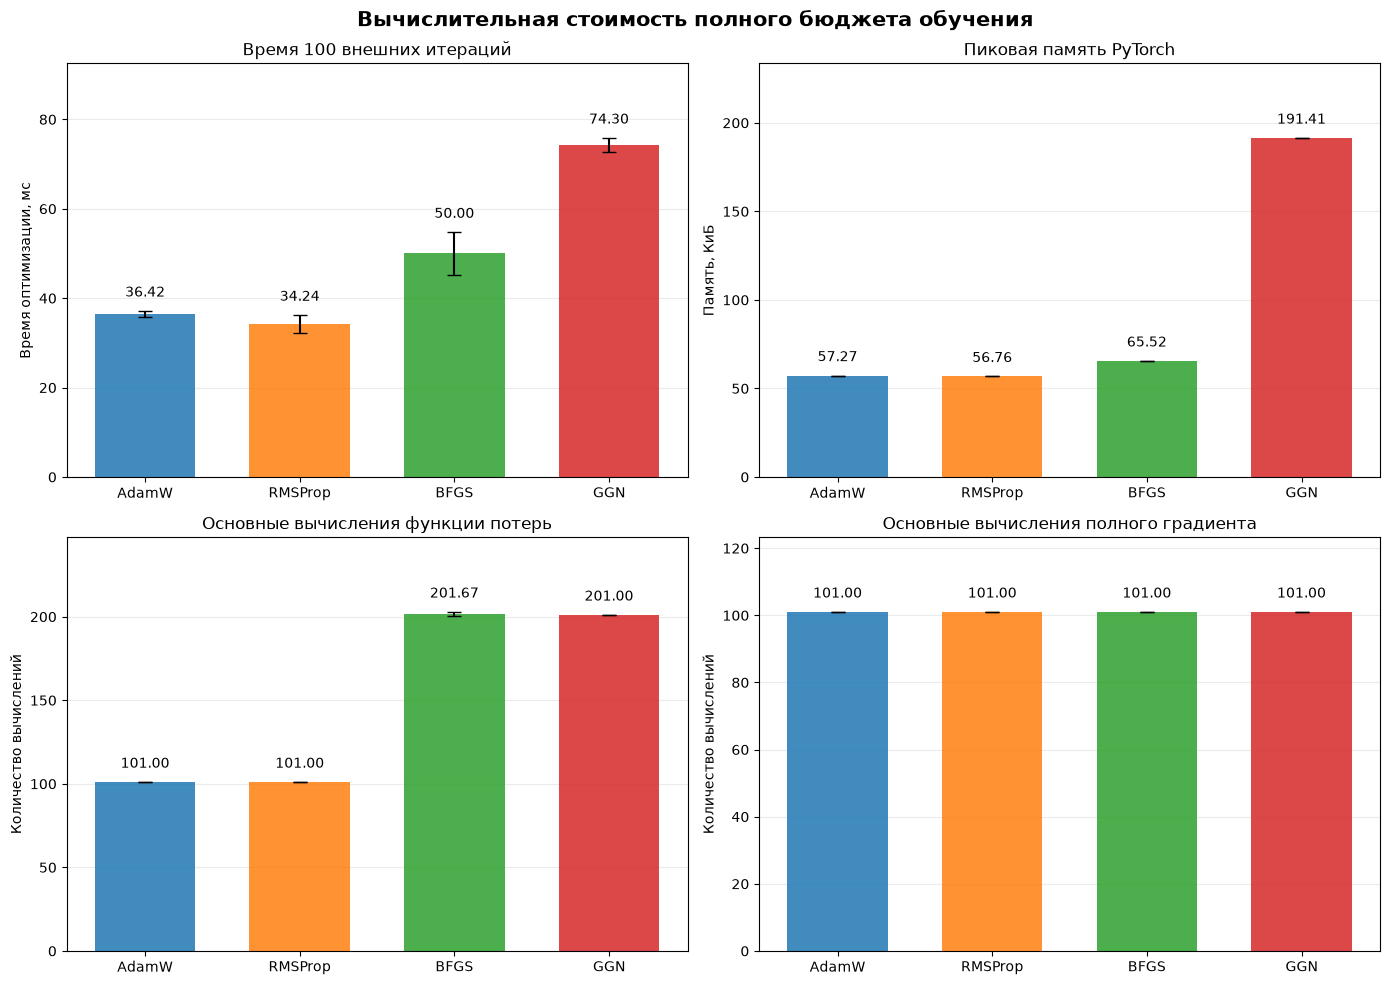

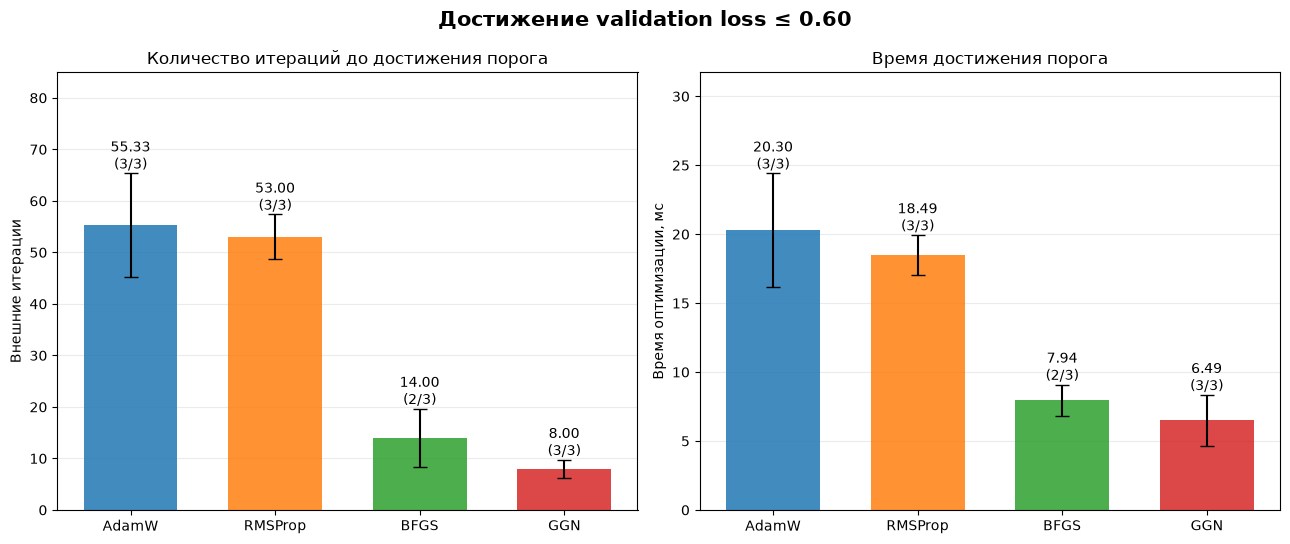

Лидеры среди методов, достигших порога во всех повторах:

По количеству итераций: GGN
Среднее количество итераций: 8.0000

По времени достижения порога: GGN
Среднее время: 6.4934 мс

По количеству основных градиентов: GGN
Среднее количество градиентов: 9.0000

Совпадает ли лидер по итерациям и времени: Да

Самый быстрый метод по времени 100 итераций: RMSProp
Среднее время: 34.2406 мс

Анализ вычислительных затрат завершён.
Тестовая выборка ещё не использовалась.


In [23]:
# =============================================
# Сравнение вычислительных затрат
# =============================================

cost_metrics = {
    "train_loss_calls": "Основные вычисления train loss",
    "gradient_calls": "Основные вычисления градиента",

    "diagnostic_train_loss_calls": "Диагностические вычисления train loss",
    "diagnostic_gradient_calls": "Диагностические градиенты",
    "validation_loss_calls": "Вычисления validation loss",

    "total_loss_calls": "Все вычисления функции потерь",
    "total_gradient_calls": "Все вычисления градиента",

    "line_search_calls": "Пробы Армихо",
    "jacobian_calls": "Построения якобиана",

    "bfgs_update_attempts": "Попытки обновления BFGS",
    "bfgs_updates": "Обновления BFGS",

    "curvature_builds": "Сборки матрицы GGN",
    "factorizations": "Матричные факторизации",
    "linear_system_solves": "Решения линейных систем",
    "triangular_solves": "Решения треугольных систем",
    "hessian_calls": "Вычисления точного Гессе",

    "core_time_ms": "Время оптимизации, мс",
    "total_time_ms": "Полное время, мс",

    "torch_peak_kib": "Пик памяти PyTorch, КиБ",
    "python_peak_kib": "Пик памяти Python, КиБ",

    "state_bytes": "Постоянное числовое состояние, байт"
}

cost_stats = (
    experiment_df
    .groupby("method", observed=True)[list(cost_metrics)]
    .agg(["mean", "std"])
)

cost_summary = pd.DataFrame(
    index=list(cost_metrics.values()),
    columns=methods,
    dtype=object
)

for metric, label in cost_metrics.items():

    for method in methods:

        mean_value = cost_stats.loc[
            method, (metric, "mean")
        ]

        std_value = cost_stats.loc[
            method, (metric, "std")
        ]

        cost_summary.loc[label, method] = (
            f"{mean_value:.4f} ± {std_value:.4f}"
        )

print("Вычислительные затраты за 100 внешних итераций:")
print("Среднее ± выборочное стандартное отклонение")

display(cost_summary)


# =============================================
# Достижение фиксированного уровня качества
# =============================================

threshold_columns = {
    "method": "Метод",
    "seed": "Seed",
    "threshold_reached": "Порог достигнут",
    "threshold_iteration": "Итерация",
    "threshold_validation_loss": "Validation loss",

    "threshold_train_loss_calls": "Основные вычисления loss",
    "threshold_gradient_calls": "Основные градиенты",

    "threshold_total_loss_calls": "Все вычисления loss",
    "threshold_total_gradient_calls": "Все градиенты",

    "threshold_line_search_calls": "Пробы Армихо",
    "threshold_jacobian_calls": "Якобианы",
    "threshold_bfgs_updates": "Обновления BFGS",
    "threshold_curvature_builds": "Сборки GGN",
    "threshold_factorizations": "Факторизации",
    "threshold_linear_system_solves": "Решения систем",

    "threshold_core_time_ms": "Время оптимизации, мс",
    "threshold_total_time_ms": "Полное время, мс"
}

threshold_df = experiment_df[
    list(threshold_columns)
].copy()

print(
    f"\nДостижение контрольного уровня "
    f"validation loss ≤ {quality_threshold:.2f}:"
)

display(
    threshold_df
    .rename(columns=threshold_columns)
    .style
    .hide(axis="index")
    .format({
        "Validation loss": "{:.8f}",
        "Время оптимизации, мс": "{:.4f}",
        "Полное время, мс": "{:.4f}"
    }, na_rep="—")
)


# =============================================
# Сводная статистика достижения порога
# =============================================

threshold_metrics = {
    "threshold_iteration": "Количество итераций",
    "threshold_train_loss_calls": "Основные вычисления loss",
    "threshold_gradient_calls": "Основные градиенты",
    "threshold_total_loss_calls": "Все вычисления loss",
    "threshold_total_gradient_calls": "Все градиенты",
    "threshold_line_search_calls": "Пробы Армихо",
    "threshold_jacobian_calls": "Якобианы",
    "threshold_bfgs_updates": "Обновления BFGS",
    "threshold_curvature_builds": "Сборки GGN",
    "threshold_factorizations": "Факторизации",
    "threshold_linear_system_solves": "Решения систем",
    "threshold_core_time_ms": "Время оптимизации, мс",
    "threshold_total_time_ms": "Полное время, мс"
}

threshold_summary = pd.DataFrame(
    index=[
        "Успешные запуски",
        "Доля успешных запусков",
        *threshold_metrics.values()
    ],
    columns=methods,
    dtype=object
)

threshold_success_records = []

for method in methods:

    subset = experiment_df[
        experiment_df["method"] == method
    ]

    successful = subset[
        subset["threshold_reached"]
    ]

    n_success = len(successful)

    threshold_summary.loc[
        "Успешные запуски", method
    ] = f"{n_success}/{n_repeats}"

    threshold_summary.loc[
        "Доля успешных запусков", method
    ] = f"{n_success / n_repeats:.2%}"

    record = {
        "method": method,
        "successful_runs": n_success,
        "success_rate": n_success / n_repeats
    }

    for metric, label in threshold_metrics.items():

        mean_value = successful[metric].mean()
        std_value = successful[metric].std(ddof=1)

        if n_success == 0:

            formatted = "Не достигнут"

        elif n_success == 1:

            formatted = (
                f"{mean_value:.4f} "
                f"(один успешный запуск)"
            )

        else:

            formatted = (
                f"{mean_value:.4f} ± {std_value:.4f}"
            )

        threshold_summary.loc[label, method] = formatted

        record[f"{metric}_mean"] = mean_value
        record[f"{metric}_std"] = std_value

    threshold_success_records.append(record)

threshold_success_df = pd.DataFrame(
    threshold_success_records
)

print("\nСводные характеристики достижения порога:")
print("Среднее ± стандартное отклонение по успешным запускам")

display(threshold_summary)

print(
    "\nПримечание: запуски, не достигшие порога, "
    "не заменяются значением 100 и не включаются "
    "в среднее время достижения порога."
)

print(
    "Доля успешных запусков указывается отдельно."
)


# =============================================
# Визуализация вычислительных затрат
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

colors = [
    method_colors[method]
    for method in methods
]

plot_metrics = [
    (
        "core_time_ms",
        "Время 100 внешних итераций",
        "Время оптимизации, мс"
    ),
    (
        "torch_peak_kib",
        "Пиковая память PyTorch",
        "Память, КиБ"
    ),
    (
        "train_loss_calls",
        "Основные вычисления функции потерь",
        "Количество вычислений"
    ),
    (
        "gradient_calls",
        "Основные вычисления полного градиента",
        "Количество вычислений"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes.flat,
    plot_metrics
):

    means = [
        cost_stats.loc[method, (metric, "mean")]
        for method in methods
    ]

    stds = [
        cost_stats.loc[method, (metric, "std")]
        for method in methods
    ]

    bars = ax.bar(
        methods,
        means,
        yerr=stds,
        capsize=5,
        color=colors,
        alpha=0.85,
        width=0.65
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.2f}" for value in means],
        padding=8
    )

    ax.set_ylim(
        0,
        max(
            m + s for m, s in zip(means, stds)
        ) * 1.22
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.set_axisbelow(True)

fig.suptitle(
    "Вычислительная стоимость полного бюджета обучения",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Графики достижения контрольного уровня
# =============================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5)
)

threshold_plot_metrics = [
    (
        "threshold_iteration",
        "Количество итераций до достижения порога",
        "Внешние итерации"
    ),
    (
        "threshold_core_time_ms",
        "Время достижения порога",
        "Время оптимизации, мс"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes,
    threshold_plot_metrics
):

    max_height = 0

    for position, method in enumerate(methods):

        row = threshold_success_df[
            threshold_success_df["method"] == method
        ].iloc[0]

        n_success = int(row["successful_runs"])

        mean_value = row[f"{metric}_mean"]
        std_value = row[f"{metric}_std"]

        if n_success > 0:

            error = (
                std_value
                if np.isfinite(std_value)
                else 0
            )

            ax.bar(
                position,
                mean_value,
                yerr=error,
                capsize=5,
                color=method_colors[method],
                alpha=0.85,
                width=0.65
            )

            height = mean_value + error

            max_height = max(max_height, height)

            ax.text(
                position,
                height,
                f"{mean_value:.2f}\n"
                f"({n_success}/{n_repeats})",
                ha="center",
                va="bottom",
                fontsize=10
            )

        else:

            ax.text(
                position,
                0,
                f"0/{n_repeats}",
                ha="center",
                va="bottom"
            )

    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods)

    ax.set_ylim(
        0,
        max(max_height * 1.30, 1)
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.set_axisbelow(True)

fig.suptitle(
    f"Достижение validation loss ≤ {quality_threshold:.2f}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Определение лидеров
# =============================================

# Для прямого сравнения скорости достижения порога
# рассматриваем методы, достигшие его во всех повторах.

fully_successful = threshold_success_df[
    threshold_success_df["successful_runs"] == n_repeats
]

if not fully_successful.empty:

    best_by_iterations = fully_successful.loc[
        fully_successful[
            "threshold_iteration_mean"
        ].idxmin()
    ]

    best_by_time = fully_successful.loc[
        fully_successful[
            "threshold_core_time_ms_mean"
        ].idxmin()
    ]

    best_by_gradients = fully_successful.loc[
        fully_successful[
            "threshold_gradient_calls_mean"
        ].idxmin()
    ]

    print("Лидеры среди методов, достигших порога во всех повторах:")

    print(
        "\nПо количеству итераций:",
        best_by_iterations["method"]
    )

    print(
        f"Среднее количество итераций: "
        f"{best_by_iterations['threshold_iteration_mean']:.4f}"
    )

    print(
        "\nПо времени достижения порога:",
        best_by_time["method"]
    )

    print(
        f"Среднее время: "
        f"{best_by_time['threshold_core_time_ms_mean']:.4f} мс"
    )

    print(
        "\nПо количеству основных градиентов:",
        best_by_gradients["method"]
    )

    print(
        f"Среднее количество градиентов: "
        f"{best_by_gradients['threshold_gradient_calls_mean']:.4f}"
    )

    print(
        "\nСовпадает ли лидер по итерациям и времени:",
        "Да"
        if best_by_iterations["method"] == best_by_time["method"]
        else "Нет"
    )

else:

    print(
        "Ни один метод не достиг порога "
        "во всех трёх повторениях."
    )


# Лидер по времени полного бюджета
full_budget_time = (
    experiment_df
    .groupby("method", observed=True)["core_time_ms"]
    .mean()
)

print(
    "\nСамый быстрый метод по времени 100 итераций:",
    full_budget_time.idxmin()
)

print(
    f"Среднее время: "
    f"{full_budget_time.min():.4f} мс"
)

print("\nАнализ вычислительных затрат завершён.")
print("Тестовая выборка ещё не использовалась.")

Качество моделей после 100 итераций:


Метод,Seed,Train loss,Train accuracy,Train F1-macro,Train ROC-AUC,Validation loss,Validation accuracy,Validation F1-macro,Validation ROC-AUC
AdamW,1,0.529477,0.741497,0.741065,0.807150,0.585972,0.666667,0.666330,0.750507
AdamW,2,0.525165,0.741497,0.741197,0.808034,0.592370,0.682540,0.682460,0.747465
AdamW,3,0.470781,0.795918,0.795833,0.859129,0.577266,0.714286,0.712475,0.784990
RMSProp,1,0.521455,0.755102,0.755057,0.814496,0.591896,0.666667,0.666330,0.724138
RMSProp,2,0.502422,0.761905,0.761861,0.833372,0.584560,0.682540,0.682460,0.768763
RMSProp,3,0.495453,0.761905,0.761806,0.843554,0.573037,0.682540,0.682460,0.775862
BFGS,1,0.416891,0.812925,0.812298,0.890000,0.721620,0.634921,0.625485,0.728195
BFGS,2,0.427388,0.806122,0.805616,0.887535,0.672241,0.714286,0.705301,0.752535
BFGS,3,0.422872,0.806122,0.805309,0.885862,0.668077,0.730159,0.727689,0.763692
GGN,1,0.435676,0.785714,0.784995,0.881631,0.669954,0.714286,0.705301,0.749493



Итоговые результаты на тестовой выборке:


Метод,Seed,Лучшая итерация,Validation loss,Test loss,Test accuracy,Test F1-macro,Test ROC-AUC
AdamW,1,97,0.58592179,0.59419356,76.19%,0.761665,0.745436
AdamW,2,85,0.58816972,0.60275247,76.19%,0.761665,0.738337
AdamW,3,100,0.57726626,0.52563548,76.19%,0.761665,0.848884
RMSProp,1,70,0.58968121,0.59535807,74.60%,0.745968,0.740365
RMSProp,2,99,0.58238748,0.57345420,77.78%,0.777722,0.771805
RMSProp,3,100,0.57303689,0.55489033,77.78%,0.777722,0.806288
BFGS,1,19,0.59633184,0.52726184,82.54%,0.825221,0.852941
BFGS,2,20,0.57690398,0.53420117,82.54%,0.823799,0.839757
BFGS,3,10,0.60267860,0.58076998,71.43%,0.712475,0.790061
GGN,1,15,0.57248300,0.51874812,79.37%,0.793651,0.858012



Сводное качество классификации:
Среднее ± выборочное стандартное отклонение


,AdamW,RMSProp,BFGS,GGN
Train accuracy после 100 шагов,75.96% ± 3.14 п.п.,75.96% ± 0.39 п.п.,80.84% ± 0.39 п.п.,78.91% ± 0.59 п.п.
Train F1-macro после 100 шагов,0.759365 ± 0.031582,0.759574 ± 0.003912,0.807741 ± 0.003949,0.788523 ± 0.006110
Validation accuracy после 100 шагов,68.78% ± 2.42 п.п.,67.72% ± 0.92 п.п.,69.31% ± 5.10 п.п.,71.43% ± 0.00 п.п.
Validation F1-macro после 100 шагов,0.687088 ± 0.023418,0.677083 ± 0.009312,0.686158 ± 0.053724,0.705301 ± 0.000000
Train loss на лучшей итерации,0.509962 ± 0.033936,0.510928 ± 0.020279,0.516725 ± 0.037050,0.490037 ± 0.003078
Train accuracy на лучшей итерации,75.96% ± 3.14 п.п.,75.62% ± 0.52 п.п.,76.19% ± 2.70 п.п.,76.30% ± 0.52 п.п.
Train F1-macro на лучшей итерации,0.759321 ± 0.031620,0.756141 ± 0.005163,0.761423 ± 0.027576,0.762968 ± 0.005178
Validation loss на лучшей итерации,0.583786 ± 0.005757,0.581702 ± 0.008343,0.591971 ± 0.013429,0.572927 ± 0.000533
Validation accuracy на лучшей итерации,67.72% ± 3.30 п.п.,67.72% ± 0.92 п.п.,67.20% ± 0.92 п.п.,67.72% ± 0.92 п.п.
Validation F1-macro на лучшей итерации,0.676268 ± 0.032401,0.677083 ± 0.009312,0.671707 ± 0.009312,0.677083 ± 0.009312



Базовые и теоретические ориентиры на Test:


Модель,Test loss,Accuracy,F1-macro,ROC-AUC
Постоянная вероятность 0.5,0.69314718,46.03%,0.315217,0.500000
Частота класса 1 в Train,0.69005907,53.97%,0.350515,0.500000
Истинная функция вероятностей,0.49093400,77.78%,0.777722,0.868154



Теоретические ожидаемые характеристики Test:
Ожидаемая байесовская accuracy: 73.3534%
Минимальная ожидаемая cross-entropy: 0.53479275


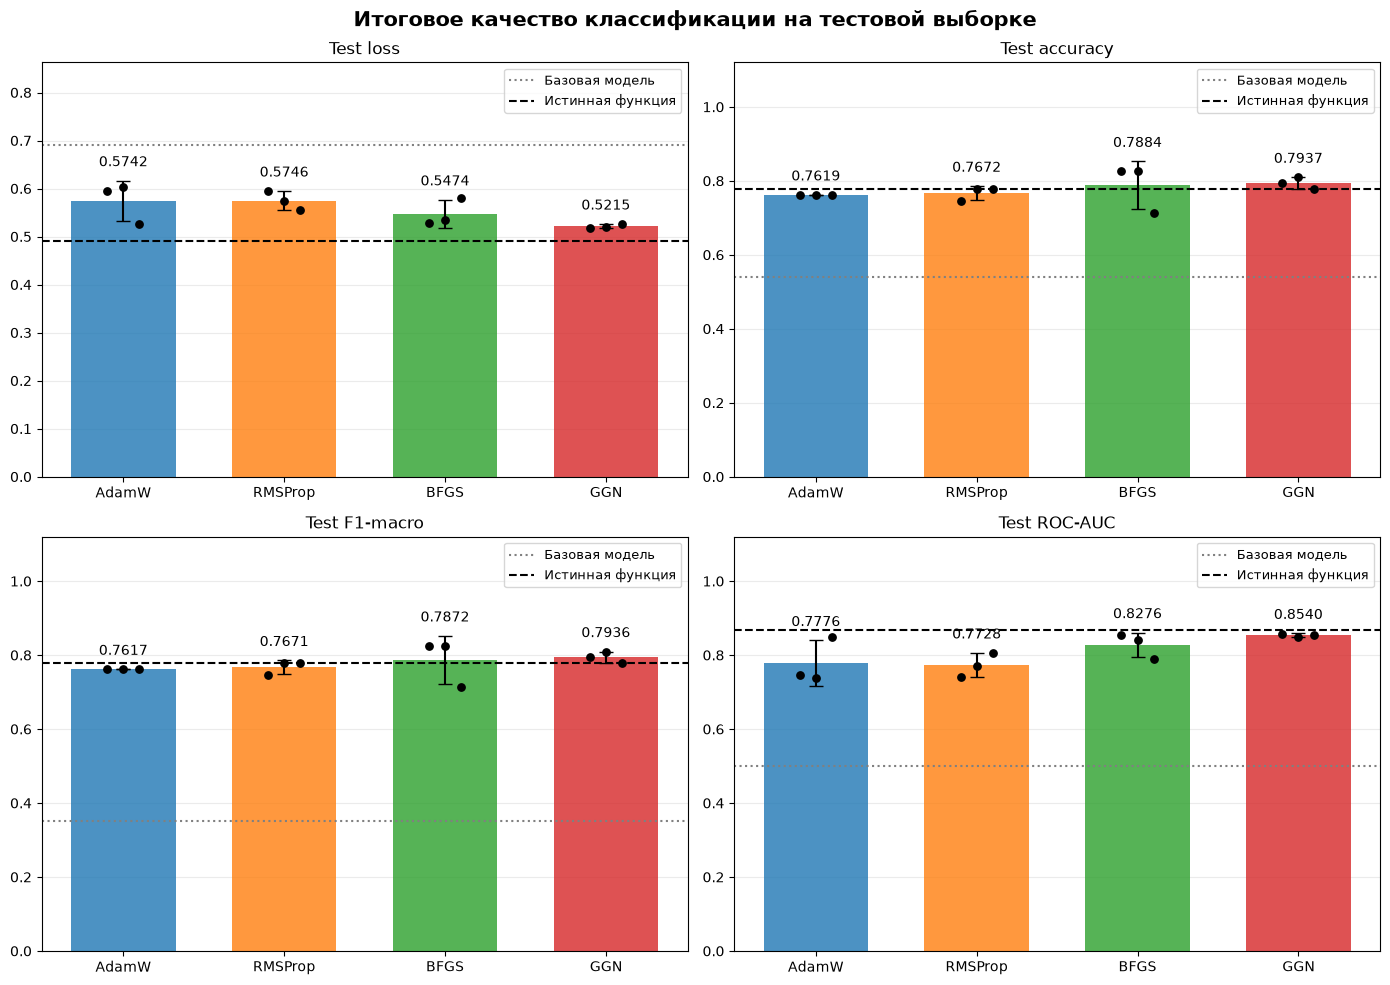

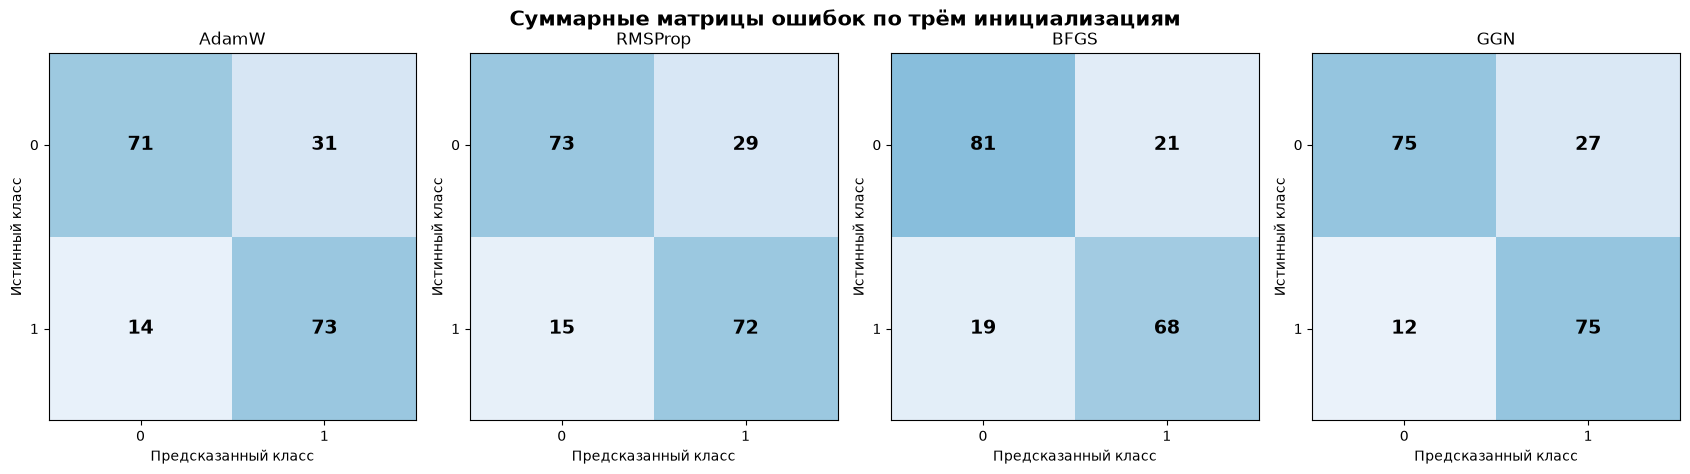


Матрицы ошибок объединяют прогнозы трёх моделей на одной тестовой выборке.
189 классификаций для каждого метода не являются 189 независимыми наблюдениями.

Сравнение наблюдаемых тестовых результатов:


Критерий,Метод,Значение
Минимальный Test loss,GGN,0.52152436
Максимальная Test accuracy,GGN,0.79365079
Максимальный Test F1-macro,GGN,0.79361612
Максимальный Test ROC-AUC,GGN,0.85395538



Количество оценённых моделей: 12
Количество независимых тестовых наблюдений: 63
Параметры моделей после тестирования не изменялись.
Итоговая оценка классификации завершена.


In [24]:
# =============================================
# Функция оценки качества классификации
# =============================================

def classification_metrics(theta, X_data, y_data):

    with torch.no_grad():

        logits = forward_logits(
            theta,
            X_data
        )

        probabilities = torch.sigmoid(logits)

        loss = loss_function(
            logits,
            y_data
        ).item()

    y_true = (
        y_data.detach().cpu().numpy()
        .reshape(-1).astype(int)
    )

    y_probability = (
        probabilities.detach().cpu().numpy()
        .reshape(-1)
    )

    y_predicted = (
        y_probability >= 0.5
    ).astype(int)

    return {
        "loss": loss,

        "accuracy": accuracy_score(
            y_true,
            y_predicted
        ),

        "f1_macro": f1_score(
            y_true,
            y_predicted,
            labels=[0, 1],
            average="macro",
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            y_probability
        ),

        "confusion_matrix": confusion_matrix(
            y_true,
            y_predicted,
            labels=[0, 1]
        ),

        "probabilities": y_probability,

        "predictions": y_predicted
    }


# =============================================
# Оценка всех 12 обученных моделей
# =============================================

evaluation_results = {}

evaluation_records = []

for method in methods:

    for network_seed in network_seeds:

        result = experiment_results[
            (method, network_seed)
        ]

        best_theta = result["best_theta"]

        final_theta = result["final_theta"]

        best_iteration = (
            result["best_record"]["iteration"]
        )

        # Проверка выбора модели исключительно по validation
        expected_best = min(
            result["iteration_history"],
            key=lambda record: record["validation_loss"]
        )

        assert best_iteration == (
            expected_best["iteration"]
        )

        assert torch.equal(
            best_theta,
            expected_best["theta"]
        )

        # Оценка состояния после 100 итераций
        final_train = classification_metrics(
            final_theta,
            X_train,
            y_train
        )

        final_val = classification_metrics(
            final_theta,
            X_val,
            y_val
        )

        # Оценка выбранного по валидации состояния
        best_train = classification_metrics(
            best_theta,
            X_train,
            y_train
        )

        best_val = classification_metrics(
            best_theta,
            X_val,
            y_val
        )

        # Независимая итоговая тестовая оценка
        best_test = classification_metrics(
            best_theta,
            X_test,
            y_test
        )

        # Проверка совпадения сохранённых потерь
        assert np.isclose(
            best_val["loss"],
            result["best_record"]["validation_loss"],
            atol=1e-12,
            rtol=1e-10
        )

        assert np.isclose(
            final_val["loss"],
            result["iteration_history"][-1][
                "validation_loss"
            ],
            atol=1e-12,
            rtol=1e-10
        )

        assert (
            best_test["confusion_matrix"].sum()
            == len(test_idx)
        )

        # Сохранение прогнозов и матриц ошибок
        evaluation_results[
            (method, network_seed)
        ] = {
            "best_iteration": best_iteration,

            "final_train": final_train,
            "final_val": final_val,

            "best_train": best_train,
            "best_val": best_val,
            "best_test": best_test
        }

        record = {
            "method": method,
            "seed": network_seed,
            "best_iteration": best_iteration
        }

        for prefix, metrics_result in [
            ("final_train", final_train),
            ("final_val", final_val),
            ("best_train", best_train),
            ("best_val", best_val),
            ("test", best_test)
        ]:

            for metric in [
                "loss",
                "accuracy",
                "f1_macro",
                "roc_auc"
            ]:

                record[f"{prefix}_{metric}"] = (
                    metrics_result[metric]
                )

        evaluation_records.append(record)


evaluation_df = pd.DataFrame(
    evaluation_records
)

evaluation_df["method"] = pd.Categorical(
    evaluation_df["method"],
    categories=methods,
    ordered=True
)

assert len(evaluation_df) == 12

assert not evaluation_df.duplicated(
    subset=["method", "seed"]
).any()


# =============================================
# Качество после 100 внешних итераций
# =============================================

final_quality_columns = {
    "method": "Метод",
    "seed": "Seed",

    "final_train_loss": "Train loss",
    "final_train_accuracy": "Train accuracy",
    "final_train_f1_macro": "Train F1-macro",
    "final_train_roc_auc": "Train ROC-AUC",

    "final_val_loss": "Validation loss",
    "final_val_accuracy": "Validation accuracy",
    "final_val_f1_macro": "Validation F1-macro",
    "final_val_roc_auc": "Validation ROC-AUC"
}

print("Качество моделей после 100 итераций:")

display(
    evaluation_df[list(final_quality_columns)]
    .rename(columns=final_quality_columns)
    .style.hide(axis="index")
    .format({
        label: "{:.6f}"
        for column, label in final_quality_columns.items()
        if column not in ["method", "seed"]
    })
)


# =============================================
# Независимое тестовое качество
# =============================================

test_columns = {
    "method": "Метод",
    "seed": "Seed",
    "best_iteration": "Лучшая итерация",

    "best_val_loss": "Validation loss",

    "test_loss": "Test loss",
    "test_accuracy": "Test accuracy",
    "test_f1_macro": "Test F1-macro",
    "test_roc_auc": "Test ROC-AUC"
}

print("\nИтоговые результаты на тестовой выборке:")

display(
    evaluation_df[list(test_columns)]
    .rename(columns=test_columns)
    .style.hide(axis="index")
    .format({
        "Validation loss": "{:.8f}",
        "Test loss": "{:.8f}",
        "Test accuracy": "{:.2%}",
        "Test F1-macro": "{:.6f}",
        "Test ROC-AUC": "{:.6f}"
    })
)


# =============================================
# Сводная статистика классификации
# =============================================

classification_summary_metrics = {
    "final_train_accuracy": "Train accuracy после 100 шагов",

    "final_train_f1_macro": "Train F1-macro после 100 шагов",

    "final_val_accuracy": "Validation accuracy после 100 шагов",

    "final_val_f1_macro": "Validation F1-macro после 100 шагов",

    "best_train_loss": "Train loss на лучшей итерации",

    "best_train_accuracy": "Train accuracy на лучшей итерации",

    "best_train_f1_macro": "Train F1-macro на лучшей итерации",

    "best_val_loss": "Validation loss на лучшей итерации",

    "best_val_accuracy": "Validation accuracy на лучшей итерации",

    "best_val_f1_macro": "Validation F1-macro на лучшей итерации",

    "test_loss": "Test loss",

    "test_accuracy": "Test accuracy",

    "test_f1_macro": "Test F1-macro",

    "test_roc_auc": "Test ROC-AUC"
}

classification_stats = (
    evaluation_df
    .groupby("method", observed=True)[
        list(classification_summary_metrics)
    ]
    .agg(["mean", "std"])
)

classification_summary = pd.DataFrame(
    index=list(classification_summary_metrics.values()),
    columns=methods,
    dtype=object
)

for metric, label in classification_summary_metrics.items():

    for method in methods:

        mean_value = classification_stats.loc[
            method, (metric, "mean")
        ]

        std_value = classification_stats.loc[
            method, (metric, "std")
        ]

        if "accuracy" in metric:

            formatted = (
                f"{mean_value:.2%} ± "
                f"{std_value * 100:.2f} п.п."
            )

        else:

            formatted = (
                f"{mean_value:.6f} ± {std_value:.6f}"
            )

        classification_summary.loc[
            label, method
        ] = formatted

print("\nСводное качество классификации:")
print("Среднее ± выборочное стандартное отклонение")

display(classification_summary)


# =============================================
# Базовые и теоретические ориентиры
# =============================================

y_test_numpy = y[test_idx].astype(int)

# Базовая модель: вероятность положительного класса,
# равная его частоте в обучающей выборке
baseline_probability = float(
    np.mean(y[train_idx])
)

baseline_probabilities = np.full(
    len(test_idx),
    baseline_probability
)

# Истинные вероятности известны только благодаря
# синтетическому характеру задачи
oracle_probabilities = p_true[test_idx]


def probability_metrics(y_true, probabilities):

    probabilities = np.asarray(probabilities)

    safe_probabilities = np.clip(
        probabilities,
        1e-15,
        1 - 1e-15
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    loss = -np.mean(
        y_true * np.log(safe_probabilities)
        + (1 - y_true)
        * np.log(1 - safe_probabilities)
    )

    return {
        "loss": loss,

        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "f1_macro": f1_score(
            y_true,
            predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        )
    }


baseline_metrics = probability_metrics(
    y_test_numpy,
    baseline_probabilities
)

oracle_metrics = probability_metrics(
    y_test_numpy,
    oracle_probabilities
)

reference_records = [

    {
        "Модель": "Постоянная вероятность 0.5",

        **probability_metrics(
            y_test_numpy,
            np.full(len(test_idx), 0.5)
        )
    },

    {
        "Модель": "Частота класса 1 в Train",

        **baseline_metrics
    },

    {
        "Модель": "Истинная функция вероятностей",

        **oracle_metrics
    }
]

reference_df = pd.DataFrame(
    reference_records
)

print("\nБазовые и теоретические ориентиры на Test:")

display(
    reference_df
    .rename(columns={
        "loss": "Test loss",
        "accuracy": "Accuracy",
        "f1_macro": "F1-macro",
        "roc_auc": "ROC-AUC"
    })
    .style.hide(axis="index")
    .format({
        "Test loss": "{:.8f}",
        "Accuracy": "{:.2%}",
        "F1-macro": "{:.6f}",
        "ROC-AUC": "{:.6f}"
    })
)

# Ожидаемые характеристики оптимального классификатора
# для входных наблюдений тестовой выборки

expected_test_bayes_accuracy = np.mean(
    np.maximum(
        oracle_probabilities,
        1 - oracle_probabilities
    )
)

expected_test_bayes_loss = -np.mean(
    oracle_probabilities
    * np.log(oracle_probabilities)

    + (1 - oracle_probabilities)
    * np.log(1 - oracle_probabilities)
)

print("\nТеоретические ожидаемые характеристики Test:")

print(
    "Ожидаемая байесовская accuracy:",
    f"{expected_test_bayes_accuracy:.4%}"
)

print(
    "Минимальная ожидаемая cross-entropy:",
    f"{expected_test_bayes_loss:.8f}"
)


# =============================================
# Графики итогового тестового качества
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

test_plot_metrics = [
    ("test_loss", "Test loss", "loss"),
    ("test_accuracy", "Test accuracy", "accuracy"),
    ("test_f1_macro", "Test F1-macro", "f1_macro"),
    ("test_roc_auc", "Test ROC-AUC", "roc_auc")
]

for ax, (metric, title, reference_key) in zip(
    axes.flat,
    test_plot_metrics
):

    means = [
        classification_stats.loc[
            method, (metric, "mean")
        ]
        for method in methods
    ]

    stds = [
        classification_stats.loc[
            method, (metric, "std")
        ]
        for method in methods
    ]

    bars = ax.bar(
        methods,
        means,
        yerr=stds,
        capsize=5,
        color=[
            method_colors[method]
            for method in methods
        ],
        alpha=0.80,
        width=0.65
    )

    # Индивидуальные результаты трёх повторов
    for position, method in enumerate(methods):

        values = evaluation_df.loc[
            evaluation_df["method"] == method,
            metric
        ].to_numpy()

        offsets = np.linspace(
            -0.10,
            0.10,
            len(values)
        )

        ax.scatter(
            position + offsets,
            values,
            color="black",
            s=28,
            zorder=5
        )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.4f}"
            for value in means
        ],
        padding=8
    )

    # Базовая модель
    ax.axhline(
        baseline_metrics[reference_key],
        color="gray",
        linestyle=":",
        linewidth=1.5,
        label="Базовая модель"
    )

    # Истинная функция вероятностей
    ax.axhline(
        oracle_metrics[reference_key],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Истинная функция"
    )

    upper_bound = max(
        max(
            m + s
            for m, s in zip(means, stds)
        ),
        baseline_metrics[reference_key],
        oracle_metrics[reference_key]
    )

    if metric == "test_loss":

        ax.set_ylim(
            0,
            upper_bound * 1.25
        )

    else:

        ax.set_ylim(0, 1.12)

    ax.set_title(title)

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.legend(fontsize=9)

fig.suptitle(
    "Итоговое качество классификации на тестовой выборке",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Сводные матрицы ошибок
# =============================================

fig, axes = plt.subplots(
    1, 4,
    figsize=(17, 4.5)
)

pooled_confusion_matrices = {}

for ax, method in zip(axes, methods):

    # Суммирование результатов трёх инициализаций
    matrix = np.sum([
        evaluation_results[
            (method, network_seed)
        ]["best_test"]["confusion_matrix"]

        for network_seed in network_seeds
    ], axis=0)

    pooled_confusion_matrices[method] = matrix

    assert matrix.sum() == (
        len(test_idx) * n_repeats
    )

    ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=len(test_idx) * n_repeats
    )

    for i in range(2):

        for j in range(2):

            ax.text(
                j,
                i,
                str(matrix[i, j]),
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold"
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

    ax.set_title(method)

fig.suptitle(
    "Суммарные матрицы ошибок по трём инициализациям",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print(
    "\nМатрицы ошибок объединяют прогнозы трёх "
    "моделей на одной тестовой выборке."
)

print(
    "189 классификаций для каждого метода "
    "не являются 189 независимыми наблюдениями."
)


# =============================================
# Сравнение результатов на Test
# =============================================

test_means = (
    evaluation_df
    .groupby("method", observed=True)[[
        "test_loss",
        "test_accuracy",
        "test_f1_macro",
        "test_roc_auc"
    ]]
    .mean()
)

test_leaders = pd.DataFrame([
    {
        "Критерий": "Минимальный Test loss",

        "Метод": test_means[
            "test_loss"
        ].idxmin(),

        "Значение": test_means[
            "test_loss"
        ].min()
    },

    {
        "Критерий": "Максимальная Test accuracy",

        "Метод": test_means[
            "test_accuracy"
        ].idxmax(),

        "Значение": test_means[
            "test_accuracy"
        ].max()
    },

    {
        "Критерий": "Максимальный Test F1-macro",

        "Метод": test_means[
            "test_f1_macro"
        ].idxmax(),

        "Значение": test_means[
            "test_f1_macro"
        ].max()
    },

    {
        "Критерий": "Максимальный Test ROC-AUC",

        "Метод": test_means[
            "test_roc_auc"
        ].idxmax(),

        "Значение": test_means[
            "test_roc_auc"
        ].max()
    }
])

print("\nСравнение наблюдаемых тестовых результатов:")

display(
    test_leaders.style
    .hide(axis="index")
    .format({
        "Значение": "{:.8f}"
    })
)

print("\nКоличество оценённых моделей:", len(evaluation_df))

print(
    "Количество независимых тестовых наблюдений:",
    len(test_idx)
)

print("Параметры моделей после тестирования не изменялись.")
print("Итоговая оценка классификации завершена.")

Восстановление истинной функции вероятностей:


Метод,Seed,Лучшая итерация,RMSE вероятностей,MAE вероятностей,Максимальная ошибка,Совпадение классов,Ожидаемая BCE,Средняя KL-дивергенция
AdamW,1,97,0.13350280,0.10629615,0.46162285,88.54%,0.58705539,0.04661037
AdamW,2,85,0.13407620,0.10516090,0.49382805,88.36%,0.58856516,0.04812014
AdamW,3,100,0.09008061,0.07087832,0.35300935,92.54%,0.56378979,0.02334476
RMSProp,1,70,0.12453097,0.10054045,0.42760277,88.93%,0.57840732,0.03796230
RMSProp,2,99,0.10375149,0.07967264,0.40277387,91.19%,0.57075536,0.03031033
RMSProp,3,100,0.09765342,0.07416216,0.38728844,91.92%,0.56686757,0.02642255
BFGS,1,19,0.08745271,0.07263877,0.29620901,94.68%,0.56543281,0.02498779
BFGS,2,20,0.10593594,0.08099719,0.39087794,90.58%,0.56961209,0.02916707
BFGS,3,10,0.12778083,0.10487661,0.47931832,89.45%,0.57923366,0.03878864
GGN,1,15,0.08009911,0.05945560,0.33588602,94.66%,0.55796199,0.01751696


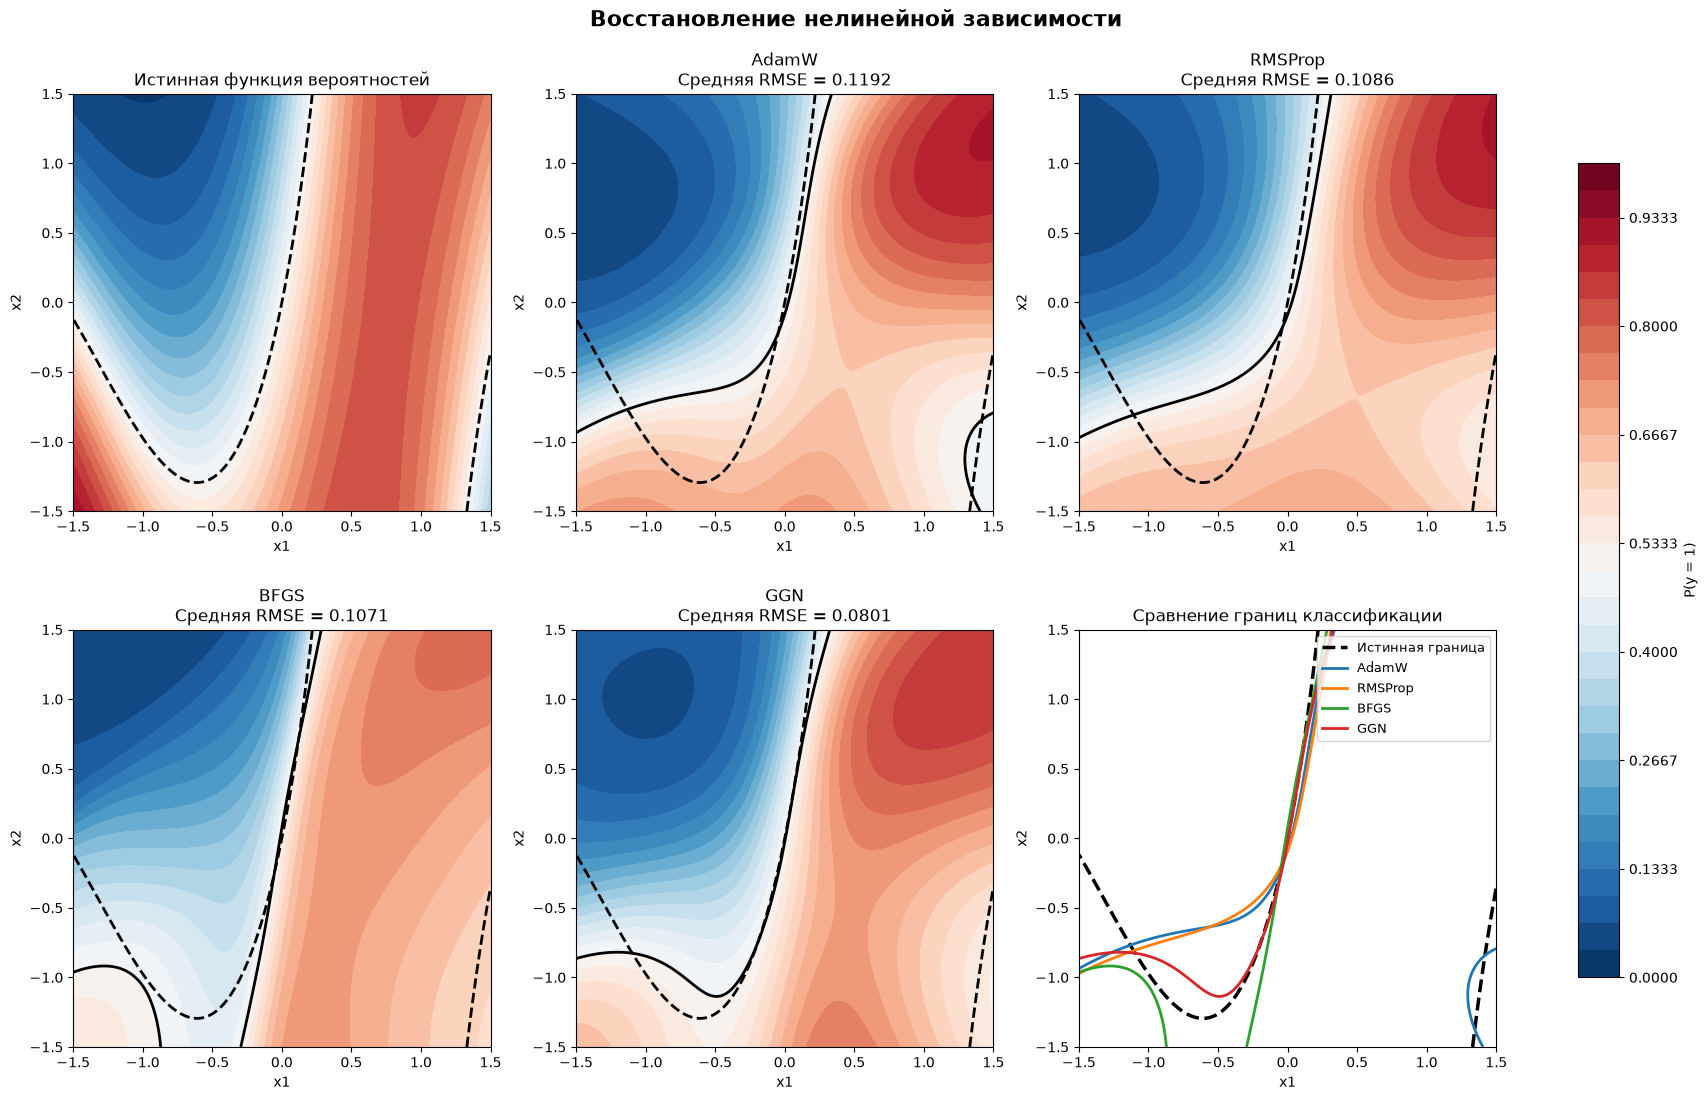

Пунктирная линия — истинная граница.
Сплошная линия — восстановленная граница.


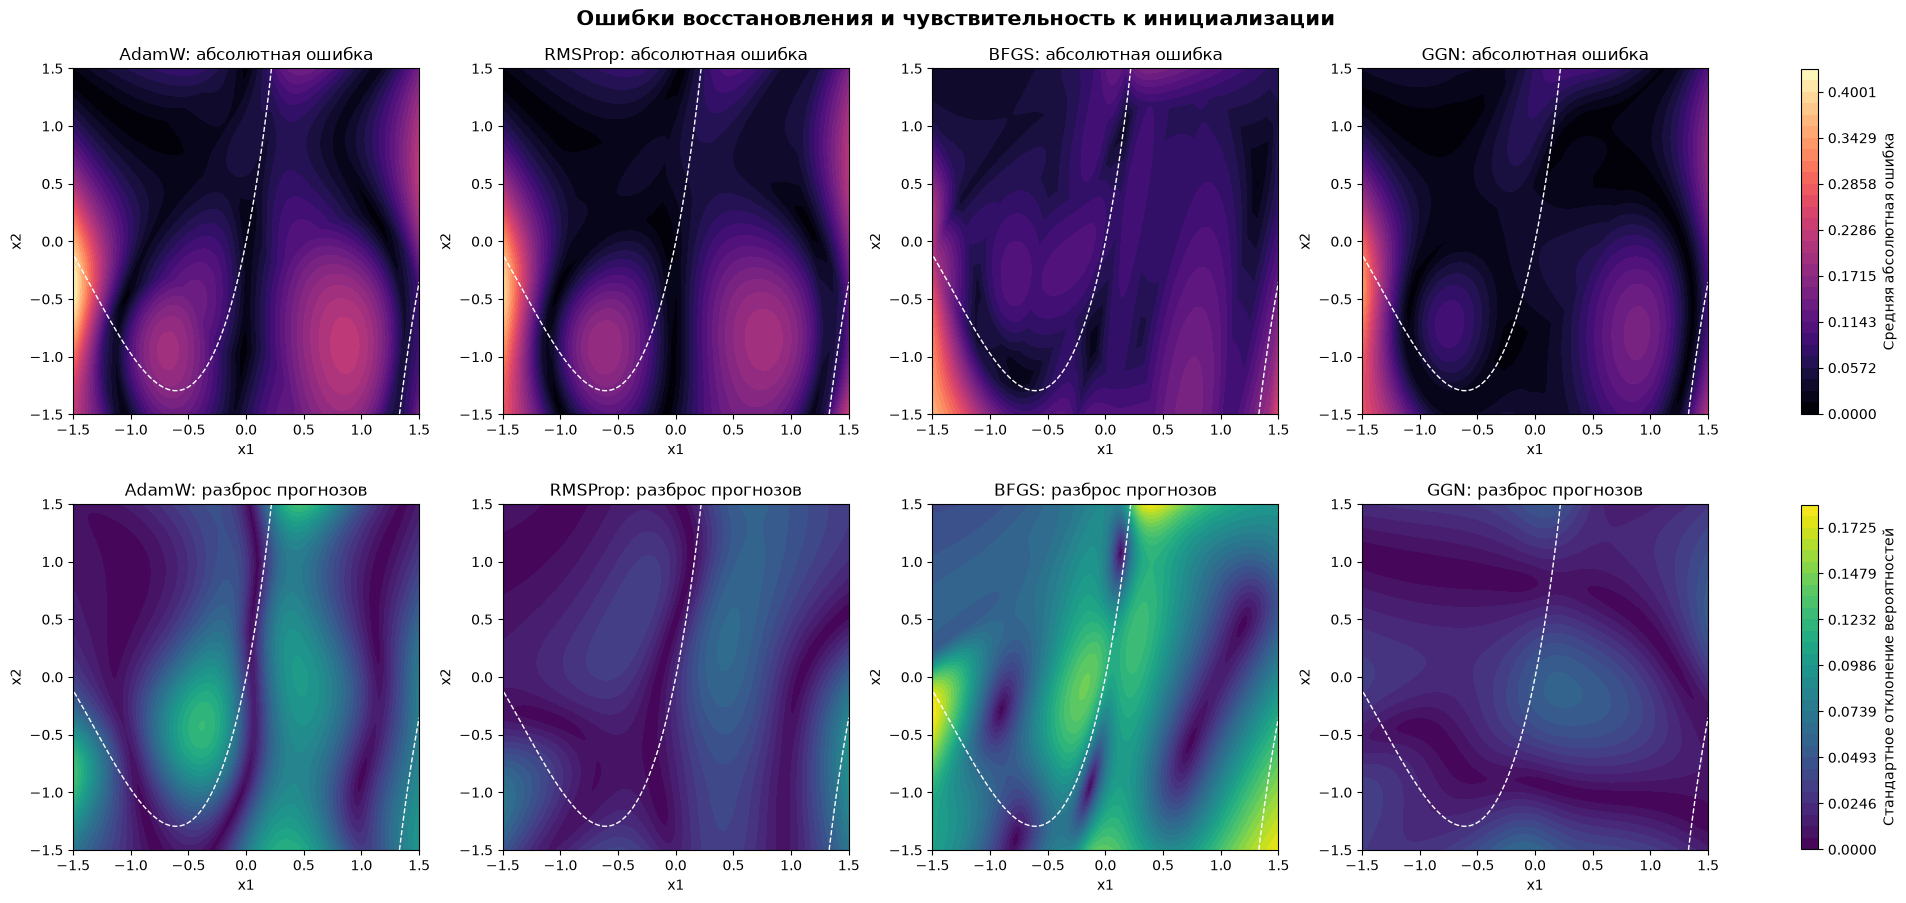


Сводные результаты восстановления зависимости:
Среднее ± выборочное стандартное отклонение


,AdamW,RMSProp,BFGS,GGN
RMSE вероятностей,0.11921987 ± 0.02523697,0.10864529 ± 0.01409123,0.10705650 ± 0.02018740,0.08011349 ± 0.00318978
MAE вероятностей,0.09411179 ± 0.02012878,0.08479175 ± 0.01391429,0.08617086 ± 0.01673006,0.05867770 ± 0.00329375
Максимальная ошибка,0.43615342 ± 0.07378344,0.40588836 ± 0.02033682,0.38880176 ± 0.09157231,0.34233538 ± 0.01507327
Совпадение классов,89.81% ± 2.36 п.п.,90.68% ± 1.56 п.п.,91.57% ± 2.75 п.п.,94.19% ± 0.63 п.п.
Ожидаемая BCE,0.57980345 ± 0.01388877,0.57201008 ± 0.00587130,0.57142619 ± 0.00707701,0.55745360 ± 0.00240936
Средняя KL-дивергенция,0.03935843 ± 0.01388877,0.03156506 ± 0.00587130,0.03098117 ± 0.00707701,0.01700857 ± 0.00240936



Количество точек координатной сетки: 62500
Минимальная ожидаемая BCE на сетке: 0.54044502

Лидеры по восстановлению исходной зависимости:


Критерий,Метод,Значение
Минимальная RMSE вероятностей,GGN,0.08011349
Минимальная MAE вероятностей,GGN,0.05867770
Максимальное совпадение классов,GGN,0.94190933
Минимальная KL-дивергенция,GGN,0.01700857



Все 12 выбранных моделей исследованы.
Параметры нейронных сетей не изменялись.
Координатная сетка использовалась только для итогового анализа.
Исследование восстановленных зависимостей завершено.


In [25]:
# =============================================
# Восстановление истинной функции вероятностей
# =============================================

grid_points = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

X_grid_tensor = torch.tensor(
    grid_points,
    dtype=torch.float64,
    device=device
)

true_grid_probabilities = P_grid.ravel()

# Энтропия истинного распределения Бернулли
true_grid_entropy = -(
    true_grid_probabilities
    * np.log(true_grid_probabilities)

    + (1 - true_grid_probabilities)
    * np.log(1 - true_grid_probabilities)
)

# Сохранение восстановленных поверхностей
probability_surfaces = {}

surface_records = []

for method in methods:

    probability_surfaces[method] = {}

    for network_seed in network_seeds:

        result = experiment_results[
            (method, network_seed)
        ]

        # Используем исключительно ранее выбранные параметры
        theta = result["best_theta"]

        with torch.no_grad():

            predicted_logits = forward_logits(
                theta,
                X_grid_tensor
            ).cpu().numpy().reshape(-1)

        predicted_probabilities = expit(
            predicted_logits
        )

        probability_surfaces[method][network_seed] = (
            predicted_probabilities.reshape(P_grid.shape)
        )

        # Ошибка восстановления истинных вероятностей
        errors = (
            predicted_probabilities
            - true_grid_probabilities
        )

        rmse = np.sqrt(
            np.mean(errors ** 2)
        )

        mae = np.mean(
            np.abs(errors)
        )

        max_error = np.max(
            np.abs(errors)
        )

        # Согласованность с теоретическим классификатором
        boundary_agreement = np.mean(
            (predicted_probabilities >= 0.5)
            == (true_grid_probabilities >= 0.5)
        )

        # Ожидаемая кросс-энтропия при истинных вероятностях
        # Используются вероятности генератора,
        # а не случайно сгенерированные классы
        expected_cross_entropy = (
            np.logaddexp(0, predicted_logits)
            - true_grid_probabilities * predicted_logits
        )

        # KL-дивергенция между истинным и предсказанным
        # распределениями Бернулли
        mean_kl = np.mean(
            expected_cross_entropy
            - true_grid_entropy
        )

        # Проверки численной корректности
        assert np.isfinite(
            predicted_probabilities
        ).all()

        assert np.all(
            (predicted_probabilities >= 0)
            & (predicted_probabilities <= 1)
        )

        assert mean_kl >= -1e-12

        surface_records.append({
            "method": method,

            "seed": network_seed,

            "best_iteration": (
                result["best_record"]["iteration"]
            ),

            "probability_rmse": rmse,

            "probability_mae": mae,

            "maximum_absolute_error": max_error,

            "boundary_agreement": boundary_agreement,

            "expected_cross_entropy": (
                expected_cross_entropy.mean()
            ),

            "mean_kl_divergence": mean_kl
        })


surface_df = pd.DataFrame(
    surface_records
)

surface_df["method"] = pd.Categorical(
    surface_df["method"],
    categories=methods,
    ordered=True
)

assert len(surface_df) == 12


# =============================================
# Индивидуальные результаты восстановления
# =============================================

surface_columns = {
    "method": "Метод",

    "seed": "Seed",

    "best_iteration": "Лучшая итерация",

    "probability_rmse": "RMSE вероятностей",

    "probability_mae": "MAE вероятностей",

    "maximum_absolute_error": "Максимальная ошибка",

    "boundary_agreement": "Совпадение классов",

    "expected_cross_entropy": "Ожидаемая BCE",

    "mean_kl_divergence": "Средняя KL-дивергенция"
}

print("Восстановление истинной функции вероятностей:")

display(
    surface_df
    .rename(columns=surface_columns)
    .style
    .hide(axis="index")
    .format({
        "RMSE вероятностей": "{:.8f}",
        "MAE вероятностей": "{:.8f}",
        "Максимальная ошибка": "{:.8f}",
        "Совпадение классов": "{:.2%}",
        "Ожидаемая BCE": "{:.8f}",
        "Средняя KL-дивергенция": "{:.8f}"
    })
)


# =============================================
# Средние поверхности вероятностей
# =============================================

mean_probability_surfaces = {}

std_probability_surfaces = {}

for method in methods:

    surfaces = np.stack([
        probability_surfaces[method][network_seed]
        for network_seed in network_seeds
    ])

    mean_probability_surfaces[method] = (
        surfaces.mean(axis=0)
    )

    std_probability_surfaces[method] = (
        surfaces.std(axis=0, ddof=1)
    )


# =============================================
# Сравнение восстановленных поверхностей
# =============================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 11),
    constrained_layout=True
)

levels = np.linspace(0, 1, 31)

# Истинная функция вероятностей
contour = axes[0, 0].contourf(
    X1_grid,
    X2_grid,
    P_grid,
    levels=levels,
    cmap="RdBu_r"
)

axes[0, 0].contour(
    X1_grid,
    X2_grid,
    P_grid,
    levels=[0.5],
    colors="black",
    linewidths=2,
    linestyles="--"
)

axes[0, 0].set_title(
    "Истинная функция вероятностей"
)

# Средние поверхности четырёх методов
for ax, method in zip(
    axes.flat[1:5],
    methods
):

    mean_surface = mean_probability_surfaces[method]

    ax.contourf(
        X1_grid,
        X2_grid,
        mean_surface,
        levels=levels,
        cmap="RdBu_r"
    )

    # Истинная граница классификации
    ax.contour(
        X1_grid,
        X2_grid,
        P_grid,
        levels=[0.5],
        colors="black",
        linewidths=2,
        linestyles="--"
    )

    # Граница средней восстановленной поверхности
    ax.contour(
        X1_grid,
        X2_grid,
        mean_surface,
        levels=[0.5],
        colors="black",
        linewidths=2,
        linestyles="-"
    )

    mean_rmse = surface_df.loc[
        surface_df["method"] == method,
        "probability_rmse"
    ].mean()

    ax.set_title(
        f"{method}\n"
        f"Средняя RMSE = {mean_rmse:.4f}"
    )


# Наложение восстановленных границ
ax = axes[1, 2]

ax.contour(
    X1_grid,
    X2_grid,
    P_grid,
    levels=[0.5],
    colors="black",
    linewidths=2.5,
    linestyles="--"
)

ax.plot(
    [],
    [],
    color="black",
    linestyle="--",
    linewidth=2.5,
    label="Истинная граница"
)

for method in methods:

    ax.contour(
        X1_grid,
        X2_grid,
        mean_probability_surfaces[method],
        levels=[0.5],
        colors=method_colors[method],
        linewidths=2
    )

    ax.plot(
        [],
        [],
        color=method_colors[method],
        linewidth=2,
        label=method
    )

ax.set_title(
    "Сравнение границ классификации"
)

ax.legend(
    loc="upper right",
    fontsize=9
)

for ax in axes.flat:

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)

    ax.set_aspect("equal")

fig.colorbar(
    contour,
    ax=list(axes.flat[:5]),
    label="P(y = 1)",
    shrink=0.8
)

fig.suptitle(
    "Восстановление нелинейной зависимости",
    fontsize=16,
    fontweight="bold"
)

plt.show()

print(
    "Пунктирная линия — истинная граница."
)

print(
    "Сплошная линия — восстановленная граница."
)


# =============================================
# Пространственное распределение ошибок
# =============================================

fig, axes = plt.subplots(
    2, 4,
    figsize=(19, 9),
    constrained_layout=True
)

# Средняя абсолютная ошибка по трём моделям
mean_absolute_error_surfaces = {}

for method in methods:

    individual_errors = np.stack([
        np.abs(
            probability_surfaces[method][network_seed]
            - P_grid
        )
        for network_seed in network_seeds
    ])

    mean_absolute_error_surfaces[method] = (
        individual_errors.mean(axis=0)
    )

# Общие шкалы для корректного сравнения
error_max = max(
    surface.max()
    for surface in mean_absolute_error_surfaces.values()
)

std_max = max(
    surface.max()
    for surface in std_probability_surfaces.values()
)

error_levels = np.linspace(
    0,
    max(error_max, 1e-12),
    31
)

std_levels = np.linspace(
    0,
    max(std_max, 1e-12),
    31
)

for column, method in enumerate(methods):

    # Ошибка восстановления вероятностей
    error_plot = axes[0, column].contourf(
        X1_grid,
        X2_grid,
        mean_absolute_error_surfaces[method],
        levels=error_levels,
        cmap="magma"
    )

    axes[0, column].set_title(
        f"{method}: абсолютная ошибка"
    )

    # Разброс прогнозов между инициализациями
    std_plot = axes[1, column].contourf(
        X1_grid,
        X2_grid,
        std_probability_surfaces[method],
        levels=std_levels,
        cmap="viridis"
    )

    axes[1, column].set_title(
        f"{method}: разброс прогнозов"
    )

for ax in axes.flat:

    ax.contour(
        X1_grid,
        X2_grid,
        P_grid,
        levels=[0.5],
        colors="white",
        linestyles="--",
        linewidths=1
    )

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

    ax.set_aspect("equal")

fig.colorbar(
    error_plot,
    ax=list(axes[0]),
    label="Средняя абсолютная ошибка",
    shrink=0.85
)

fig.colorbar(
    std_plot,
    ax=list(axes[1]),
    label="Стандартное отклонение вероятностей",
    shrink=0.85
)

fig.suptitle(
    "Ошибки восстановления и чувствительность к инициализации",
    fontsize=15,
    fontweight="bold"
)

plt.show()


# =============================================
# Сводная статистика восстановления зависимости
# =============================================

surface_metrics = {
    "probability_rmse": "RMSE вероятностей",

    "probability_mae": "MAE вероятностей",

    "maximum_absolute_error": "Максимальная ошибка",

    "boundary_agreement": "Совпадение классов",

    "expected_cross_entropy": "Ожидаемая BCE",

    "mean_kl_divergence": "Средняя KL-дивергенция"
}

surface_stats = (
    surface_df
    .groupby("method", observed=True)[list(surface_metrics)]
    .agg(["mean", "std"])
)

surface_summary = pd.DataFrame(
    index=list(surface_metrics.values()),
    columns=methods,
    dtype=object
)

for metric, label in surface_metrics.items():

    for method in methods:

        mean_value = surface_stats.loc[
            method, (metric, "mean")
        ]

        std_value = surface_stats.loc[
            method, (metric, "std")
        ]

        if metric == "boundary_agreement":

            formatted = (
                f"{mean_value:.2%} ± "
                f"{std_value * 100:.2f} п.п."
            )

        else:

            formatted = (
                f"{mean_value:.8f} ± {std_value:.8f}"
            )

        surface_summary.loc[label, method] = formatted

print("\nСводные результаты восстановления зависимости:")

print("Среднее ± выборочное стандартное отклонение")

display(surface_summary)


# =============================================
# Итоговые ориентиры
# =============================================

print(
    "\nКоличество точек координатной сетки:",
    len(grid_points)
)

print(
    "Минимальная ожидаемая BCE на сетке:",
    f"{true_grid_entropy.mean():.8f}"
)

surface_leaders = pd.DataFrame([
    {
        "Критерий": "Минимальная RMSE вероятностей",

        "Метод": surface_stats[
            ("probability_rmse", "mean")
        ].idxmin(),

        "Значение": surface_stats[
            ("probability_rmse", "mean")
        ].min()
    },

    {
        "Критерий": "Минимальная MAE вероятностей",

        "Метод": surface_stats[
            ("probability_mae", "mean")
        ].idxmin(),

        "Значение": surface_stats[
            ("probability_mae", "mean")
        ].min()
    },

    {
        "Критерий": "Максимальное совпадение классов",

        "Метод": surface_stats[
            ("boundary_agreement", "mean")
        ].idxmax(),

        "Значение": surface_stats[
            ("boundary_agreement", "mean")
        ].max()
    },

    {
        "Критерий": "Минимальная KL-дивергенция",

        "Метод": surface_stats[
            ("mean_kl_divergence", "mean")
        ].idxmin(),

        "Значение": surface_stats[
            ("mean_kl_divergence", "mean")
        ].min()
    }
])

print("\nЛидеры по восстановлению исходной зависимости:")

display(
    surface_leaders.style
    .hide(axis="index")
    .format({
        "Значение": "{:.8f}"
    })
)

print("\nВсе 12 выбранных моделей исследованы.")

print("Параметры нейронных сетей не изменялись.")

print(
    "Координатная сетка использовалась только "
    "для итогового анализа."
)

print("Исследование восстановленных зависимостей завершено.")

## Итоговые выводы

В ходе практической работы проведено сравнение
четырёх методов оптимизации нейронной сети:
AdamW, RMSProp, BFGS и Generalized Gauss–Newton.

Для исследования использована синтетическая
выборка из 420 наблюдений с нелинейной
зависимостью между входными признаками
и вероятностью принадлежности к классу.

Обучалась нейронная сеть архитектуры 2 → 8 → 1,
содержащая 33 параметра.

Для каждого метода выполнено три независимых
запуска с seed инициализации 1, 2 и 3.
Внутри каждого повторения начальные параметры
сети совпадали для всех оптимизаторов.

Всего проведено 12 основных запусков
и 1200 внешних итераций.

## 1. Корректность реализации методов

Перед основным экспериментом выполнены
контрольные проверки:

- сравнение аналитического якобиана
  с автоматическим дифференцированием;
- проверка полного градиента методом
  центральных разностей;
- сравнение AdamW и RMSProp
  с библиотечными реализациями PyTorch;
- проверка обратного обновления BFGS,
  условия секущей и положительной определённости;
- проверка матрицы GGN и точности решения
  регуляризованной линейной системы;
- проверка условия Армихо;
- проверка совпадения траекторий при измерении
  вычислительного времени и памяти.

Все контрольные проверки пройдены.

В основном эксперименте принято 1200
из 1200 внешних шагов.

Из 1202 пробных обновлений две попытки BFGS
были отклонены по условию Армихо, после чего
найдены допустимые значения шага.

Нечисловых значений и численной расходимости
не обнаружено.

## 2. Сравнение качества оптимизации

Средние результаты после 100 внешних итераций:

| Метод | Train loss | Validation loss | Норма градиента |
|---|---:|---:|---:|
| AdamW | 0.508474 | 0.585203 | 0.012269 |
| RMSProp | 0.506443 | 0.583164 | 0.029932 |
| BFGS | 0.422383 | 0.687313 | 0.009900 |
| GGN | 0.435543 | 0.669518 | 0.003218 |

Наибольшее уменьшение обучающей функции потерь
обеспечил BFGS.

Среднее относительное уменьшение train loss:

- AdamW — 27.84%;
- RMSProp — 28.06%;
- BFGS — 39.92%;
- GGN — 38.07%.

Методы второго порядка эффективнее уменьшали
обучающую функцию потерь при одинаковом
количестве внешних итераций.

Это связано с использованием информации
о кривизне целевой функции при формировании
направления обновления параметров.

GGN показал минимальную конечную норму
полного градиента:

$$
\|\nabla L_{\mathrm{train}}\|_2
\approx 0.003218.
$$

Следовательно, по данному критерию GGN
оказался ближе к выполнению необходимого
условия стационарности первого порядка.

Однако малая норма градиента сама по себе
не гарантирует достижения глобального минимума
невыпуклой функции потерь.

## 3. Анализ информации о кривизне

В ходе контрольного эксперимента установлено,
что точная матрица Гессе во всех трёх
начальных точках имеет отрицательные
собственные значения.

Минимальные собственные значения Гессе:

| Seed | Минимальное собственное значение |
|---:|---:|
| 1 | -0.238934 |
| 2 | -0.198556 |
| 3 | -0.171340 |

Таким образом, локальная кривизна функции
потерь не является положительно полуопределённой
во всех исследованных начальных точках.

Метод GGN использует приближение:

$$
G_t=\frac{1}{n}J_t^TD_tJ_t,
$$

где

$$
D_t=\operatorname{diag}
\left(\hat p_i(1-\hat p_i)\right).
$$

Добавление регуляризующего слагаемого

$$
A_t=G_t+\mu I,\qquad \mu=0.1
$$

обеспечивает положительную определённость
матрицы линейной системы.

Направление GGN определяется выражением:

$$
d_t=-(G_t+\mu I)^{-1}g_t.
$$

Для ненулевого градиента выполняется:

$$
g_t^Td_t=
-g_t^T(G_t+\mu I)^{-1}g_t<0.
$$

Следовательно, полученное направление
является направлением спуска.

BFGS формирует направление с использованием
обратной аппроксимации Гессе:

$$
d_t=-H_tg_t.
$$

За три основных запуска BFGS выполнил
300 успешных обновлений обратной аппроксимации.

Недопустимых пар кривизны в основных
запусках не обнаружено.

Использование поиска Армихо обеспечило
невозрастание обучающей функции потерь
для BFGS и GGN на всех принятых шагах.

## 4. Качество обобщения и переобучение

Минимальные валидационные потери и соответствующие
итерации представлены в таблице.

| Метод | Лучший validation loss | Лучшая итерация |
|---|---:|---:|
| AdamW | 0.583786 ± 0.005757 | 94.00 ± 7.94 |
| RMSProp | 0.581702 ± 0.008343 | 89.67 ± 17.04 |
| BFGS | 0.591971 ± 0.013429 | 16.33 ± 5.51 |
| GGN | 0.572927 ± 0.000533 | 15.33 ± 0.58 |

Значения представлены в формате
«среднее ± выборочное стандартное отклонение».

Наилучший средний минимум валидационной
функции потерь получен методом GGN.

При этом продолжение обучения методов
второго порядка после достижения минимальных
валидационных потерь приводило к ухудшению
качества вероятностных прогнозов на валидации.

Для анализа использовалась разность:

$$
\Delta L_t=
L_{\mathrm{val}}(\theta_t)
-L_{\mathrm{train}}(\theta_t).
$$

После 100 итераций получены следующие
средние значения разрыва потерь:

| Метод | Разрыв потерь |
|---|---:|
| AdamW | 0.076728 |
| RMSProp | 0.076721 |
| BFGS | 0.264929 |
| GGN | 0.233976 |

Наиболее выраженные признаки переобучения
наблюдаются у BFGS и GGN.

Например, при seed = 1 метод BFGS уменьшил
train loss с 0.750621 до 0.416891.

Однако validation loss после 100 итераций
составил 0.721620, что превышает начальное
значение 0.716835.

Таким образом, успешная минимизация обучающей
функции потерь не гарантирует улучшения
качества обобщения.

При этом ухудшение валидационной BCE
не обязательно сопровождается уменьшением
accuracy, поскольку эти метрики характеризуют
различные свойства прогнозов.

Для итоговой оценки использовалось состояние
сети, выбранное по минимальному validation loss:

$$
t^*=
\arg\min_{t\in\{0,\ldots,100\}}
L_{\mathrm{val}}(\theta_t).
$$

Все методы выполнили предусмотренные заданием
100 внешних итераций.

Выбор лучшего сохранённого состояния выполнялся
после завершения обучения и не сокращал
установленный бюджет эксперимента.

## 5. Сравнение вычислительных затрат

Средние вычислительные затраты за 100 итераций:

| Показатель | AdamW | RMSProp | BFGS | GGN |
|---|---:|---:|---:|---:|
| Основные вычисления loss | 101.00 | 101.00 | 201.67 | 201.00 |
| Основные градиенты | 101 | 101 | 101 | 101 |
| Пробы Армихо | 0 | 0 | 100.67 | 100 |
| Обновления BFGS | 0 | 0 | 100 | 0 |
| Сборки GGN | 0 | 0 | 0 | 100 |
| Факторизации | 0 | 0 | 0 | 100 |
| Решения линейных систем | 0 | 0 | 0 | 100 |
| Время оптимизации, мс | 36.42 | 34.24 | 50.00 | 74.30 |
| Пиковая память PyTorch, КиБ | 57.27 | 56.76 | 65.52 | 191.41 |

Количество основных вычислений градиента
включает начальное вычисление и градиенты
в принятых состояниях, включая последнее.

Дополнительные вычисления функции потерь
у BFGS и GGN связаны с поиском Армихо.

GGN также выполняет построение якобиана,
сборку матрицы кривизны, разложение Холецкого
и решение линейной системы.

Наименьшие вычислительные затраты за полный
бюджет обучения показал RMSProp.

Среднее время его работы:

$$
T_{\mathrm{RMSProp}}
=34.2406\pm1.9534\text{ мс}.
$$

Наибольшее время потребовалось методу GGN:

$$
T_{\mathrm{GGN}}
=74.3011\pm1.5263\text{ мс}.
$$

Таким образом, выполнение 100 итераций GGN
в данном эксперименте приблизительно
в 2.17 раза дороже по времени,
чем выполнение 100 итераций RMSProp.

## 6. Скорость достижения заданного качества

До проведения основного эксперимента
был установлен единый контрольный уровень:

$$
L_{\mathrm{val}}\leq0.60.
$$

Получены следующие результаты:

| Метод | Успешные запуски | Итерации до порога | Время, мс |
|---|---:|---:|---:|
| AdamW | 3/3 | 55.33 ± 10.02 | 20.30 ± 4.11 |
| RMSProp | 3/3 | 53.00 ± 4.36 | 18.49 ± 1.44 |
| BFGS | 2/3 | 14.00 ± 5.66 | 7.94 ± 1.16 |
| GGN | 3/3 | 8.00 ± 1.73 | 6.49 ± 1.85 |

Средние значения рассчитаны только
по запускам, достигшим контрольного уровня.

BFGS при третьей инициализации не достиг
установленного порога за 100 итераций.

Среди методов, достигших заданного качества
во всех трёх повторениях, GGN оказался
лучшим одновременно:

- по количеству внешних итераций;
- по количеству вычислений полного градиента;
- по измеренному времени оптимизации.

Для достижения порога GGN в среднем потребовал
17 вычислений обучающей функции потерь,
9 вычислений полного градиента, 8 построений
якобиана и 8 сборок матрицы кривизны.

Несмотря на более высокую стоимость одной
итерации, использование информации о кривизне
позволило GGN сократить суммарное время
достижения установленного качества.

В рассматриваемом эксперименте лидеры
по числу итераций и времени достижения
порога совпали.

При этом лидер по времени выполнения полного
бюджета из 100 итераций — RMSProp.

Следовательно, эффективность оптимизатора
зависит от выбранного критерия остановки
и цели вычислительного эксперимента.

## 7. Анализ вычислительной памяти

Постоянное числовое состояние AdamW
содержит два вектора моментов:

$$
2\cdot33\cdot8=528\text{ байт}.
$$

RMSProp хранит один вектор накопленной
статистики:

$$
33\cdot8=264\text{ байта}.
$$

BFGS хранит полную обратную аппроксимацию
матрицы Гессе:

$$
33^2\cdot8=8712\text{ байт}.
$$

GGN не хранит накопленную матрицу кривизны
между внешними итерациями, но использует
дополнительные временные структуры.

Только якобиан логитов содержит:

$$
294\cdot33=9702
$$

числовых элемента и занимает 77616 байт.

Наибольшая зарегистрированная пиковая
дополнительная память PyTorch получена
для GGN — 191.41 КиБ.

Это приблизительно в 3.37 раза больше,
чем у RMSProp.

Таким образом, отсутствие постоянного
состояния кривизны не означает отсутствия
дополнительных затрат памяти.

Для методов первого порядка объём
постоянного числового состояния имеет
линейную зависимость от числа параметров.

Для BFGS эта зависимость квадратичная.

GGN дополнительно требует хранения якобиана
и матричных структур размерности,
зависящей от числа наблюдений и параметров.

Измеренная память характеризует выделения,
зарегистрированные профилировщиком PyTorch,
а не полный объём оперативной памяти процесса.

Память Python измерялась отдельно
и не суммировалась с памятью PyTorch.

## 8. Итоговое качество классификации

Тестовая выборка использовалась только
после завершения оптимизации и выбора
лучших состояний сети по валидации.

Получены следующие результаты:

| Метод | Test loss | Accuracy | F1-macro | ROC-AUC |
|---|---:|---:|---:|---:|
| AdamW | 0.574194 | 76.19% | 0.761665 | 0.777552 |
| RMSProp | 0.574568 | 76.72% | 0.767137 | 0.772819 |
| BFGS | 0.547411 | 78.84% | 0.787165 | 0.827586 |
| GGN | 0.521524 | 79.37% | 0.793616 | 0.853955 |

Наилучшие средние значения всех четырёх
тестовых метрик получены методом GGN.

Его результаты по трём инициализациям:

$$
L_{\mathrm{test}}
=0.521524\pm0.004593,
$$

$$
\operatorname{Accuracy}
=79.37\%\pm1.59\text{ п.п.},
$$

$$
F1_{\mathrm{macro}}
=0.793616\pm0.015877,
$$

$$
\operatorname{ROC\text{-}AUC}
=0.853955\pm0.004648.
$$

BFGS в двух отдельных повторениях достиг
accuracy 82.54%, однако при третьей
инициализации результат составил 71.43%.

Стандартное отклонение accuracy у BFGS
составило 6.42 процентного пункта.

Это указывает на большую чувствительность
результатов BFGS к исследованным
начальным инициализациям.

Все четыре метода превзошли базовый
классификатор, использующий постоянную
вероятность, равную частоте положительного
класса в обучающей выборке.

Его accuracy составила 53.97%,
а ROC-AUC — 0.5.

Истинная функция вероятностей обеспечила
на тестовой выборке следующие результаты:

- Test loss — 0.490934;
- Accuracy — 77.78%;
- F1-macro — 0.777722;
- ROC-AUC — 0.868154.

Средняя accuracy GGN оказалась выше accuracy
истинного классификатора на конкретной
реализации тестовой выборки.

Однако это не означает превосходства
нейросети над байесовским классификатором
по ожидаемому качеству.

В силу случайной генерации бинарных меток
эмпирические результаты могут отличаться
от теоретических ожидаемых значений.

При этом истинная функция вероятностей
сохранила преимущество по BCE и ROC-AUC.

## 9. Восстановление исходной зависимости

Дополнительно проведено сравнение восстановленных
вероятностей с истинной функцией генерации
на координатной сетке из 62500 точек.

| Метод | RMSE вероятностей | MAE вероятностей | Совпадение классов | KL-дивергенция |
|---|---:|---:|---:|---:|
| AdamW | 0.119220 | 0.094112 | 89.81% | 0.039358 |
| RMSProp | 0.108645 | 0.084792 | 90.68% | 0.031565 |
| BFGS | 0.107057 | 0.086171 | 91.57% | 0.030981 |
| GGN | 0.080113 | 0.058678 | 94.19% | 0.017009 |

Наилучшее восстановление исходной зависимости
получено методом GGN.

Средняя RMSE вероятностей составила:

$$
\operatorname{RMSE}_p
=0.080113\pm0.003190.
$$

Средняя доля совпадения с теоретическими
классами:

$$
94.19\%\pm0.63\text{ п.п.}
$$

Данный показатель характеризует совпадение
классов, полученных из предсказанных
и истинных вероятностей при пороге 0.5.

Он не является accuracy относительно
случайно сгенерированных бинарных меток.

Минимальная средняя KL-дивергенция
также получена для GGN:

$$
D_{\mathrm{KL}}
=0.017009\pm0.002409.
$$

Для распределений Бернулли справедливо:

$$
\operatorname{BCE}(p,\hat p)
=H(p)+D_{\mathrm{KL}}(p\parallel\hat p),
$$

где $H(p)$ — энтропия истинного распределения.

Минимальная ожидаемая BCE на координатной
сетке составила 0.54044502.

GGN достиг средней ожидаемой BCE 0.55745360,
что соответствует небольшому по сравнению
с остальными методами отклонению от истинного
распределения вероятностей.

Визуализация показала, что ни один
из оптимизаторов не обеспечил полного
восстановления нелинейной границы классов.

Наиболее заметные ошибки сохраняются
в отдельных областях около нижней
и боковых границ пространства признаков.

Однако GGN лучше остальных восстановил
форму основной нелинейной границы
и показал небольшой разброс вероятностей
между тремя инициализациями.

Координатная сетка использовалась исключительно
для дополнительного итогового анализа,
а не для обучения или выбора параметров.

## 10. Сводное сравнение методов

| Критерий | Лучший метод |
|---|---|
| Минимальные обучающие потери после 100 шагов | BFGS |
| Минимальные валидационные потери после 100 шагов | RMSProp |
| Минимальный средний лучший validation loss | GGN |
| Минимальная конечная норма градиента | GGN |
| Минимальное число итераций до порога | GGN |
| Минимальное время достижения порога | GGN |
| Минимальное время 100 итераций | RMSProp |
| Минимальная зарегистрированная память PyTorch | RMSProp |
| Минимальный средний Test loss | GGN |
| Максимальные средние Accuracy и F1-macro | GGN |
| Максимальный средний ROC-AUC | GGN |
| Наиболее точное восстановление вероятностей | GGN |

## 11. Ограничения исследования

Полученные результаты относятся к конкретной
синтетической задаче, заданной архитектуре,
фиксированным гиперпараметрам и трём начальным
инициализациям.

Использовалось одно разбиение исходной выборки,
а тестовая часть содержала 63 наблюдения.

Стандартные отклонения характеризуют разброс
результатов между инициализациями, но не
неопределённость, связанную с генерацией
новых наборов данных.

Статистическая значимость различий
между оптимизаторами не устанавливалась.

Измерения времени зависят от оборудования,
вычислительной среды, реализации алгоритмов
и текущей нагрузки на процессор.

Кроме того, время оптимизации до достижения
порога не включает вычисление валидационных
метрик и сохранение подробной истории.
Полное время измерялось отдельно.

Результаты для сети из 33 параметров нельзя
непосредственно переносить на нейронные сети
большой размерности.

При увеличении количества параметров
вычислительная стоимость хранения и обработки
матриц кривизны становится более существенной.

## Заключение

В результате исследования установлено,
что методы первого и второго порядка
имеют различные преимущества.

AdamW и RMSProp требуют меньших вычислительных
затрат на выполнение полного бюджета обучения.
Они постепенно уменьшают функцию потерь
и показывают менее выраженные признаки
переобучения за 100 итераций.

BFGS обеспечивает наиболее эффективную
минимизацию обучающей функции потерь,
однако демонстрирует существенное увеличение
разрыва между обучающими и валидационными
потерями и большую зависимость итогового
качества от инициализации.

Generalized Gauss–Newton показал наиболее
удачное сочетание скорости достижения
заданного качества, устойчивости к исследованным
инициализациям и итогового качества классификации.

Несмотря на повышенные затраты памяти
и более высокую стоимость отдельной итерации,
GGN достиг контрольного уровня быстрее
остальных методов.

После выбора параметров по минимальной
валидационной функции потерь GGN также
обеспечил наилучшие средние тестовые метрики
и наиболее точное восстановление исходной
нелинейной зависимости.

Таким образом, в условиях проведённого
эксперимента использование информации
о кривизне оказалось вычислительно оправданным
при ограничении на требуемое качество.

При этом минимизация обучающей функции потерь,
вычислительная эффективность и качество
обобщения являются различными критериями,
которые необходимо рассматривать совместно.

Цель практической работы достигнута.